# Task B Final Notebook: 7-Day Alert for Entering GSTD 5

This notebook is the cleaned final technical deliverable for **Task B**. The goal is to build and evaluate a model that alerts when an observation is likely to enter **GSTD 5 within the next 7 days**.

The final modeling frame focuses on the **GSTD 1 at-risk subset**, because the label audit showed that GSTD 3 is deterministic in this dataset and many other stages create trivial negatives. This makes the model evaluation more honest and more useful for client handoff.

The main recommended model is the **Client-Feasible TS LightGBM**, which uses the client-feasible variables plus lagged and rolling time-series features derived from those same inputs. LAID is tested later as a sensitivity check. The LAID + TS version performs almost the same and can be treated as an optional variant if LAID is reliably available in the client's future data pipeline.

**Dataset expected by this notebook:** `final_validated_dataset.csv`

The notebook will first look for the dataset in the same folder as the notebook. If it is not there, it will also check common handoff locations such as `../02_Data/final_validated_dataset.csv`.


In [1]:
# ============================================================
# SECTION 1: IMPORTS AND LOAD DATA
# ============================================================


import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from pathlib import Path

# Make notebook tables easier to read when someone opens the file later.
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 140)

# Small helper so year lists print like normal Python integers instead of np.int64 values.
def clean_year_list(values):
    return [int(v) for v in sorted(pd.Series(values).dropna().unique())]

# Use the final cleaned dataset for the handoff package.
# The first option works if the dataset is stored beside this notebook.
# The second option works if the notebook is inside 03_Final_Notebooks and the data is in 02_Data.
DATA_PATH_CANDIDATES = [
    Path("final_validated_dataset.csv"),
    Path("../02_Data/final_validated_dataset.csv"),
    Path("02_Data/final_validated_dataset.csv"),
]

DATA_PATH = next((path for path in DATA_PATH_CANDIDATES if path.exists()), None)

if DATA_PATH is None:
    checked_paths = "\n".join(str(path) for path in DATA_PATH_CANDIDATES)
    raise FileNotFoundError(
        "Could not find final_validated_dataset.csv. "
        "Place the dataset in the same folder as this notebook or in ../02_Data/.\n"
        f"Checked these paths:\n{checked_paths}"
    )

# Load the dataset.
df = pd.read_csv(DATA_PATH)

# Make sure DATE is treated as a datetime column before any time-based logic.
df["DATE"] = pd.to_datetime(df["DATE"], errors="coerce")

print("Dataset loaded successfully.")
print(f"Dataset path: {DATA_PATH}")
print(f"Shape: {df.shape}")
print(f"Unique RUNNO: {df['RUNNO'].nunique()}")
print(f"Unique TRTNO: {df['TRTNO'].nunique()}")

print("\nFirst 10 columns:")
print(df.columns[:10].tolist())

print("\nKey columns check:")
print(df[["RUNNO", "TRTNO", "TRTNA", "DATE", "DAP", "GSTD"]].head())


Dataset loaded successfully.
Dataset path: ..\02_Data\final_validated_dataset.csv
Shape: (135240, 141)
Unique RUNNO: 980
Unique TRTNO: 35

First 10 columns:
['YEAR', 'DOY', 'DAS', 'DAP', 'L#SD', 'GSTD', 'LAID', 'LWAD', 'SWAD', 'GWAD']

Key columns check:
   RUNNO  TRTNO       TRTNA       DATE  DAP  GSTD
0      1      1  100%UAN_CT 2023-05-02    0     0
1      1      1  100%UAN_CT 2023-05-03    1     0
2      1      1  100%UAN_CT 2023-05-04    2     0
3      1      1  100%UAN_CT 2023-05-05    3     0
4      1      1  100%UAN_CT 2023-05-06    4     0


In [2]:
# ============================================================
# SECTION 2: SORT DATA AND CREATE 7-DAY STAGE-5 TARGET
# ============================================================


# sort so all forward-looking logic is correct within each run
df = df.sort_values(["RUNNO", "DATE", "DAP"]).reset_index(drop=True)

# Create the 7-day alert target.
# y_enter5_7 is 1 when GSTD becomes 5 within the next 7 days.
# Rows already in GSTD 5 are not counted as new entries.
def create_y_enter5_7(group):
    group = group.sort_values(["DATE", "DAP"]).copy()
    gstd_vals = group["GSTD"].to_numpy()
    y = np.zeros(len(group), dtype=int)
    
    for i in range(len(group)):
        current_stage = gstd_vals[i]
        
        # If the row is already in GSTD 5, this is not a new 7-day entry.
        if current_stage == 5:
            y[i] = 0
            continue
        
        # Look ahead up to the next 7 rows/days within the same run.
        future_vals = gstd_vals[i+1:i+8]
        y[i] = int(5 in future_vals)
    
    group["y_enter5_7"] = y
    return group

df = (
    df.groupby("RUNNO", group_keys=False)
      .apply(create_y_enter5_7)
      .reset_index(drop=True)
)

print("Target created: y_enter5_7")
print("\nTarget distribution:")
print(df["y_enter5_7"].value_counts())

print("\nTarget rate (%):")
print((df["y_enter5_7"].value_counts(normalize=True) * 100).round(3))

print("\nQuick label sanity check:")
print(f"Total positives: {df['y_enter5_7'].sum():,}")
print(f"Expected rough benchmark: 980 runs × 7 = {980*7:,}")


Target created: y_enter5_7

Target distribution:
y_enter5_7
0    128380
1      6860
Name: count, dtype: int64

Target rate (%):
y_enter5_7
0    94.928
1     5.072
Name: proportion, dtype: float64

Quick label sanity check:
Total positives: 6,860
Expected rough benchmark: 980 runs × 7 = 6,860


In [3]:
# ============================================================
# SECTION 3: CHECK WHICH CURRENT GSTD VALUES CREATE POSITIVES
# ============================================================


print("Positive y_enter5_7 rows by current GSTD:")
pos_gstd_counts = (
    df.loc[df["y_enter5_7"] == 1, "GSTD"]
      .value_counts()
      .sort_index()
)
print(pos_gstd_counts)

print("\nPositive y_enter5_7 rows by current GSTD (% of all positives):")
pos_gstd_pct = (
    df.loc[df["y_enter5_7"] == 1, "GSTD"]
      .value_counts(normalize=True)
      .sort_index()
      .mul(100)
      .round(2)
)
print(pos_gstd_pct)

print("\nSummary by GSTD:")
gstd_summary = (
    df.groupby("GSTD")
      .agg(
          total_rows=("GSTD", "size"),
          positive_rows=("y_enter5_7", "sum"),
          positive_rate=("y_enter5_7", "mean")
      )
      .sort_index()
)

gstd_summary["positive_rate"] = (gstd_summary["positive_rate"] * 100).round(2)
print(gstd_summary)

print("\nOnly GSTD values with at least one positive:")
print(gstd_summary[gstd_summary["positive_rows"] > 0])


Positive y_enter5_7 rows by current GSTD:
GSTD
1    2013
3    4847
Name: count, dtype: int64

Positive y_enter5_7 rows by current GSTD (% of all positives):
GSTD
1    29.34
3    70.66
Name: proportion, dtype: float64

Summary by GSTD:
      total_rows  positive_rows  positive_rate
GSTD                                          
0          41261              0           0.00
1           6164           2013          32.66
3           4847           4847         100.00
5          34613              0           0.00
7          14700              0           0.00
8          33655              0           0.00

Only GSTD values with at least one positive:
      total_rows  positive_rows  positive_rate
GSTD                                          
1           6164           2013          32.66
3           4847           4847         100.00


In [4]:
# ============================================================
# SECTION 4: BUILD CANDIDATE MODELING SUBSETS
# ============================================================


all_df = df.copy()
at_risk_df = df[df["GSTD"].isin([1, 3])].copy()
stage1_df = df[df["GSTD"] == 1].copy()
stage3_df = df[df["GSTD"] == 3].copy()

def summarize_subset(name, subset):
    print(f"\n{name}")
    print("-" * len(name))
    print(f"Shape: {subset.shape}")
    print(f"Unique RUNNO: {subset['RUNNO'].nunique()}")
    print(f"Unique TRTNO: {subset['TRTNO'].nunique()}")
    print("\nGSTD distribution:")
    print(subset["GSTD"].value_counts().sort_index())
    print("\nTarget distribution:")
    print(subset["y_enter5_7"].value_counts().sort_index())
    print("\nPositive rate (%):")
    print(round(subset["y_enter5_7"].mean() * 100, 2))

summarize_subset("ALL ROWS", all_df)
summarize_subset("AT-RISK ROWS (GSTD IN {1,3})", at_risk_df)
summarize_subset("STAGE 1 ONLY", stage1_df)
summarize_subset("STAGE 3 ONLY", stage3_df)



ALL ROWS
--------
Shape: (135240, 142)
Unique RUNNO: 980
Unique TRTNO: 35

GSTD distribution:
GSTD
0    41261
1     6164
3     4847
5    34613
7    14700
8    33655
Name: count, dtype: int64

Target distribution:
y_enter5_7
0    128380
1      6860
Name: count, dtype: int64

Positive rate (%):
5.07

AT-RISK ROWS (GSTD IN {1,3})
----------------------------
Shape: (11011, 142)
Unique RUNNO: 980
Unique TRTNO: 35

GSTD distribution:
GSTD
1    6164
3    4847
Name: count, dtype: int64

Target distribution:
y_enter5_7
0    4151
1    6860
Name: count, dtype: int64

Positive rate (%):
62.3

STAGE 1 ONLY
------------
Shape: (6164, 142)
Unique RUNNO: 980
Unique TRTNO: 35

GSTD distribution:
GSTD
1    6164
Name: count, dtype: int64

Target distribution:
y_enter5_7
0    4151
1    2013
Name: count, dtype: int64

Positive rate (%):
32.66

STAGE 3 ONLY
------------
Shape: (4847, 142)
Unique RUNNO: 980
Unique TRTNO: 35

GSTD distribution:
GSTD
3    4847
Name: count, dtype: int64

Target distribution:


### Key Finding: Stage 3 Is Deterministic for the 7-Day GSTD 5 Target

The label audit showed that, in this dataset, **every row with current `GSTD = 3` has `y_enter5_7 = 1`**. In plain language, once an observation is already in GSTD 3, it always reaches GSTD 5 within the next 7 days under this target definition.

This matters because GSTD 3 is not a meaningful standalone prediction problem in the current data. There is no remaining class uncertainty for the model to learn. The real early-warning problem is concentrated in **GSTD 1**, where some observations transition to GSTD 5 within 7 days and others do not.

For the final Task B model, we therefore use the **GSTD 1 subset** as the main modeling frame. The broader `GSTD in {1, 3}` population can still be useful for business interpretation, but GSTD 1 is the honest predictive subset.

This finding is specific to the current DSSAT-derived dataset and label definition. It should not be treated as a universal agronomic rule without validation on future client data.

In [5]:
# ============================================================
# SECTION 5: STAGE 1 LABEL STRUCTURE BY RUN
# ============================================================


stage1_run_summary = (
    stage1_df.groupby("RUNNO")
    .agg(
        stage1_rows=("y_enter5_7", "size"),
        stage1_positives=("y_enter5_7", "sum"),
        stage1_negatives=("y_enter5_7", lambda x: (x == 0).sum())
    )
    .reset_index()
)

stage1_run_summary["positive_rate"] = (
    stage1_run_summary["stage1_positives"] / stage1_run_summary["stage1_rows"]
).round(4)

print("Stage 1 per-run summary (first 10 rows):")
print(stage1_run_summary.head(10))

print("\nDistribution of Stage 1 rows per run:")
print(stage1_run_summary["stage1_rows"].describe())

print("\nDistribution of Stage 1 positives per run:")
print(stage1_run_summary["stage1_positives"].describe())

print("\nHow many runs have at least 1 positive Stage 1 row?")
print((stage1_run_summary["stage1_positives"] > 0).sum(), "out of", len(stage1_run_summary))

print("\nHow many runs have 0 positive Stage 1 rows?")
print((stage1_run_summary["stage1_positives"] == 0).sum(), "out of", len(stage1_run_summary))


Stage 1 per-run summary (first 10 rows):
   RUNNO  stage1_rows  stage1_positives  stage1_negatives  positive_rate
0      1            6                 2                 4         0.3333
1      2            6                 2                 4         0.3333
2      3            7                 2                 5         0.2857
3      4            6                 2                 4         0.3333
4      5            6                 2                 4         0.3333
5      6            6                 2                 4         0.3333
6      7            7                 2                 5         0.2857
7      8            6                 3                 3         0.5000
8      9            6                 2                 4         0.3333
9     10            6                 2                 4         0.3333

Distribution of Stage 1 rows per run:
count    980.000000
mean       6.289796
std        0.471559
min        5.000000
25%        6.000000
50%        6.0000

In [6]:
# ============================================================
# SECTION 6: DEFINE MODELING DATA FOR STAGE 1 TASK B
# ============================================================


# Use GSTD 1 as the main Task B modeling subset.
model_df = stage1_df.copy()

# Remove identifiers, target columns, and direct time/stage columns from the feature set.
exclude_cols = {
    # target + direct label helpers
    "y_enter5_7",

    # identifiers / metadata
    "RUNNO", "TRTNO", "TRTNA", "DATE",

    # current stage / time progression variables
    # stage is fixed here anyway because this is Stage 1 only
    "GSTD", "DAP", "DAS", "DOY", "YEAR"
}

# Keep numeric model inputs only.
numeric_cols = model_df.select_dtypes(include=[np.number]).columns.tolist()

feature_cols = [col for col in numeric_cols if col not in exclude_cols]

X = model_df[feature_cols].copy()
y = model_df["y_enter5_7"].copy()
groups = model_df["RUNNO"].copy()

print("Modeling subset: STAGE 1 ONLY")
print(f"Rows: {len(model_df):,}")
print(f"Features selected: {len(feature_cols)}")

print("\nFirst 30 feature columns:")
print(feature_cols[:30])

print("\nTarget distribution:")
print(y.value_counts().sort_index())

print("\nMissing values summary (top 20):")
missing_summary = X.isna().sum().sort_values(ascending=False)
print(missing_summary[missing_summary > 0].head(20))

print("\nFeature matrix shape:")
print(X.shape)


Modeling subset: STAGE 1 ONLY
Rows: 6,164
Features selected: 132

First 30 feature columns:
['L#SD', 'LAID', 'LWAD', 'SWAD', 'GWAD', 'LIWAM', 'LINTP', 'RWAD', 'VWAD', 'CWAD', 'G#AD', 'GWGD', 'HIAD', 'PWAD', 'P#AD', 'WSPD', 'WSGD', 'NSTD', 'PST1A', 'PST2A', 'KSTD', 'EWSD', 'LN%D', 'SH%D', 'HIPD', 'PWDD', 'PWTD', 'SLAD', 'CHTD', 'CWID']

Target distribution:
y_enter5_7
0    4151
1    2013
Name: count, dtype: int64

Missing values summary (top 20):
Series([], dtype: int64)

Feature matrix shape:
(6164, 132)


In [7]:
# ============================================================
# SECTION 7: GROUPKFOLD LOGISTIC REGRESSION BASELINE
# ============================================================


from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)

# Use grouped cross-validation so rows from the same RUNNO stay together.
gkf = GroupKFold(n_splits=5)

# Start with a transparent logistic regression baseline.
logreg_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Store out-of-fold predictions so every row is scored by a model that did not train on it.
oof_pred_proba = np.zeros(len(X))
fold_results = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), start=1):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    logreg_pipe.fit(X_train, y_train)
    val_proba = logreg_pipe.predict_proba(X_val)[:, 1]
    oof_pred_proba[val_idx] = val_proba

    fold_roc = roc_auc_score(y_val, val_proba)
    fold_ap = average_precision_score(y_val, val_proba)

    fold_results.append({
        "fold": fold,
        "train_rows": len(train_idx),
        "val_rows": len(val_idx),
        "val_pos_rate": round(y_val.mean(), 4),
        "roc_auc": round(fold_roc, 4),
        "pr_auc": round(fold_ap, 4)
    })

fold_results_df = pd.DataFrame(fold_results)

print("Fold-by-fold results:")
print(fold_results_df)

print("\nOverall OOF performance:")
overall_roc = roc_auc_score(y, oof_pred_proba)
overall_ap = average_precision_score(y, oof_pred_proba)
print(f"OOF ROC-AUC: {overall_roc:.4f}")
print(f"OOF PR-AUC : {overall_ap:.4f}")

# Create a quick threshold view for alert tradeoffs.
precision, recall, thresholds = precision_recall_curve(y, oof_pred_proba)

threshold_df = pd.DataFrame({
    "threshold": thresholds,
    "precision": precision[:-1],
    "recall": recall[:-1]
})

print("\nTop threshold rows (first 10):")
print(threshold_df.head(10))


Fold-by-fold results:
   fold  train_rows  val_rows  val_pos_rate  roc_auc  pr_auc
0     1        4931      1233        0.3260   0.9826  0.9624
1     2        4931      1233        0.3268   0.9868  0.9745
2     3        4931      1233        0.3293   0.9839  0.9498
3     4        4931      1233        0.3228   0.9894  0.9795
4     5        4932      1232        0.3279   0.9900  0.9802

Overall OOF performance:
OOF ROC-AUC: 0.9865
OOF PR-AUC : 0.9681

Top threshold rows (first 10):
      threshold  precision  recall
0  3.929596e-12   0.326574     1.0
1  1.882183e-11   0.326627     1.0
2  5.016285e-11   0.326680     1.0
3  6.900422e-11   0.326733     1.0
4  2.765407e-10   0.326786     1.0
5  3.193060e-10   0.326839     1.0
6  3.889102e-10   0.326892     1.0
7  4.927810e-10   0.326945     1.0
8  2.079419e-09   0.326998     1.0
9  2.980885e-09   0.327051     1.0


In [8]:
# ============================================================
# SECTION 8: CLEAN PERFORMANCE SUMMARY + THRESHOLD TABLE
# ============================================================


from sklearn.metrics import precision_score, recall_score, f1_score

# Add an average row to make fold performance easier to compare.
fold_summary = fold_results_df.copy()

avg_row = pd.DataFrame([{
    "fold": "AVG",
    "train_rows": fold_summary["train_rows"].mean(),
    "val_rows": fold_summary["val_rows"].mean(),
    "val_pos_rate": fold_summary["val_pos_rate"].mean(),
    "roc_auc": fold_summary["roc_auc"].mean(),
    "pr_auc": fold_summary["pr_auc"].mean()
}])

fold_summary_display = pd.concat([fold_summary, avg_row], ignore_index=True)

print("CROSS-VALIDATION SUMMARY")
print(fold_summary_display)

# Build a threshold table to show precision, recall, and alert volume.
candidate_thresholds = np.arange(0.10, 0.91, 0.05)

threshold_rows = []
for thr in candidate_thresholds:
    pred = (oof_pred_proba >= thr).astype(int)
    threshold_rows.append({
        "threshold": round(thr, 2),
        "precision": round(precision_score(y, pred, zero_division=0), 4),
        "recall": round(recall_score(y, pred, zero_division=0), 4),
        "f1": round(f1_score(y, pred, zero_division=0), 4),
        "alerts": int(pred.sum()),
        "alert_rate_%": round(pred.mean() * 100, 2)
    })

threshold_eval_df = pd.DataFrame(threshold_rows)

print("\nTHRESHOLD EVALUATION TABLE")
print(threshold_eval_df)

# Pull out practical operating points for interpretation.
best_f1_idx = threshold_eval_df["f1"].idxmax()
best_f1_row = threshold_eval_df.loc[[best_f1_idx]]

high_recall_row = threshold_eval_df[threshold_eval_df["recall"] >= 0.90].head(1)
high_precision_row = threshold_eval_df[threshold_eval_df["precision"] >= 0.90].head(1)

print("\nBEST F1 OPERATING POINT")
print(best_f1_row)

print("\nFIRST THRESHOLD WITH RECALL >= 0.90")
print(high_recall_row if not high_recall_row.empty else "None found")

print("\nFIRST THRESHOLD WITH PRECISION >= 0.90")
print(high_precision_row if not high_precision_row.empty else "None found")


CROSS-VALIDATION SUMMARY
  fold  train_rows  val_rows  val_pos_rate  roc_auc   pr_auc
0    1      4931.0    1233.0       0.32600  0.98260  0.96240
1    2      4931.0    1233.0       0.32680  0.98680  0.97450
2    3      4931.0    1233.0       0.32930  0.98390  0.94980
3    4      4931.0    1233.0       0.32280  0.98940  0.97950
4    5      4932.0    1232.0       0.32790  0.99000  0.98020
5  AVG      4931.2    1232.8       0.32656  0.98654  0.96928

THRESHOLD EVALUATION TABLE
    threshold  precision  recall      f1  alerts  alert_rate_%
0        0.10     0.7266  0.9940  0.8395    2754         44.68
1        0.15     0.7549  0.9901  0.8567    2640         42.83
2        0.20     0.7728  0.9866  0.8667    2570         41.69
3        0.25     0.7889  0.9821  0.8750    2506         40.66
4        0.30     0.8044  0.9786  0.8830    2449         39.73
5        0.35     0.8216  0.9722  0.8906    2382         38.64
6        0.40     0.8373  0.9692  0.8985    2330         37.80
7        0.45   

**Baseline note:** This threshold table is included only to show how the simpler logistic regression baseline behaves. It is not the final operating threshold used for the recommended Task B alert model. The final LightGBM operating thresholds are computed later in the notebook in the **LightGBM Operating Threshold Selection** section.

In [9]:
# ============================================================
# SECTION 9: LOGISTIC REGRESSION COEFFICIENT INSPECTION
# ============================================================


# Fit the logistic model on the full GSTD 1 subset for interpretation.
logreg_pipe.fit(X, y)

# Pull out the fitted logistic regression model.
logreg_model = logreg_pipe.named_steps["model"]

coef_df = pd.DataFrame({
    "feature": feature_cols,
    "coefficient": logreg_model.coef_[0]
})

coef_df["abs_coefficient"] = coef_df["coefficient"].abs()
coef_df = coef_df.sort_values("abs_coefficient", ascending=False).reset_index(drop=True)

print("TOP 25 FEATURES BY ABSOLUTE COEFFICIENT")
print(coef_df.head(25))

print("\nTOP 15 POSITIVE COEFFICIENTS")
print(
    coef_df.sort_values("coefficient", ascending=False)
           .head(15)
           .reset_index(drop=True)
)

print("\nTOP 15 NEGATIVE COEFFICIENTS")
print(
    coef_df.sort_values("coefficient", ascending=True)
           .head(15)
           .reset_index(drop=True)
)


TOP 25 FEATURES BY ABSOLUTE COEFFICIENT
   feature  coefficient  abs_coefficient
0     L#SD     8.230678         8.230678
1     RL3D     3.289748         3.289748
2     NI#M    -2.779068         2.779068
3    SNW1C     2.470145         2.470145
4     LWAD    -2.466748         2.466748
5     SW9D    -2.049942         2.049942
6     RL4D     1.892193         1.892193
7     RDPD     1.842718         1.842718
8     RL1D     1.823806         1.823806
9     NUCM    -1.585977         1.585977
10    RL6D    -1.549728         1.549728
11    VWAD    -1.415932         1.415932
12    CWAD    -1.415932         1.415932
13   NNMNC    -1.382860         1.382860
14    NI9D     1.272780         1.272780
15    PRED     1.269962         1.269962
16    NMNC    -1.252970         1.252970
17    RL2D    -1.210873         1.210873
18    CWID    -1.155847         1.155847
19    SW5D    -1.113704         1.113704
20    RL7D     1.106888         1.106888
21    NT9D     1.089870         1.089870
22    ROFD    -1.

TOP 20 FEATURES BY ABSOLUTE COEFFICIENT


,feature,coefficient,abs_coefficient
0,L#SD,8.230678,8.230678
1,RL3D,3.289748,3.289748
2,NI#M,-2.779068,2.779068
3,SNW1C,2.470145,2.470145
4,LWAD,-2.466748,2.466748
5,SW9D,-2.049942,2.049942
6,RL4D,1.892193,1.892193
7,RDPD,1.842718,1.842718
8,RL1D,1.823806,1.823806
9,NUCM,-1.585977,1.585977


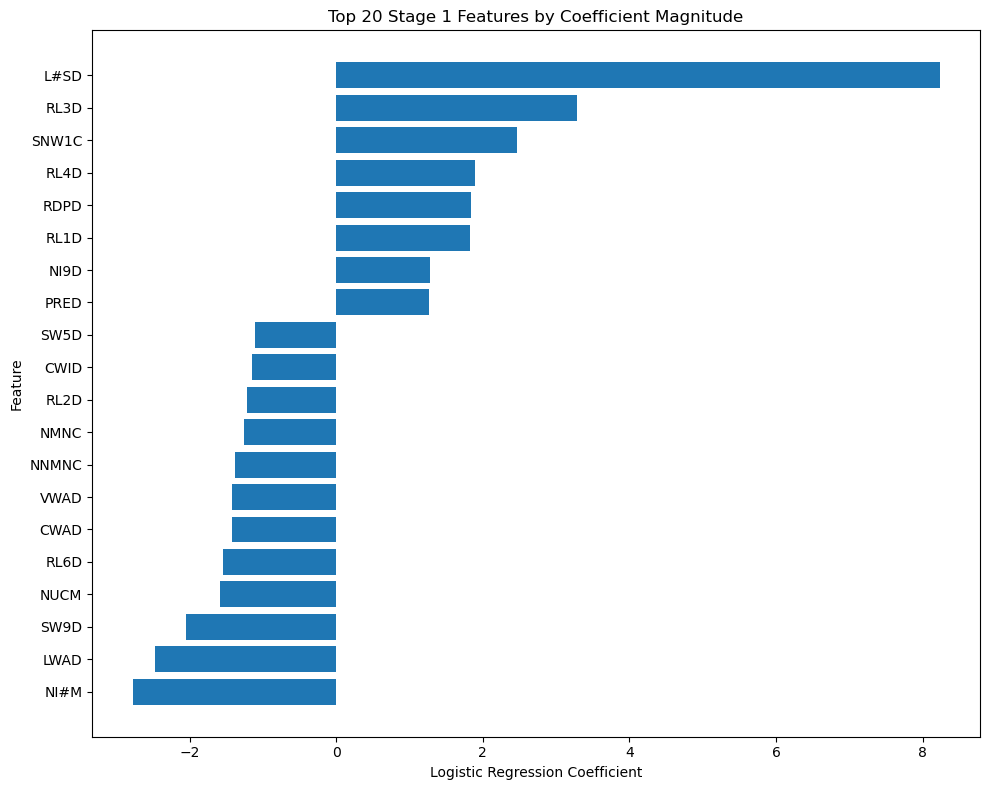

In [10]:
# ============================================================
# SECTION 10: CLEAN COEFFICIENT TABLE + VISUAL
# ============================================================


import matplotlib.pyplot as plt

# Show the largest coefficient magnitudes.
top_n = 20
top_coef_df = coef_df.head(top_n).copy()

print("TOP 20 FEATURES BY ABSOLUTE COEFFICIENT")
display(top_coef_df)

# Plot the top coefficient values.
plot_df = top_coef_df.sort_values("coefficient")

plt.figure(figsize=(10, 8))
plt.barh(plot_df["feature"], plot_df["coefficient"])
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top 20 Stage 1 Features by Coefficient Magnitude")
plt.tight_layout()
plt.show()


In [11]:
# ============================================================
# SECTION 11: REDUCED-FEATURE MODEL (REMOVE PROGRESSION PROXIES)
# ============================================================


from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

# List variables that may act like development or progression proxies.
proxy_keywords = [
    "GSTD", "DAP", "DAS", "DOY", "YEAR",   # already excluded earlier, kept here for safety
    "LAI", "L#",
    "LWAD", "SWAD", "GWAD", "CWAD", "VWAD", "PWAD", "RWAD",
    "HIAD", "HIPD",
    "RL1", "RL2", "RL3", "RL4", "RL5", "RL6", "RL7",
    "SW1", "SW2", "SW3", "SW4", "SW5", "SW6", "SW7", "SW8", "SW9",
    "NSTD", "KSTD", "EWSD", "WSPD", "WSGD",
    "CHTD", "CWID", "SLAD"
]

def is_proxy_feature(col):
    c = col.upper()
    return any(key.upper() in c for key in proxy_keywords)

reduced_feature_cols = [col for col in feature_cols if not is_proxy_feature(col)]

X_reduced = model_df[reduced_feature_cols].copy()

print("Original feature count :", len(feature_cols))
print("Reduced feature count  :", len(reduced_feature_cols))
print("\nFirst 30 reduced features:")
print(reduced_feature_cols[:30])

# Reuse the same grouped evaluation setup.
gkf = GroupKFold(n_splits=5)

reduced_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

oof_pred_reduced = np.zeros(len(X_reduced))
reduced_fold_results = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_reduced, y, groups), start=1):
    X_train, X_val = X_reduced.iloc[train_idx], X_reduced.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    reduced_pipe.fit(X_train, y_train)
    val_proba = reduced_pipe.predict_proba(X_val)[:, 1]
    oof_pred_reduced[val_idx] = val_proba

    reduced_fold_results.append({
        "fold": fold,
        "roc_auc": round(roc_auc_score(y_val, val_proba), 4),
        "pr_auc": round(average_precision_score(y_val, val_proba), 4)
    })

reduced_fold_results_df = pd.DataFrame(reduced_fold_results)

print("\nReduced-model fold results:")
print(reduced_fold_results_df)

print("\nReduced-model overall OOF performance:")
print(f"OOF ROC-AUC: {roc_auc_score(y, oof_pred_reduced):.4f}")
print(f"OOF PR-AUC : {average_precision_score(y, oof_pred_reduced):.4f}")


Original feature count : 132
Reduced feature count  : 95

First 30 reduced features:
['LIWAM', 'LINTP', 'G#AD', 'GWGD', 'P#AD', 'PST1A', 'PST2A', 'LN%D', 'SH%D', 'PWDD', 'PWTD', 'NWAD', 'RDPD', 'RL8D', 'RL9D', 'SNW0C', 'SNW1C', 'PRED', 'DAYLD', 'TWLD', 'SRAD', 'PARD', 'CLDD', 'TMXD', 'TMND', 'TAVD', 'TDYD', 'TDWD', 'TGAD', 'TGRD']

Reduced-model fold results:
   fold  roc_auc  pr_auc
0     1   0.8950  0.8340
1     2   0.9014  0.8140
2     3   0.9117  0.8483
3     4   0.9210  0.8634
4     5   0.9255  0.8513

Reduced-model overall OOF performance:
OOF ROC-AUC: 0.9102
OOF PR-AUC : 0.8385


In [12]:
# ============================================================
# SECTION 12: FULL VS REDUCED MODEL COMPARISON
# ============================================================


comparison_df = pd.DataFrame([
    {
        "model_version": "Full Stage 1 Logistic",
        "feature_count": len(feature_cols),
        "oof_roc_auc": round(roc_auc_score(y, oof_pred_proba), 4),
        "oof_pr_auc": round(average_precision_score(y, oof_pred_proba), 4)
    },
    {
        "model_version": "Reduced Stage 1 Logistic",
        "feature_count": len(reduced_feature_cols),
        "oof_roc_auc": round(roc_auc_score(y, oof_pred_reduced), 4),
        "oof_pr_auc": round(average_precision_score(y, oof_pred_reduced), 4)
    }
])

full_roc = comparison_df.loc[comparison_df["model_version"] == "Full Stage 1 Logistic", "oof_roc_auc"].iloc[0]
full_pr  = comparison_df.loc[comparison_df["model_version"] == "Full Stage 1 Logistic", "oof_pr_auc"].iloc[0]

comparison_df["roc_auc_drop_vs_full"] = (full_roc - comparison_df["oof_roc_auc"]).round(4)
comparison_df["pr_auc_drop_vs_full"] = (full_pr - comparison_df["oof_pr_auc"]).round(4)

comparison_display = comparison_df.copy()
comparison_display.columns = [
    "Model Version",
    "Feature Count",
    "OOF ROC-AUC",
    "OOF PR-AUC",
    "ROC-AUC Drop vs Full",
    "PR-AUC Drop vs Full"
]

print("MODEL COMPARISON: FULL VS REDUCED STAGE 1 LOGISTIC")
display(comparison_display)


MODEL COMPARISON: FULL VS REDUCED STAGE 1 LOGISTIC


,Model Version,Feature Count,OOF ROC-AUC,OOF PR-AUC,ROC-AUC Drop vs Full,PR-AUC Drop vs Full
0,Full Stage 1 Logistic,132,0.9865,0.9681,0.0000,0.0000
1,Reduced Stage 1 Logistic,95,0.9102,0.8385,0.0763,0.1296


## Stage 1 Early-Warning Modeling Results

The original all-row framing was too easy for the 7-day GSTD 5 task because most negative rows came from growth stages that could not realistically enter GSTD 5 within 7 days. A label audit confirmed that only **`GSTD = 1`** and **`GSTD = 3`** produced positive `y_enter5_7` labels in this dataset.

A second important finding was that **all GSTD 3 rows were positive** under the current label definition. That made GSTD 3 deterministic for the 7-day target, so it was not a useful standalone modeling subset.

For that reason, the final Task B modeling frame focuses on **GSTD 1 only**, where the early-warning problem is still nontrivial. This subset preserves the meaningful question: among observations currently in GSTD 1, which ones are likely to enter GSTD 5 within the next 7 days?

The first baseline was a GroupKFold logistic regression model using `RUNNO` as the grouping variable. This gave us a transparent baseline before moving to stronger nonlinear models. Coefficient inspection also showed that some of the strongest predictors were plant-state or development-related variables, which motivated the stricter feature audits that follow.

The reduced and strict feature tests are included to show how the project moved from a high-performing simulation-rich model toward a more defensible and client-feasible modeling frame.

## Testing a Stronger Nonlinear Model on the Reduced Stage 1 Feature Set

After creating a reduced feature set, the next modeling question was whether a stronger nonlinear model could recover useful predictive power without depending only on obvious progression variables.

LightGBM is used here because it can capture nonlinear thresholds and interactions that logistic regression may miss. This makes it a useful benchmark, but it also means the feature audit becomes more important. If hidden progression proxies remain in the data, LightGBM is more likely to exploit them.

This section is therefore both a performance test and a diagnostic step.

In [13]:
# ============================================================
# SECTION 13: LIGHTGBM ON REDUCED STAGE 1 FEATURE SET
# ============================================================


from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import GroupKFold

gkf = GroupKFold(n_splits=5)

lgbm_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

oof_pred_lgbm_reduced = np.zeros(len(X_reduced))
lgbm_fold_results = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_reduced, y, groups), start=1):
    X_train, X_val = X_reduced.iloc[train_idx], X_reduced.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    lgbm_model.fit(X_train, y_train)
    val_proba = lgbm_model.predict_proba(X_val)[:, 1]
    oof_pred_lgbm_reduced[val_idx] = val_proba

    lgbm_fold_results.append({
        "fold": fold,
        "roc_auc": round(roc_auc_score(y_val, val_proba), 4),
        "pr_auc": round(average_precision_score(y_val, val_proba), 4)
    })

lgbm_fold_results_df = pd.DataFrame(lgbm_fold_results)

print("LIGHTGBM REDUCED-FEATURE FOLD RESULTS")
display(lgbm_fold_results_df)

print("\nLIGHTGBM REDUCED-FEATURE OVERALL OOF PERFORMANCE")
lgbm_reduced_roc = roc_auc_score(y, oof_pred_lgbm_reduced)
lgbm_reduced_pr = average_precision_score(y, oof_pred_lgbm_reduced)
print(f"OOF ROC-AUC: {lgbm_reduced_roc:.4f}")
print(f"OOF PR-AUC : {lgbm_reduced_pr:.4f}")


LIGHTGBM REDUCED-FEATURE FOLD RESULTS


,fold,roc_auc,pr_auc
0,1,0.9995,0.9991
1,2,0.9998,0.9996
2,3,0.9997,0.9994
3,4,0.9998,0.9996
4,5,0.9996,0.9991



LIGHTGBM REDUCED-FEATURE OVERALL OOF PERFORMANCE
OOF ROC-AUC: 0.9997
OOF PR-AUC : 0.9994


## Interpreting the Initial Reduced-Feature LightGBM Result

The initial LightGBM model on the reduced GSTD 1 feature set achieved near-perfect performance. Numerically, that is impressive, but it is too strong to accept without a deeper feature audit.

The likely explanation is that the reduced feature set still contained variables that indirectly encoded plant development state or time-to-transition. LightGBM can use these signals more aggressively than a linear model because it captures nonlinear splits and interactions.

For that reason, this result should be treated as a diagnostic finding rather than the final honest Task B model. The next step is to inspect LightGBM feature importance and apply a stricter proxy audit.

In [14]:
# ============================================================
# SECTION 14: LIGHTGBM FEATURE IMPORTANCE AUDIT
# ============================================================


# Fit on the full reduced GSTD 1 dataset for feature-importance interpretation.
lgbm_model.fit(X_reduced, y)

lgbm_importance_df = pd.DataFrame({
    "feature": reduced_feature_cols,
    "importance_gain": lgbm_model.booster_.feature_importance(importance_type="gain"),
    "importance_split": lgbm_model.booster_.feature_importance(importance_type="split")
})

lgbm_importance_df = lgbm_importance_df.sort_values(
    "importance_gain", ascending=False
).reset_index(drop=True)

print("TOP 30 LIGHTGBM FEATURES BY GAIN")
display(lgbm_importance_df.head(30))


TOP 30 LIGHTGBM FEATURES BY GAIN


,feature,importance_gain,importance_split
0,SNW0C,22225.953306,534
1,RDPD,15283.029819,748
2,NUCM,6053.187714,380
3,TMND,3875.708632,675
4,LN%D,3852.319372,193
5,PREC,3484.830974,381
6,SWTD,1858.889917,198
7,SNW1C,1528.592985,191
8,TMXD,1419.300664,384
9,WDATE,1339.061567,402


In [15]:
# ============================================================
# SECTION 15: STRICT PROXY AUDIT + STRICTER REDUCED FEATURE SET
# ============================================================


from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from lightgbm import LGBMClassifier

# Use a stricter list of likely timing, development, or state proxies.
strict_proxy_keywords = [
    # time/date/calendar
    "DATE", "WDATE", "DAY", "DOY", "YEAR", "DAP", "DAS",

    # stage / plant development / morphology
    "GSTD", "LAI", "L#",
    "LWAD", "SWAD", "GWAD", "CWAD", "VWAD", "PWAD", "RWAD",
    "HIAD", "HIPD", "SLAD", "CHTD", "CWID",
    "RL1", "RL2", "RL3", "RL4", "RL5", "RL6", "RL7",
    "SW1", "SW2", "SW3", "SW4", "SW5", "SW6", "SW7", "SW8", "SW9",

    # stress / status / state-like variables that may track progression
    "WSPD", "WSGD", "EWSD", "KSTD", "NSTD",
    "PRED", "PARD", "DAYLD", "TWLD",

    # snow / residue / state pools that may act as season clocks
    "SNW0", "SNW1", "NUCM", "NIMC", "NMNC", "NMNMC", "NDNC"
]

def is_strict_proxy_feature(col):
    c = col.upper()
    return any(key.upper() in c for key in strict_proxy_keywords)

strict_feature_cols = [col for col in feature_cols if not is_strict_proxy_feature(col)]
X_strict = model_df[strict_feature_cols].copy()

print("Original feature count       :", len(feature_cols))
print("Previous reduced count      :", len(reduced_feature_cols))
print("Strict reduced feature count:", len(strict_feature_cols))

removed_now = sorted(set(reduced_feature_cols) - set(strict_feature_cols))
print("\nAdditional features removed in strict version (first 50):")
print(removed_now[:50])

print("\nFirst 30 strict reduced features:")
print(strict_feature_cols[:30])

gkf = GroupKFold(n_splits=5)

# Logistic regression on strict set
strict_log_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

oof_pred_log_strict = np.zeros(len(X_strict))
log_strict_fold_results = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_strict, y, groups), start=1):
    X_train, X_val = X_strict.iloc[train_idx], X_strict.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    strict_log_pipe.fit(X_train, y_train)
    val_proba = strict_log_pipe.predict_proba(X_val)[:, 1]
    oof_pred_log_strict[val_idx] = val_proba

    log_strict_fold_results.append({
        "fold": fold,
        "roc_auc": round(roc_auc_score(y_val, val_proba), 4),
        "pr_auc": round(average_precision_score(y_val, val_proba), 4)
    })

log_strict_fold_results_df = pd.DataFrame(log_strict_fold_results)

print("\nSTRICT LOGISTIC FOLD RESULTS")
display(log_strict_fold_results_df)

strict_log_roc = roc_auc_score(y, oof_pred_log_strict)
strict_log_pr = average_precision_score(y, oof_pred_log_strict)

print("\nSTRICT LOGISTIC OVERALL OOF PERFORMANCE")
print(f"OOF ROC-AUC: {strict_log_roc:.4f}")
print(f"OOF PR-AUC : {strict_log_pr:.4f}")

# LightGBM on strict set
strict_lgbm = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

oof_pred_lgbm_strict = np.zeros(len(X_strict))
lgbm_strict_fold_results = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_strict, y, groups), start=1):
    X_train, X_val = X_strict.iloc[train_idx], X_strict.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    strict_lgbm.fit(X_train, y_train)
    val_proba = strict_lgbm.predict_proba(X_val)[:, 1]
    oof_pred_lgbm_strict[val_idx] = val_proba

    lgbm_strict_fold_results.append({
        "fold": fold,
        "roc_auc": round(roc_auc_score(y_val, val_proba), 4),
        "pr_auc": round(average_precision_score(y_val, val_proba), 4)
    })

lgbm_strict_fold_results_df = pd.DataFrame(lgbm_strict_fold_results)

print("\nSTRICT LIGHTGBM FOLD RESULTS")
display(lgbm_strict_fold_results_df)

strict_lgbm_roc = roc_auc_score(y, oof_pred_lgbm_strict)
strict_lgbm_pr = average_precision_score(y, oof_pred_lgbm_strict)

print("\nSTRICT LIGHTGBM OVERALL OOF PERFORMANCE")
print(f"OOF ROC-AUC: {strict_lgbm_roc:.4f}")
print(f"OOF PR-AUC : {strict_lgbm_pr:.4f}")


Original feature count       : 132
Previous reduced count      : 95
Strict reduced feature count: 83

Additional features removed in strict version (first 50):
['DAYLD', 'NDNC', 'NIMC', 'NMNC', 'NNMNC', 'NUCM', 'PARD', 'PRED', 'SNW0C', 'SNW1C', 'TWLD', 'WDATE']

First 30 strict reduced features:
['LIWAM', 'LINTP', 'G#AD', 'GWGD', 'P#AD', 'PST1A', 'PST2A', 'LN%D', 'SH%D', 'PWDD', 'PWTD', 'NWAD', 'RDPD', 'RL8D', 'RL9D', 'SRAD', 'CLDD', 'TMXD', 'TMND', 'TAVD', 'TDYD', 'TDWD', 'TGAD', 'TGRD', 'WDSD', 'CO2D', 'VPDF', 'VPD', 'OZON7', 'NAPC']

STRICT LOGISTIC FOLD RESULTS


,fold,roc_auc,pr_auc
0,1,0.8312,0.7063
1,2,0.8397,0.7036
2,3,0.8577,0.7125
3,4,0.8502,0.7502
4,5,0.8632,0.7311



STRICT LOGISTIC OVERALL OOF PERFORMANCE
OOF ROC-AUC: 0.8477
OOF PR-AUC : 0.7151

STRICT LIGHTGBM FOLD RESULTS


,fold,roc_auc,pr_auc
0,1,0.9983,0.9961
1,2,0.9960,0.9952
2,3,0.9982,0.9966
3,4,0.9997,0.9994
4,5,0.9996,0.9993



STRICT LIGHTGBM OVERALL OOF PERFORMANCE
OOF ROC-AUC: 0.9984
OOF PR-AUC : 0.9973


In [16]:
# ============================================================
# SECTION 16: ALL MODEL VERSIONS COMPARISON TABLE
# ============================================================


all_model_comparison = pd.DataFrame([
    {
        "model_version": "Full Stage 1 Logistic",
        "feature_count": len(feature_cols),
        "oof_roc_auc": round(roc_auc_score(y, oof_pred_proba), 4),
        "oof_pr_auc": round(average_precision_score(y, oof_pred_proba), 4),
        "notes": "Best logistic performance; includes progression-like variables."
    },
    {
        "model_version": "Reduced Stage 1 Logistic",
        "feature_count": len(reduced_feature_cols),
        "oof_roc_auc": round(roc_auc_score(y, oof_pred_reduced), 4),
        "oof_pr_auc": round(average_precision_score(y, oof_pred_reduced), 4),
        "notes": "Initial reduced set; still contained hidden proxies."
    },
    {
        "model_version": "Strict Stage 1 Logistic",
        "feature_count": len(strict_feature_cols),
        "oof_roc_auc": round(roc_auc_score(y, oof_pred_log_strict), 4),
        "oof_pr_auc": round(average_precision_score(y, oof_pred_log_strict), 4),
        "notes": "Most conservative and currently most defensible baseline."
    },
    {
        "model_version": "Reduced Stage 1 LightGBM",
        "feature_count": len(reduced_feature_cols),
        "oof_roc_auc": round(roc_auc_score(y, oof_pred_lgbm_reduced), 4),
        "oof_pr_auc": round(average_precision_score(y, oof_pred_lgbm_reduced), 4),
        "notes": "Near-perfect result; likely still exploiting hidden proxies."
    },
    {
        "model_version": "Strict Stage 1 LightGBM",
        "feature_count": len(strict_feature_cols),
        "oof_roc_auc": round(roc_auc_score(y, oof_pred_lgbm_strict), 4),
        "oof_pr_auc": round(average_precision_score(y, oof_pred_lgbm_strict), 4),
        "notes": "Still suspiciously high; requires further leakage/proxy audit."
    }
])

best_roc = all_model_comparison["oof_roc_auc"].max()
best_pr = all_model_comparison["oof_pr_auc"].max()

all_model_comparison["roc_auc_gap_from_best"] = (best_roc - all_model_comparison["oof_roc_auc"]).round(4)
all_model_comparison["pr_auc_gap_from_best"] = (best_pr - all_model_comparison["oof_pr_auc"]).round(4)

comparison_display = all_model_comparison.copy()
comparison_display.columns = [
    "Model Version",
    "Feature Count",
    "OOF ROC-AUC",
    "OOF PR-AUC",
    "Notes",
    "ROC-AUC Gap from Best",
    "PR-AUC Gap from Best"
]

print("ALL STAGE 1 MODEL COMPARISONS")

display(
    comparison_display.style
    .set_properties(subset=["Notes"], **{
        "white-space": "pre-wrap",
        "text-align": "left"
    })
    .set_properties(**{
        "text-align": "center"
    })
)


ALL STAGE 1 MODEL COMPARISONS


,Model Version,Feature Count,OOF ROC-AUC,OOF PR-AUC,Notes,ROC-AUC Gap from Best,PR-AUC Gap from Best
0,Full Stage 1 Logistic,132,0.986500,0.968100,Best logistic performance; includes progression-like variables.,0.013200,0.031300
1,Reduced Stage 1 Logistic,95,0.910200,0.838500,Initial reduced set; still contained hidden proxies.,0.089500,0.160900
2,Strict Stage 1 Logistic,83,0.847700,0.715100,Most conservative and currently most defensible baseline.,0.152000,0.284300
3,Reduced Stage 1 LightGBM,95,0.999700,0.999400,Near-perfect result; likely still exploiting hidden proxies.,0.000000,0.000000
4,Strict Stage 1 LightGBM,83,0.998400,0.997300,Still suspiciously high; requires further leakage/proxy audit.,0.001300,0.002100


## Strict LightGBM Feature Importance Audit

The stricter feature cleanup reduced logistic regression performance, which shows that the proxy-removal step had a real effect. However, the strict LightGBM model still performed extremely well.

This section audits the strict LightGBM feature importance to understand what the model is still using. The goal is to separate two possibilities:

1. the remaining feature space is genuinely informative, or  
2. the DSSAT-derived structure still contains variables that act like hidden timing or development proxies.

This audit helps justify why the final client-facing model should use a practical feature set rather than simply choosing the highest-scoring strict benchmark.

TOP 30 STRICT LIGHTGBM FEATURES BY GAIN


,feature,importance_gain,importance_split
0,RDPD,26412.226608,840
1,LN%D,7453.997456,375
2,PREC,6906.138706,560
3,MWTD,3271.226435,91
4,TMND,3244.781289,635
5,NITC,2459.814628,366
6,NIAD,2390.771095,324
7,TMXD,2063.201984,442
8,SRAD,1858.997557,451
9,NITD,1753.789894,199


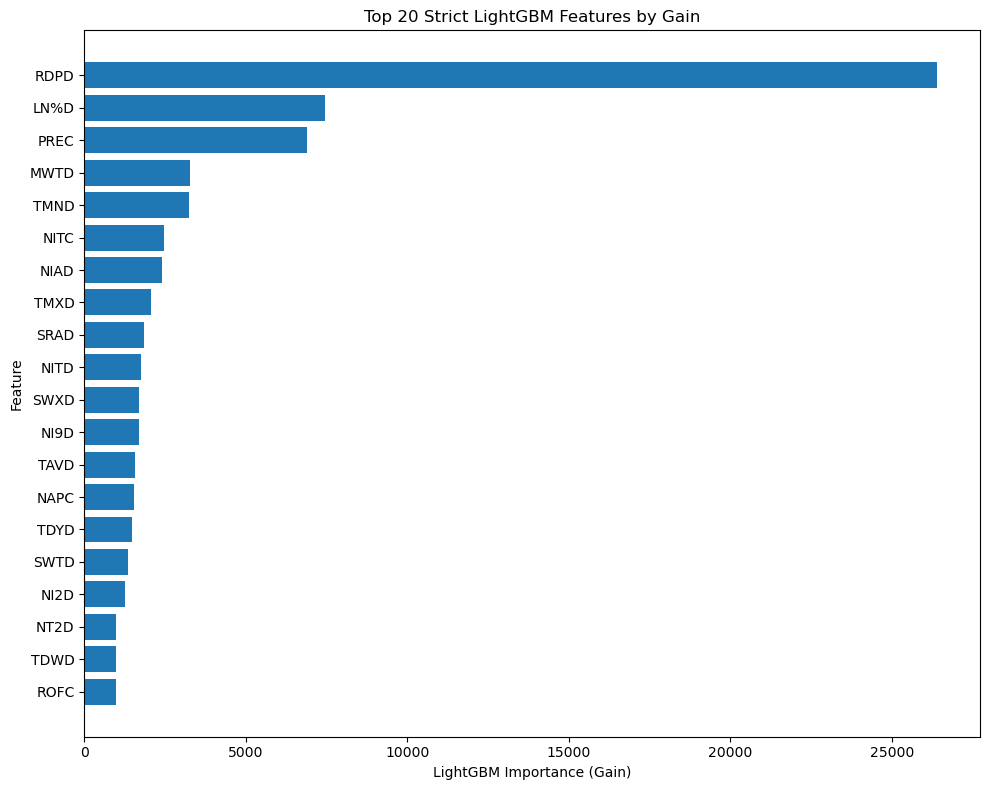

In [17]:
# ============================================================
# SECTION 17: STRICT LIGHTGBM FEATURE IMPORTANCE AUDIT
# ============================================================


import matplotlib.pyplot as plt

# Fit strict LightGBM on the full strict dataset for interpretation.
strict_lgbm.fit(X_strict, y)

strict_lgbm_importance_df = pd.DataFrame({
    "feature": strict_feature_cols,
    "importance_gain": strict_lgbm.booster_.feature_importance(importance_type="gain"),
    "importance_split": strict_lgbm.booster_.feature_importance(importance_type="split")
})

strict_lgbm_importance_df = (
    strict_lgbm_importance_df
    .sort_values("importance_gain", ascending=False)
    .reset_index(drop=True)
)

top_n = 30
top_strict_lgbm_importance = strict_lgbm_importance_df.head(top_n).copy()

print("TOP 30 STRICT LIGHTGBM FEATURES BY GAIN")
display(top_strict_lgbm_importance)

# plot top 20 by gain
plot_df = strict_lgbm_importance_df.head(20).sort_values("importance_gain")

plt.figure(figsize=(10, 8))
plt.barh(plot_df["feature"], plot_df["importance_gain"])
plt.xlabel("LightGBM Importance (Gain)")
plt.ylabel("Feature")
plt.title("Top 20 Strict LightGBM Features by Gain")
plt.tight_layout()
plt.show()


## Modeling Rationale and Feature-Set Audit Summary

At this stage, the Task B problem has been reframed into a more honest and business-relevant early-warning task.

### Target structure

The label audit showed that only observations currently in **GSTD 1** or **GSTD 3** produced positive `y_enter5_7` labels. Observations in **GSTD 0, 5, 7, and 8** were always negative for this target. In addition, every GSTD 3 row transitioned to GSTD 5 within 7 days in this dataset.

Because GSTD 3 was deterministic, the final predictive modeling task focuses on **GSTD 1 only**. This avoids inflated performance from easy negatives and focuses on the part of the crop-development process where the 7-day alert is still uncertain.

### Feature audit

The model-development process tested several levels of feature restriction:

- full GSTD 1 feature set
- reduced feature set with obvious progression proxies removed
- stricter feature set with additional timing and development-like variables removed
- client-feasible feature set based on variables the client identified as realistic
- client-feasible time-series feature set using lagged and rolling versions of those same practical inputs

The strict model provides a useful benchmark, but the final recommendation should prioritize operational realism. For that reason, the client-feasible and client-feasible time-series models are the most important final candidates.

In [18]:
# ============================================================
# SECTION 18: ALL STRICT LIGHTGBM FEATURES BY GAIN (FULL VIEW)
# ============================================================


pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)

all_strict_lgbm_features = (
    strict_lgbm_importance_df[["feature", "importance_gain", "importance_split"]]
    .reset_index(drop=True)
    .copy()
)

all_strict_lgbm_features["importance_gain"] = all_strict_lgbm_features["importance_gain"].round(6)

print("ALL STRICT LIGHTGBM FEATURES BY GAIN")
display(all_strict_lgbm_features)


ALL STRICT LIGHTGBM FEATURES BY GAIN


,feature,importance_gain,importance_split
0,RDPD,26412.226608,840
1,LN%D,7453.997456,375
2,PREC,6906.138706,560
3,MWTD,3271.226435,91
4,TMND,3244.781289,635
5,NITC,2459.814628,366
6,NIAD,2390.771095,324
7,TMXD,2063.201984,442
8,SRAD,1858.997557,451
9,NITD,1753.789894,199


In [19]:
# ============================================================
# SECTION 19: SPLIT STRICT LIGHTGBM FEATURES INTO NONZERO-IMPORTANCE AND ZERO-IMPORTANCE SETS
# ============================================================


# Start from the full feature-importance table.
strict_importance_full = strict_lgbm_importance_df.copy()

# Separate features the model used from features with zero gain.
strict_nonzero_features_df = (
    strict_importance_full[strict_importance_full["importance_gain"] > 0]
    .reset_index(drop=True)
    .copy()
)

strict_zero_features_df = (
    strict_importance_full[strict_importance_full["importance_gain"] == 0]
    .reset_index(drop=True)
    .copy()
)

# Round values to make the table easier to read.
strict_nonzero_features_df["importance_gain"] = strict_nonzero_features_df["importance_gain"].round(6)
strict_zero_features_df["importance_gain"] = strict_zero_features_df["importance_gain"].round(6)

# Start displayed row numbers at 1 for readability.
strict_nonzero_features_df.index = range(1, len(strict_nonzero_features_df) + 1)
strict_zero_features_df.index = range(1, len(strict_zero_features_df) + 1)

# Keep the active strict feature list for comparison and discussion.
strict_active_feature_cols = strict_nonzero_features_df["feature"].tolist()

print("NONZERO-IMPORTANCE STRICT LIGHTGBM FEATURES")
print(f"Count: {len(strict_nonzero_features_df)}")
display(strict_nonzero_features_df)

print("\nZERO-IMPORTANCE STRICT LIGHTGBM FEATURES")
print(f"Count: {len(strict_zero_features_df)}")
display(strict_zero_features_df)

print("\nACTIVE FEATURE LIST SIZE FOR CLEANED STRICT MODEL:")
print(len(strict_active_feature_cols))

print("\nFirst 30 active features:")
print(strict_active_feature_cols[:30])


NONZERO-IMPORTANCE STRICT LIGHTGBM FEATURES
Count: 57


,feature,importance_gain,importance_split
1,RDPD,26412.226608,840
2,LN%D,7453.997456,375
3,PREC,6906.138706,560
4,MWTD,3271.226435,91
5,TMND,3244.781289,635
6,NITC,2459.814628,366
7,NIAD,2390.771095,324
8,TMXD,2063.201984,442
9,SRAD,1858.997557,451
10,NITD,1753.789894,199



ZERO-IMPORTANCE STRICT LIGHTGBM FEATURES
Count: 26


,feature,importance_gain,importance_split
1,TDFD,0.0,0
2,IRRC,0.0,0
3,TDFC,0.0,0
4,IR#C,0.0,0
5,LATFC,0.0,0
6,LIWAM,0.0,0
7,NH7D,0.0,0
8,LINTP,0.0,0
9,G#AD,0.0,0
10,GWGD,0.0,0



ACTIVE FEATURE LIST SIZE FOR CLEANED STRICT MODEL:
57

First 30 active features:
['RDPD', 'LN%D', 'PREC', 'MWTD', 'TMND', 'NITC', 'NIAD', 'TMXD', 'SRAD', 'NITD', 'SWXD', 'NI9D', 'TAVD', 'NAPC', 'TDYD', 'SWTD', 'NI2D', 'NT2D', 'TDWD', 'ROFC', 'NI10', 'NT1D', 'NI1D', 'CLDD', 'NT7D', 'NT10', 'NI7D', 'NT3D', 'NH2D', 'NH3D']


In [20]:
# ============================================================
# SECTION 20: DEFINE VERIFIED CLIENT-FEASIBLE FEATURE SET
# ============================================================


# Use the six client-feasible features identified during the project.
client_core_features_requested = [
    "TMND",   # minimum temperature
    "PREC",   # precipitation
    "SRAD",   # solar radiation
    "TMXD",   # maximum temperature
    "TAVD",   # average temperature
    "NURTD"   # urea-N applied
]

client_core_feature_names = {
    "TMND": "Minimum temperature",
    "PREC": "Precipitation",
    "SRAD": "Solar radiation",
    "TMXD": "Maximum temperature",
    "TAVD": "Average temperature",
    "NURTD": "Urea-N applied"
}

# Check that every client-feasible feature exists in the modeling table.
available_client_core = [f for f in client_core_features_requested if f in model_df.columns]
missing_client_core = [f for f in client_core_features_requested if f not in model_df.columns]

print("CLIENT CORE FEATURES REQUESTED:")
print(client_core_features_requested)

print("\nAVAILABLE IN model_df:")
print(available_client_core)

print("\nMISSING FROM model_df:")
print(missing_client_core)

if len(missing_client_core) > 0:
    raise ValueError(f"These client-core features are missing from model_df: {missing_client_core}")

# Create a simple feature availability summary.
client_core_summary_df = pd.DataFrame({
    "feature": available_client_core,
    "full_name": [client_core_feature_names.get(f, f) for f in available_client_core],
    "in_strict_active_features": [f in strict_active_feature_cols for f in available_client_core]
})

print("\nVERIFIED CLIENT-FEASIBLE FEATURE SET")
display(client_core_summary_df)

# Build the raw client-feasible feature matrix.
X_client_core = model_df[available_client_core].copy()

print("\nX_client_core shape:", X_client_core.shape)
display(X_client_core.head())

# Quick shape check before modeling.
print("\nTARGET / GROUP AUDIT")
print("y shape:", y.shape)
print("groups shape:", groups.shape)
print("Unique RUNNO in groups:", pd.Series(groups).nunique())


CLIENT CORE FEATURES REQUESTED:
['TMND', 'PREC', 'SRAD', 'TMXD', 'TAVD', 'NURTD']

AVAILABLE IN model_df:
['TMND', 'PREC', 'SRAD', 'TMXD', 'TAVD', 'NURTD']

MISSING FROM model_df:
[]

VERIFIED CLIENT-FEASIBLE FEATURE SET


,feature,full_name,in_strict_active_features
0,TMND,Minimum temperature,True
1,PREC,Precipitation,True
2,SRAD,Solar radiation,True
3,TMXD,Maximum temperature,True
4,TAVD,Average temperature,True
5,NURTD,Urea-N applied,True



X_client_core shape: (6164, 6)


,TMND,PREC,SRAD,TMXD,TAVD,NURTD
46,17.3,497,27.8,35.8,26.7,0.0
47,22.7,501,26.2,37.0,30.0,0.0
48,24.8,504,23.6,36.5,30.7,0.0
49,25.2,505,24.5,36.5,30.9,0.0
50,26.2,511,22.8,36.2,31.3,0.0



TARGET / GROUP AUDIT
y shape: (6164,)
groups shape: (6164,)
Unique RUNNO in groups: 980


In [21]:
# ============================================================
# SECTION 21: CLIENT-FEASIBLE LIGHTGBM WITH GROUPKFOLD BY RUNNO
# ============================================================


from lightgbm import LGBMClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score

# Use the same grouped evaluation style as the earlier models.
gkf = GroupKFold(n_splits=5)

client_core_lgbm = LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

oof_pred_client_core = np.zeros(len(X_client_core))
client_core_fold_results = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_client_core, y, groups=groups), start=1):
    X_train = X_client_core.iloc[train_idx].copy()
    X_val   = X_client_core.iloc[val_idx].copy()
    y_train = y.iloc[train_idx].copy()
    y_val   = y.iloc[val_idx].copy()

    train_runs = pd.Series(groups).iloc[train_idx].nunique()
    val_runs   = pd.Series(groups).iloc[val_idx].nunique()

    client_core_lgbm.fit(X_train, y_train)
    val_pred = client_core_lgbm.predict_proba(X_val)[:, 1]
    oof_pred_client_core[val_idx] = val_pred

    client_core_fold_results.append({
        "fold": fold,
        "train_rows": len(train_idx),
        "val_rows": len(val_idx),
        "train_runs": int(train_runs),
        "val_runs": int(val_runs),
        "val_positive_rate": round(float(y_val.mean()), 4),
        "roc_auc": round(float(roc_auc_score(y_val, val_pred)), 4),
        "pr_auc": round(float(average_precision_score(y_val, val_pred)), 4)
    })

client_core_fold_results_df = pd.DataFrame(client_core_fold_results)

print("CLIENT-FEASIBLE LIGHTGBM GROUPKFOLD RESULTS")
display(client_core_fold_results_df)

client_core_oof_roc_auc = roc_auc_score(y, oof_pred_client_core)
client_core_oof_pr_auc  = average_precision_score(y, oof_pred_client_core)

print("\nCLIENT-FEASIBLE LIGHTGBM OVERALL OOF PERFORMANCE")
print(f"OOF ROC-AUC: {client_core_oof_roc_auc:.4f}")
print(f"OOF PR-AUC : {client_core_oof_pr_auc:.4f}")


CLIENT-FEASIBLE LIGHTGBM GROUPKFOLD RESULTS


,fold,train_rows,val_rows,train_runs,val_runs,val_positive_rate,roc_auc,pr_auc
0,1,4931,1233,784,196,0.3260,0.9999,0.9999
1,2,4931,1233,784,196,0.3268,0.9995,0.9990
2,3,4931,1233,784,196,0.3293,0.9998,0.9997
3,4,4931,1233,784,196,0.3228,0.9999,0.9998
4,5,4932,1232,784,196,0.3279,0.9999,0.9998



CLIENT-FEASIBLE LIGHTGBM OVERALL OOF PERFORMANCE
OOF ROC-AUC: 0.9998
OOF PR-AUC : 0.9996


In [22]:
# ============================================================
# SECTION 22: STRICT VS CLIENT-FEASIBLE MODEL COMPARISON
# ============================================================


strict_vs_client_comparison_df = pd.DataFrame([
    {
        "model_version": "Strict Stage 1 LightGBM",
        "feature_count": int(len(strict_active_feature_cols)),
        "oof_roc_auc": round(float(strict_lgbm_roc), 4),
        "oof_pr_auc": round(float(strict_lgbm_pr), 4),
        "notes": "57-feature strict model using all nonzero-importance strict LightGBM features."
    },
    {
        "model_version": "Client-Feasible Stage 1 LightGBM",
        "feature_count": int(len(available_client_core)),
        "oof_roc_auc": round(float(client_core_oof_roc_auc), 4),
        "oof_pr_auc": round(float(client_core_oof_pr_auc), 4),
        "notes": "6-feature client-feasible model using practical weather + N application inputs."
    }
])

strict_roc = float(strict_lgbm_roc)
strict_pr  = float(strict_lgbm_pr)

strict_vs_client_comparison_df["roc_auc_drop_vs_strict"] = (
    strict_roc - strict_vs_client_comparison_df["oof_roc_auc"]
).round(4)

strict_vs_client_comparison_df["pr_auc_drop_vs_strict"] = (
    strict_pr - strict_vs_client_comparison_df["oof_pr_auc"]
).round(4)

strict_vs_client_comparison_df["features_removed_from_strict"] = (
    len(strict_active_feature_cols) - strict_vs_client_comparison_df["feature_count"]
)

print("STRICT VS CLIENT-FEASIBLE MODEL COMPARISON")
display(strict_vs_client_comparison_df)

print("\nCLIENT-FEASIBLE FEATURE LIST:")
print(available_client_core)


STRICT VS CLIENT-FEASIBLE MODEL COMPARISON


,model_version,feature_count,oof_roc_auc,oof_pr_auc,notes,roc_auc_drop_vs_strict,pr_auc_drop_vs_strict,features_removed_from_strict
0,Strict Stage 1 LightGBM,57,0.9984,0.9973,57-feature strict model using all nonzero-importance strict LightGBM features.,-0.0000,0.0000,0
1,Client-Feasible Stage 1 LightGBM,6,0.9998,0.9996,6-feature client-feasible model using practical weather + N application inputs.,-0.0014,-0.0023,51



CLIENT-FEASIBLE FEATURE LIST:
['TMND', 'PREC', 'SRAD', 'TMXD', 'TAVD', 'NURTD']


In [23]:
# ============================================================
# SECTION 23: TIME-BASED HOLDOUT ROBUSTNESS TEST CLIENT-FEASIBLE STAGE 1 LIGHTGBM Train on 2023-2044, test on 2045-2050
# ============================================================


from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# Note: reset index first so target/features align row-for-row
time_client_df = model_df[["RUNNO", "TRTNO", "DATE"]].reset_index(drop=True).copy()
time_client_df["DATE"] = pd.to_datetime(time_client_df["DATE"], errors="coerce")
time_client_df["YEAR_ONLY"] = time_client_df["DATE"].dt.year

# attach target and client-feasible features with guaranteed positional alignment
time_client_df["y_enter5_7"] = y.reset_index(drop=True).astype(int)
time_client_df = pd.concat(
    [time_client_df, X_client_core.reset_index(drop=True)],
    axis=1
)

# keep only rows needed for this evaluation
needed_cols = ["RUNNO", "TRTNO", "DATE", "YEAR_ONLY", "y_enter5_7"] + available_client_core
time_client_df = time_client_df[needed_cols].dropna(subset=["YEAR_ONLY", "y_enter5_7"]).copy()
time_client_df["YEAR_ONLY"] = time_client_df["YEAR_ONLY"].astype(int)
time_client_df["y_enter5_7"] = time_client_df["y_enter5_7"].astype(int)

# same forward time split used earlier
train_mask_client = time_client_df["YEAR_ONLY"] <= 2044
test_mask_client  = time_client_df["YEAR_ONLY"] >= 2045

train_client_df = time_client_df.loc[train_mask_client].copy()
test_client_df  = time_client_df.loc[test_mask_client].copy()

X_train_time_client = train_client_df[available_client_core].copy()
y_train_time_client = train_client_df["y_enter5_7"].copy()

X_test_time_client = test_client_df[available_client_core].copy()
y_test_time_client = test_client_df["y_enter5_7"].copy()

print("Train years:", clean_year_list(train_client_df["YEAR_ONLY"]))
print("Test years:", clean_year_list(test_client_df["YEAR_ONLY"]))

print("\nTrain shape:", X_train_time_client.shape)
print("Test shape:", X_test_time_client.shape)

print("\nTrain runs:", train_client_df["RUNNO"].nunique())
print("Test runs:", test_client_df["RUNNO"].nunique())

print("\nTrain treatments:", train_client_df["TRTNO"].nunique())
print("Test treatments:", test_client_df["TRTNO"].nunique())

print("\nTrain positives:", int(y_train_time_client.sum()), "rate =", round(float(y_train_time_client.mean()), 4))
print("Test positives:", int(y_test_time_client.sum()), "rate =", round(float(y_test_time_client.mean()), 4))

time_client_model = LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

time_client_model.fit(X_train_time_client, y_train_time_client)
y_pred_time_client = time_client_model.predict_proba(X_test_time_client)[:, 1]

time_client_roc = roc_auc_score(y_test_time_client, y_pred_time_client)
time_client_pr  = average_precision_score(y_test_time_client, y_pred_time_client)

print("\nCLIENT-FEASIBLE TIME HOLDOUT ROC-AUC:", round(float(time_client_roc), 4))
print("CLIENT-FEASIBLE TIME HOLDOUT PR-AUC:", round(float(time_client_pr), 4))

time_client_summary_df = pd.DataFrame([{
    "model_version": "Client-Feasible Stage 1 LightGBM",
    "evaluation": "Time holdout (2023-2044 train, 2045-2050 test)",
    "feature_count": len(available_client_core),
    "train_rows": len(train_client_df),
    "test_rows": len(test_client_df),
    "train_runs": train_client_df["RUNNO"].nunique(),
    "test_runs": test_client_df["RUNNO"].nunique(),
    "train_treatments": train_client_df["TRTNO"].nunique(),
    "test_treatments": test_client_df["TRTNO"].nunique(),
    "train_positive_rate": round(float(y_train_time_client.mean()), 4),
    "test_positive_rate": round(float(y_test_time_client.mean()), 4),
    "roc_auc": round(float(time_client_roc), 4),
    "pr_auc": round(float(time_client_pr), 4)
}])

print("\nCLIENT-FEASIBLE TIME-HOLDOUT ROBUSTNESS SUMMARY")
display(time_client_summary_df)


Train years: [2023, 2024, 2025, 2026, 2027, 2028, 2029, 2030, 2031, 2032, 2033, 2034, 2035, 2036, 2037, 2038, 2039, 2040, 2041, 2042, 2043, 2044]
Test years: [2045, 2046, 2047, 2048, 2049, 2050]

Train shape: (4853, 6)
Test shape: (1311, 6)

Train runs: 770
Test runs: 210

Train treatments: 35
Test treatments: 35

Train positives: 1609 rate = 0.3315
Test positives: 404 rate = 0.3082

CLIENT-FEASIBLE TIME HOLDOUT ROC-AUC: 0.5386
CLIENT-FEASIBLE TIME HOLDOUT PR-AUC: 0.3468

CLIENT-FEASIBLE TIME-HOLDOUT ROBUSTNESS SUMMARY


,model_version,evaluation,feature_count,train_rows,test_rows,train_runs,test_runs,train_treatments,test_treatments,train_positive_rate,test_positive_rate,roc_auc,pr_auc
0,Client-Feasible Stage 1 LightGBM,"Time holdout (2023-2044 train, 2045-2050 test)",6,4853,1311,770,210,35,35,0.3315,0.3082,0.5386,0.3468


In [24]:
# ============================================================
# SECTION 24: STRICT STAGE 1 LIGHTGBM TIME-BASED HOLDOUT ROBUSTNESS TEST Train on 2023-2044, test on 2045-2050
# ============================================================


from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# rebuild strict evaluation table with aligned target
time_strict_df = model_df[["RUNNO", "TRTNO", "DATE"] + strict_active_feature_cols].reset_index(drop=True).copy()
time_strict_df["DATE"] = pd.to_datetime(time_strict_df["DATE"], errors="coerce")
time_strict_df["YEAR_ONLY"] = time_strict_df["DATE"].dt.year
time_strict_df["y_enter5_7"] = y.reset_index(drop=True).astype(int)

needed_cols_strict = ["RUNNO", "TRTNO", "DATE", "YEAR_ONLY", "y_enter5_7"] + strict_active_feature_cols
time_strict_df = time_strict_df[needed_cols_strict].dropna(subset=["YEAR_ONLY", "y_enter5_7"]).copy()
time_strict_df["YEAR_ONLY"] = time_strict_df["YEAR_ONLY"].astype(int)
time_strict_df["y_enter5_7"] = time_strict_df["y_enter5_7"].astype(int)

train_mask_strict = time_strict_df["YEAR_ONLY"] <= 2044
test_mask_strict  = time_strict_df["YEAR_ONLY"] >= 2045

train_strict_df = time_strict_df.loc[train_mask_strict].copy()
test_strict_df  = time_strict_df.loc[test_mask_strict].copy()

X_train_time_strict = train_strict_df[strict_active_feature_cols].copy()
y_train_time_strict = train_strict_df["y_enter5_7"].copy()

X_test_time_strict = test_strict_df[strict_active_feature_cols].copy()
y_test_time_strict = test_strict_df["y_enter5_7"].copy()

print("Train years:", clean_year_list(train_strict_df["YEAR_ONLY"]))
print("Test years:", clean_year_list(test_strict_df["YEAR_ONLY"]))

print("\nTrain shape:", X_train_time_strict.shape)
print("Test shape:", X_test_time_strict.shape)

print("\nTrain runs:", train_strict_df["RUNNO"].nunique())
print("Test runs:", test_strict_df["RUNNO"].nunique())

print("\nTrain treatments:", train_strict_df["TRTNO"].nunique())
print("Test treatments:", test_strict_df["TRTNO"].nunique())

print("\nTrain positives:", int(y_train_time_strict.sum()), "rate =", round(float(y_train_time_strict.mean()), 4))
print("Test positives:", int(y_test_time_strict.sum()), "rate =", round(float(y_test_time_strict.mean()), 4))

strict_time_model = LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

strict_time_model.fit(X_train_time_strict, y_train_time_strict)
y_pred_time_strict = strict_time_model.predict_proba(X_test_time_strict)[:, 1]

strict_time_roc = roc_auc_score(y_test_time_strict, y_pred_time_strict)
strict_time_pr  = average_precision_score(y_test_time_strict, y_pred_time_strict)

print("\nSTRICT STAGE 1 TIME HOLDOUT ROC-AUC:", round(float(strict_time_roc), 4))
print("STRICT STAGE 1 TIME HOLDOUT PR-AUC:", round(float(strict_time_pr), 4))

strict_time_summary_df = pd.DataFrame([{
    "model_version": "Strict Stage 1 LightGBM",
    "evaluation": "Time holdout (2023-2044 train, 2045-2050 test)",
    "feature_count": len(strict_active_feature_cols),
    "train_rows": len(train_strict_df),
    "test_rows": len(test_strict_df),
    "train_runs": train_strict_df["RUNNO"].nunique(),
    "test_runs": test_strict_df["RUNNO"].nunique(),
    "train_treatments": train_strict_df["TRTNO"].nunique(),
    "test_treatments": test_strict_df["TRTNO"].nunique(),
    "train_positive_rate": round(float(y_train_time_strict.mean()), 4),
    "test_positive_rate": round(float(y_test_time_strict.mean()), 4),
    "roc_auc": round(float(strict_time_roc), 4),
    "pr_auc": round(float(strict_time_pr), 4)
}])

print("\nSTRICT STAGE 1 TIME-HOLDOUT ROBUSTNESS SUMMARY")
display(strict_time_summary_df)


Train years: [2023, 2024, 2025, 2026, 2027, 2028, 2029, 2030, 2031, 2032, 2033, 2034, 2035, 2036, 2037, 2038, 2039, 2040, 2041, 2042, 2043, 2044]
Test years: [2045, 2046, 2047, 2048, 2049, 2050]

Train shape: (4853, 57)
Test shape: (1311, 57)

Train runs: 770
Test runs: 210

Train treatments: 35
Test treatments: 35

Train positives: 1609 rate = 0.3315
Test positives: 404 rate = 0.3082

STRICT STAGE 1 TIME HOLDOUT ROC-AUC: 0.9141
STRICT STAGE 1 TIME HOLDOUT PR-AUC: 0.8484

STRICT STAGE 1 TIME-HOLDOUT ROBUSTNESS SUMMARY


,model_version,evaluation,feature_count,train_rows,test_rows,train_runs,test_runs,train_treatments,test_treatments,train_positive_rate,test_positive_rate,roc_auc,pr_auc
0,Strict Stage 1 LightGBM,"Time holdout (2023-2044 train, 2045-2050 test)",57,4853,1311,770,210,35,35,0.3315,0.3082,0.9141,0.8484


In [25]:
# ============================================================
# SECTION 25: STRICT STAGE 1 LIGHTGBM LEAVE-ONE-TREATMENT-OUT (LOTO) ROBUSTNESS TEST
# ============================================================


from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# rebuild strict treatment evaluation table with aligned target
treatment_strict_df = model_df[["RUNNO", "TRTNO", "DATE"] + strict_active_feature_cols].reset_index(drop=True).copy()
treatment_strict_df["DATE"] = pd.to_datetime(treatment_strict_df["DATE"], errors="coerce")
treatment_strict_df["y_enter5_7"] = y.reset_index(drop=True).astype(int)

needed_cols_strict_loto = ["RUNNO", "TRTNO", "DATE", "y_enter5_7"] + strict_active_feature_cols
treatment_strict_df = treatment_strict_df[needed_cols_strict_loto].dropna(subset=["TRTNO", "y_enter5_7"]).copy()
treatment_strict_df["TRTNO"] = treatment_strict_df["TRTNO"].astype(int)
treatment_strict_df["y_enter5_7"] = treatment_strict_df["y_enter5_7"].astype(int)

print("STRICT TREATMENT ROBUSTNESS DATA SHAPE:", treatment_strict_df.shape)
print("UNIQUE TRTNO VALUES:", sorted(treatment_strict_df["TRTNO"].unique()))
print("UNIQUE RUNS:", treatment_strict_df["RUNNO"].nunique())
print("OVERALL POSITIVE RATE:", round(float(treatment_strict_df["y_enter5_7"].mean()), 4))

strict_loto_results = []
strict_loto_oof_pred = np.full(len(treatment_strict_df), np.nan)

unique_treatments_strict = sorted(treatment_strict_df["TRTNO"].unique())

for held_out_trt in unique_treatments_strict:
    train_fold_df = treatment_strict_df[treatment_strict_df["TRTNO"] != held_out_trt].copy()
    test_fold_df  = treatment_strict_df[treatment_strict_df["TRTNO"] == held_out_trt].copy()

    X_train_loto_strict = train_fold_df[strict_active_feature_cols].copy()
    y_train_loto_strict = train_fold_df["y_enter5_7"].copy()

    X_test_loto_strict = test_fold_df[strict_active_feature_cols].copy()
    y_test_loto_strict = test_fold_df["y_enter5_7"].copy()

    row = {
        "held_out_trtno": int(held_out_trt),
        "train_rows": len(train_fold_df),
        "test_rows": len(test_fold_df),
        "train_runs": train_fold_df["RUNNO"].nunique(),
        "test_runs": test_fold_df["RUNNO"].nunique(),
        "train_positive_rate": round(float(y_train_loto_strict.mean()), 4),
        "test_positive_rate": round(float(y_test_loto_strict.mean()), 4),
        "train_unique_classes": int(y_train_loto_strict.nunique()),
        "test_unique_classes": int(y_test_loto_strict.nunique())
    }

    if y_train_loto_strict.nunique() < 2 or y_test_loto_strict.nunique() < 2:
        row["roc_auc"] = np.nan
        row["pr_auc"] = np.nan
        row["status"] = "Skipped: class imbalance in train/test fold"
        strict_loto_results.append(row)
        continue

    strict_loto_model = LGBMClassifier(
        objective="binary",
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=20,
        subsample=0.8,
        colsample_bytree=0.8,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    strict_loto_model.fit(X_train_loto_strict, y_train_loto_strict)
    y_pred_loto_strict = strict_loto_model.predict_proba(X_test_loto_strict)[:, 1]

    strict_loto_oof_pred[test_fold_df.index] = y_pred_loto_strict

    row["roc_auc"] = round(float(roc_auc_score(y_test_loto_strict, y_pred_loto_strict)), 4)
    row["pr_auc"] = round(float(average_precision_score(y_test_loto_strict, y_pred_loto_strict)), 4)
    row["status"] = "OK"
    strict_loto_results.append(row)

strict_loto_results_df = pd.DataFrame(strict_loto_results).sort_values("held_out_trtno").reset_index(drop=True)

print("\nSTRICT STAGE 1 LOTO RESULTS")
display(strict_loto_results_df)

valid_strict_loto_df = strict_loto_results_df[strict_loto_results_df["status"] == "OK"].copy()

if len(valid_strict_loto_df) > 0:
    strict_loto_summary_df = pd.DataFrame([{
        "model_version": "Strict Stage 1 LightGBM",
        "evaluation": "Leave-one-treatment-out by TRTNO",
        "feature_count": len(strict_active_feature_cols),
        "num_treatments_total": len(unique_treatments_strict),
        "num_valid_treatments": len(valid_strict_loto_df),
        "mean_roc_auc": round(float(valid_strict_loto_df["roc_auc"].mean()), 4),
        "median_roc_auc": round(float(valid_strict_loto_df["roc_auc"].median()), 4),
        "mean_pr_auc": round(float(valid_strict_loto_df["pr_auc"].mean()), 4),
        "median_pr_auc": round(float(valid_strict_loto_df["pr_auc"].median()), 4),
        "min_roc_auc": round(float(valid_strict_loto_df["roc_auc"].min()), 4),
        "max_roc_auc": round(float(valid_strict_loto_df["roc_auc"].max()), 4),
        "min_pr_auc": round(float(valid_strict_loto_df["pr_auc"].min()), 4),
        "max_pr_auc": round(float(valid_strict_loto_df["pr_auc"].max()), 4)
    }])

    print("\nSTRICT STAGE 1 LOTO SUMMARY")
    display(strict_loto_summary_df)
else:
    print("\nNo valid strict treatment-held-out folds had both classes in train and test.")

valid_strict_pred_mask = ~np.isnan(strict_loto_oof_pred)

if valid_strict_pred_mask.sum() > 0 and treatment_strict_df.loc[valid_strict_pred_mask, "y_enter5_7"].nunique() > 1:
    pooled_strict_loto_roc = roc_auc_score(
        treatment_strict_df.loc[valid_strict_pred_mask, "y_enter5_7"],
        strict_loto_oof_pred[valid_strict_pred_mask]
    )
    pooled_strict_loto_pr = average_precision_score(
        treatment_strict_df.loc[valid_strict_pred_mask, "y_enter5_7"],
        strict_loto_oof_pred[valid_strict_pred_mask]
    )

    pooled_strict_loto_df = pd.DataFrame([{
        "model_version": "Strict Stage 1 LightGBM",
        "evaluation": "Pooled leave-one-treatment-out predictions",
        "feature_count": len(strict_active_feature_cols),
        "rows_scored": int(valid_strict_pred_mask.sum()),
        "pooled_roc_auc": round(float(pooled_strict_loto_roc), 4),
        "pooled_pr_auc": round(float(pooled_strict_loto_pr), 4)
    }])

    print("\nSTRICT STAGE 1 POOLED LOTO PERFORMANCE")
    display(pooled_strict_loto_df)
else:
    print("\nPooled strict LOTO performance could not be computed.")


STRICT TREATMENT ROBUSTNESS DATA SHAPE: (6164, 61)
UNIQUE TRTNO VALUES: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35)]
UNIQUE RUNS: 980
OVERALL POSITIVE RATE: 0.3266

STRICT STAGE 1 LOTO RESULTS


,held_out_trtno,train_rows,test_rows,train_runs,test_runs,train_positive_rate,test_positive_rate,train_unique_classes,test_unique_classes,roc_auc,pr_auc,status
0,1,5994,170,952,28,0.3265,0.3294,2,2,0.9998,0.9997,OK
1,2,5994,170,952,28,0.3265,0.3294,2,2,1.0000,1.0000,OK
2,3,5994,170,952,28,0.3265,0.3294,2,2,0.9995,0.9991,OK
3,4,5994,170,952,28,0.3265,0.3294,2,2,1.0000,1.0000,OK
4,5,5994,170,952,28,0.3265,0.3294,2,2,1.0000,1.0000,OK
5,6,5994,170,952,28,0.3265,0.3294,2,2,1.0000,1.0000,OK
6,7,5994,170,952,28,0.3265,0.3294,2,2,0.9928,0.9866,OK
7,8,5994,170,952,28,0.3265,0.3294,2,2,0.9987,0.9976,OK
8,9,5985,179,952,28,0.3263,0.3352,2,2,1.0000,1.0000,OK
9,10,5985,179,952,28,0.3263,0.3352,2,2,1.0000,1.0000,OK



STRICT STAGE 1 LOTO SUMMARY


,model_version,evaluation,feature_count,num_treatments_total,num_valid_treatments,mean_roc_auc,median_roc_auc,mean_pr_auc,median_pr_auc,min_roc_auc,max_roc_auc,min_pr_auc,max_pr_auc
0,Strict Stage 1 LightGBM,Leave-one-treatment-out by TRTNO,57,35,35,0.9989,1.0,0.9978,1.0,0.9876,1.0,0.9748,1.0



STRICT STAGE 1 POOLED LOTO PERFORMANCE


,model_version,evaluation,feature_count,rows_scored,pooled_roc_auc,pooled_pr_auc
0,Strict Stage 1 LightGBM,Pooled leave-one-treatment-out predictions,57,6164,0.9993,0.9987


In [26]:
# ============================================================
# SECTION 26: LEAVE-ONE-TREATMENT-OUT (LOTO) ROBUSTNESS TEST CLIENT-FEASIBLE STAGE 1 LIGHTGBM
# ============================================================


from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# Note: rebuild directly from model_df with reset index so everything aligns
treatment_client_df = model_df[["RUNNO", "TRTNO", "DATE"]].reset_index(drop=True).copy()
treatment_client_df["DATE"] = pd.to_datetime(treatment_client_df["DATE"], errors="coerce")
treatment_client_df["y_enter5_7"] = y.reset_index(drop=True).astype(int)

# attach client-feasible features with guaranteed positional alignment
treatment_client_df = pd.concat(
    [treatment_client_df, X_client_core.reset_index(drop=True)],
    axis=1
)

# keep only needed rows/columns
needed_cols = ["RUNNO", "TRTNO", "DATE", "y_enter5_7"] + available_client_core
treatment_client_df = treatment_client_df[needed_cols].dropna(subset=["TRTNO", "y_enter5_7"]).copy()
treatment_client_df["TRTNO"] = treatment_client_df["TRTNO"].astype(int)
treatment_client_df["y_enter5_7"] = treatment_client_df["y_enter5_7"].astype(int)

print("TREATMENT ROBUSTNESS DATA SHAPE:", treatment_client_df.shape)
print("UNIQUE TRTNO VALUES:", sorted(treatment_client_df["TRTNO"].unique()))
print("UNIQUE RUNS:", treatment_client_df["RUNNO"].nunique())
print("OVERALL POSITIVE RATE:", round(float(treatment_client_df["y_enter5_7"].mean()), 4))

# leave-one-treatment-out evaluation
loto_results = []
loto_oof_pred = np.full(len(treatment_client_df), np.nan)

unique_treatments = sorted(treatment_client_df["TRTNO"].unique())

for held_out_trt in unique_treatments:
    train_fold_df = treatment_client_df[treatment_client_df["TRTNO"] != held_out_trt].copy()
    test_fold_df  = treatment_client_df[treatment_client_df["TRTNO"] == held_out_trt].copy()

    X_train_loto = train_fold_df[available_client_core].copy()
    y_train_loto = train_fold_df["y_enter5_7"].copy()

    X_test_loto = test_fold_df[available_client_core].copy()
    y_test_loto = test_fold_df["y_enter5_7"].copy()

    row = {
        "held_out_trtno": int(held_out_trt),
        "train_rows": len(train_fold_df),
        "test_rows": len(test_fold_df),
        "train_runs": train_fold_df["RUNNO"].nunique(),
        "test_runs": test_fold_df["RUNNO"].nunique(),
        "train_positive_rate": round(float(y_train_loto.mean()), 4),
        "test_positive_rate": round(float(y_test_loto.mean()), 4),
        "train_unique_classes": int(y_train_loto.nunique()),
        "test_unique_classes": int(y_test_loto.nunique())
    }

    # Skip held-out folds when train or test does not contain both classes.
    if y_train_loto.nunique() < 2 or y_test_loto.nunique() < 2:
        row["roc_auc"] = np.nan
        row["pr_auc"] = np.nan
        row["status"] = "Skipped: class imbalance in train/test fold"
        loto_results.append(row)
        continue

    loto_model = LGBMClassifier(
        objective="binary",
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=20,
        subsample=0.8,
        colsample_bytree=0.8,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    loto_model.fit(X_train_loto, y_train_loto)
    y_pred_loto = loto_model.predict_proba(X_test_loto)[:, 1]

    loto_oof_pred[test_fold_df.index] = y_pred_loto

    row["roc_auc"] = round(float(roc_auc_score(y_test_loto, y_pred_loto)), 4)
    row["pr_auc"] = round(float(average_precision_score(y_test_loto, y_pred_loto)), 4)
    row["status"] = "OK"
    loto_results.append(row)

loto_results_df = pd.DataFrame(loto_results).sort_values("held_out_trtno").reset_index(drop=True)

print("\nLEAVE-ONE-TREATMENT-OUT RESULTS")
display(loto_results_df)

valid_loto_df = loto_results_df[loto_results_df["status"] == "OK"].copy()

if len(valid_loto_df) > 0:
    loto_summary_df = pd.DataFrame([{
        "model_version": "Client-Feasible Stage 1 LightGBM",
        "evaluation": "Leave-one-treatment-out by TRTNO",
        "feature_count": len(available_client_core),
        "num_treatments_total": len(unique_treatments),
        "num_valid_treatments": len(valid_loto_df),
        "mean_roc_auc": round(float(valid_loto_df["roc_auc"].mean()), 4),
        "median_roc_auc": round(float(valid_loto_df["roc_auc"].median()), 4),
        "mean_pr_auc": round(float(valid_loto_df["pr_auc"].mean()), 4),
        "median_pr_auc": round(float(valid_loto_df["pr_auc"].median()), 4),
        "min_roc_auc": round(float(valid_loto_df["roc_auc"].min()), 4),
        "max_roc_auc": round(float(valid_loto_df["roc_auc"].max()), 4),
        "min_pr_auc": round(float(valid_loto_df["pr_auc"].min()), 4),
        "max_pr_auc": round(float(valid_loto_df["pr_auc"].max()), 4)
    }])

    print("\nLEAVE-ONE-TREATMENT-OUT SUMMARY")
    display(loto_summary_df)
else:
    print("\nNo valid treatment-held-out folds had both classes in train and test.")

valid_pred_mask = ~np.isnan(loto_oof_pred)
if valid_pred_mask.sum() > 0 and treatment_client_df.loc[valid_pred_mask, "y_enter5_7"].nunique() > 1:
    pooled_loto_roc = roc_auc_score(
        treatment_client_df.loc[valid_pred_mask, "y_enter5_7"],
        loto_oof_pred[valid_pred_mask]
    )
    pooled_loto_pr = average_precision_score(
        treatment_client_df.loc[valid_pred_mask, "y_enter5_7"],
        loto_oof_pred[valid_pred_mask]
    )

    pooled_loto_df = pd.DataFrame([{
        "model_version": "Client-Feasible Stage 1 LightGBM",
        "evaluation": "Pooled leave-one-treatment-out predictions",
        "feature_count": len(available_client_core),
        "rows_scored": int(valid_pred_mask.sum()),
        "pooled_roc_auc": round(float(pooled_loto_roc), 4),
        "pooled_pr_auc": round(float(pooled_loto_pr), 4)
    }])

    print("\nPOOLED LOTO PERFORMANCE")
    display(pooled_loto_df)
else:
    print("\nPooled LOTO performance could not be computed.")


TREATMENT ROBUSTNESS DATA SHAPE: (6164, 10)
UNIQUE TRTNO VALUES: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35)]
UNIQUE RUNS: 980
OVERALL POSITIVE RATE: 0.3266

LEAVE-ONE-TREATMENT-OUT RESULTS


,held_out_trtno,train_rows,test_rows,train_runs,test_runs,train_positive_rate,test_positive_rate,train_unique_classes,test_unique_classes,roc_auc,pr_auc,status
0,1,5994,170,952,28,0.3265,0.3294,2,2,1.0000,1.0000,OK
1,2,5994,170,952,28,0.3265,0.3294,2,2,1.0000,1.0000,OK
2,3,5994,170,952,28,0.3265,0.3294,2,2,1.0000,1.0000,OK
3,4,5994,170,952,28,0.3265,0.3294,2,2,1.0000,1.0000,OK
4,5,5994,170,952,28,0.3265,0.3294,2,2,1.0000,1.0000,OK
5,6,5994,170,952,28,0.3265,0.3294,2,2,1.0000,1.0000,OK
6,7,5994,170,952,28,0.3265,0.3294,2,2,1.0000,1.0000,OK
7,8,5994,170,952,28,0.3265,0.3294,2,2,1.0000,1.0000,OK
8,9,5985,179,952,28,0.3263,0.3352,2,2,1.0000,1.0000,OK
9,10,5985,179,952,28,0.3263,0.3352,2,2,1.0000,1.0000,OK



LEAVE-ONE-TREATMENT-OUT SUMMARY


,model_version,evaluation,feature_count,num_treatments_total,num_valid_treatments,mean_roc_auc,median_roc_auc,mean_pr_auc,median_pr_auc,min_roc_auc,max_roc_auc,min_pr_auc,max_pr_auc
0,Client-Feasible Stage 1 LightGBM,Leave-one-treatment-out by TRTNO,6,35,35,0.9995,1.0,0.9991,1.0,0.9945,1.0,0.9895,1.0



POOLED LOTO PERFORMANCE


,model_version,evaluation,feature_count,rows_scored,pooled_roc_auc,pooled_pr_auc
0,Client-Feasible Stage 1 LightGBM,Pooled leave-one-treatment-out predictions,6,6164,0.9999,0.9997


In [27]:
# ============================================================
# SECTION 27: CLIENT-FEASIBLE MODEL ROBUSTNESS SUMMARY
# ============================================================


client_feasible_robustness_summary_df = pd.DataFrame([
    {
        "evaluation_type": "GroupKFold by RUNNO",
        "rows_scored": int(len(X_client_core)),
        "groups_or_units": int(pd.Series(groups).nunique()),
        "roc_auc": round(float(client_core_oof_roc_auc), 4),
        "pr_auc": round(float(client_core_oof_pr_auc), 4),
        "interpretation": "Strong within-dataset generalization to unseen runs."
    },
    {
        "evaluation_type": "Time holdout (2023-2044 train, 2045-2050 test)",
        "rows_scored": int(len(test_client_df)),
        "groups_or_units": int(test_client_df["RUNNO"].nunique()),
        "roc_auc": round(float(time_client_roc), 4),
        "pr_auc": round(float(time_client_pr), 4),
        "interpretation": "Most important deployment-style robustness check; tests future-year generalization."
    },
    {
        "evaluation_type": "Leave-one-treatment-out by TRTNO (pooled)",
        "rows_scored": int(valid_pred_mask.sum()),
        "groups_or_units": int(treatment_client_df["TRTNO"].nunique()),
        "roc_auc": round(float(pooled_loto_roc), 4),
        "pr_auc": round(float(pooled_loto_pr), 4),
        "interpretation": "Tests transfer to unseen treatment IDs within the same overall dataset."
    }
])

print("CLIENT-FEASIBLE MODEL ROBUSTNESS SUMMARY")
display(client_feasible_robustness_summary_df)

best_pr_row = client_feasible_robustness_summary_df.loc[
    client_feasible_robustness_summary_df["pr_auc"].idxmax()
]
worst_pr_row = client_feasible_robustness_summary_df.loc[
    client_feasible_robustness_summary_df["pr_auc"].idxmin()
]

print("\nBEST EVALUATION BY PR-AUC:")
print(best_pr_row["evaluation_type"])
print(f"ROC-AUC: {best_pr_row['roc_auc']:.4f}")
print(f"PR-AUC : {best_pr_row['pr_auc']:.4f}")

print("\nWORST EVALUATION BY PR-AUC:")
print(worst_pr_row["evaluation_type"])
print(f"ROC-AUC: {worst_pr_row['roc_auc']:.4f}")
print(f"PR-AUC : {worst_pr_row['pr_auc']:.4f}")


CLIENT-FEASIBLE MODEL ROBUSTNESS SUMMARY


,evaluation_type,rows_scored,groups_or_units,roc_auc,pr_auc,interpretation
0,GroupKFold by RUNNO,6164,980,0.9998,0.9996,Strong within-dataset generalization to unseen runs.
1,"Time holdout (2023-2044 train, 2045-2050 test)",1311,210,0.5386,0.3468,Most important deployment-style robustness check; tests future-year generalization.
2,Leave-one-treatment-out by TRTNO (pooled),6164,35,0.9999,0.9997,Tests transfer to unseen treatment IDs within the same overall dataset.



BEST EVALUATION BY PR-AUC:
Leave-one-treatment-out by TRTNO (pooled)
ROC-AUC: 0.9999
PR-AUC : 0.9997

WORST EVALUATION BY PR-AUC:
Time holdout (2023-2044 train, 2045-2050 test)
ROC-AUC: 0.5386
PR-AUC : 0.3468


### Client-Feasible Model Robustness Summary

The client-feasible model was evaluated under three validation settings. Under **GroupKFold by RUNNO**, the model achieved near-perfect performance, indicating that it can separate positive and negative cases very well when tested on unseen runs drawn from the same overall dataset distribution. Under **leave-one-treatment-out (LOTO) by TRTNO**, the pooled performance was also extremely high, suggesting that the model transfers well across treatment IDs within the same dataset.

However, the **forward time-holdout test** was much weaker. In this setup, the model was trained on **2023–2044** and evaluated only on the future period **2045–2050**. That is why the time-holdout result is based on **1311 rows**, while the GroupKFold and pooled LOTO results are based on all **6164 rows**. The time-holdout evaluation scores only the future-year test set, whereas the other two methods produce out-of-fold or held-out predictions across the full dataset.

This difference is important for interpretation. The results suggest that the client-feasible 6-feature model generalizes strongly **within the observed dataset distribution**, including across unseen runs and held-out treatment IDs, but its performance degrades when asked to generalize **forward in time** to later years. Therefore, the main robustness challenge for this model appears to be **temporal generalization**, not treatment transfer.

In [28]:
# ============================================================
# SECTION 28: CLIENT-FEASIBLE TIME-SERIES FEATURE ENGINEERING Build past-looking TS features only from the 6 approved inputs
# ============================================================


# Work from the existing Stage 1 modeling table
client_ts_df = model_df[["RUNNO", "DATE"] + available_client_core].reset_index(drop=True).copy()
client_ts_df["DATE"] = pd.to_datetime(client_ts_df["DATE"], errors="coerce")
client_ts_df = client_ts_df.sort_values(["RUNNO", "DATE"]).reset_index(drop=True)

# Simple engineered operational feature
client_ts_df["TEMP_RANGE"] = client_ts_df["TMXD"] - client_ts_df["TMND"]

# Past-looking TS features within each RUNNO
base_for_ts = ["TMND", "PREC", "SRAD", "TMXD", "TAVD", "NURTD", "TEMP_RANGE"]

for col in base_for_ts:
    # lags
    client_ts_df[f"{col}_lag1"] = client_ts_df.groupby("RUNNO")[col].shift(1)
    client_ts_df[f"{col}_lag3"] = client_ts_df.groupby("RUNNO")[col].shift(3)
    client_ts_df[f"{col}_lag7"] = client_ts_df.groupby("RUNNO")[col].shift(7)

    # first difference
    client_ts_df[f"{col}_diff1"] = client_ts_df.groupby("RUNNO")[col].diff(1)

    # rolling means for non-event-like variables
    client_ts_df[f"{col}_rollmean3"] = (
        client_ts_df.groupby("RUNNO")[col]
        .transform(lambda s: s.shift(1).rolling(window=3, min_periods=1).mean())
    )
    client_ts_df[f"{col}_rollmean7"] = (
        client_ts_df.groupby("RUNNO")[col]
        .transform(lambda s: s.shift(1).rolling(window=7, min_periods=1).mean())
    )

# Special handling for accumulation-style variables
# precipitation is often more meaningful as recent accumulation
client_ts_df["PREC_rollsum3"] = (
    client_ts_df.groupby("RUNNO")["PREC"]
    .transform(lambda s: s.shift(1).rolling(window=3, min_periods=1).sum())
)

client_ts_df["PREC_rollsum7"] = (
    client_ts_df.groupby("RUNNO")["PREC"]
    .transform(lambda s: s.shift(1).rolling(window=7, min_periods=1).sum())
)

# nitrogen application may act like a recent event/input
client_ts_df["NURTD_rollsum3"] = (
    client_ts_df.groupby("RUNNO")["NURTD"]
    .transform(lambda s: s.shift(1).rolling(window=3, min_periods=1).sum())
)

client_ts_df["NURTD_rollsum7"] = (
    client_ts_df.groupby("RUNNO")["NURTD"]
    .transform(lambda s: s.shift(1).rolling(window=7, min_periods=1).sum())
)

# Build final TS feature list
client_ts_feature_cols = [
    c for c in client_ts_df.columns
    if c not in ["RUNNO", "DATE"]
]

X_client_ts = client_ts_df[client_ts_feature_cols].copy()

print("CLIENT TS DATA SHAPE:", client_ts_df.shape)
print("NUMBER OF CLIENT TS FEATURES:", len(client_ts_feature_cols))

print("\nFIRST 20 CLIENT TS FEATURES:")
print(client_ts_feature_cols[:20])

print("\nX_client_ts SHAPE:", X_client_ts.shape)
display(X_client_ts.head())


CLIENT TS DATA SHAPE: (6164, 55)
NUMBER OF CLIENT TS FEATURES: 53

FIRST 20 CLIENT TS FEATURES:
['TMND', 'PREC', 'SRAD', 'TMXD', 'TAVD', 'NURTD', 'TEMP_RANGE', 'TMND_lag1', 'TMND_lag3', 'TMND_lag7', 'TMND_diff1', 'TMND_rollmean3', 'TMND_rollmean7', 'PREC_lag1', 'PREC_lag3', 'PREC_lag7', 'PREC_diff1', 'PREC_rollmean3', 'PREC_rollmean7', 'SRAD_lag1']

X_client_ts SHAPE: (6164, 53)


,TMND,PREC,SRAD,TMXD,TAVD,NURTD,TEMP_RANGE,TMND_lag1,TMND_lag3,TMND_lag7,TMND_diff1,TMND_rollmean3,TMND_rollmean7,PREC_lag1,PREC_lag3,PREC_lag7,PREC_diff1,PREC_rollmean3,PREC_rollmean7,SRAD_lag1,SRAD_lag3,SRAD_lag7,SRAD_diff1,SRAD_rollmean3,SRAD_rollmean7,TMXD_lag1,TMXD_lag3,TMXD_lag7,TMXD_diff1,TMXD_rollmean3,TMXD_rollmean7,TAVD_lag1,TAVD_lag3,TAVD_lag7,TAVD_diff1,TAVD_rollmean3,TAVD_rollmean7,NURTD_lag1,NURTD_lag3,NURTD_lag7,NURTD_diff1,NURTD_rollmean3,NURTD_rollmean7,TEMP_RANGE_lag1,TEMP_RANGE_lag3,TEMP_RANGE_lag7,TEMP_RANGE_diff1,TEMP_RANGE_rollmean3,TEMP_RANGE_rollmean7,PREC_rollsum3,PREC_rollsum7,NURTD_rollsum3,NURTD_rollsum7
0,17.3,497,27.8,35.8,26.7,0.0,18.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,22.7,501,26.2,37.0,30.0,0.0,14.3,17.3,NaN,NaN,5.4,17.300000,17.3,497.0,NaN,NaN,4.0,497.000000,497.000000,27.8,NaN,NaN,-1.6,27.800000,27.800000,35.8,NaN,NaN,1.2,35.800000,35.800000,26.7,NaN,NaN,3.3,26.700000,26.700000,0.0,NaN,NaN,0.0,0.0,0.0,18.5,NaN,NaN,-4.2,18.500000,18.500000,497.0,497.0,0.0,0.0
2,24.8,504,23.6,36.5,30.7,0.0,11.7,22.7,NaN,NaN,2.1,20.000000,20.0,501.0,NaN,NaN,3.0,499.000000,499.000000,26.2,NaN,NaN,-2.6,27.000000,27.000000,37.0,NaN,NaN,-0.5,36.400000,36.400000,30.0,NaN,NaN,0.7,28.350000,28.350000,0.0,NaN,NaN,0.0,0.0,0.0,14.3,NaN,NaN,-2.6,16.400000,16.400000,998.0,998.0,0.0,0.0
3,25.2,505,24.5,36.5,30.9,0.0,11.3,24.8,17.3,NaN,0.4,21.600000,21.6,504.0,497.0,NaN,1.0,500.666667,500.666667,23.6,27.8,NaN,0.9,25.866667,25.866667,36.5,35.8,NaN,0.0,36.433333,36.433333,30.7,26.7,NaN,0.2,29.133333,29.133333,0.0,0.0,NaN,0.0,0.0,0.0,11.7,18.5,NaN,-0.4,14.833333,14.833333,1502.0,1502.0,0.0,0.0
4,26.2,511,22.8,36.2,31.3,0.0,10.0,25.2,22.7,NaN,1.0,24.233333,22.5,505.0,501.0,NaN,6.0,503.333333,501.750000,24.5,26.2,NaN,-1.7,24.766667,25.525000,36.5,37.0,NaN,-0.3,36.666667,36.450000,30.9,30.0,NaN,0.4,30.533333,29.575000,0.0,0.0,NaN,0.0,0.0,0.0,11.3,14.3,NaN,-1.3,12.433333,13.950000,1510.0,2007.0,0.0,0.0


In [29]:
# ============================================================
# SECTION 29: CLEAN CLIENT TS FEATURE SET BEFORE ROBUSTNESS Drop unusable all-NaN TS columns, keep structurally useful ones
# ============================================================


# feature-level missingness
client_ts_missing_df = (
    X_client_ts.isna()
    .sum()
    .reset_index()
)
client_ts_missing_df.columns = ["feature", "missing_count"]
client_ts_missing_df["missing_pct"] = client_ts_missing_df["missing_count"] / len(X_client_ts)

client_ts_missing_df = client_ts_missing_df.sort_values(
    ["missing_count", "feature"], ascending=[False, True]
).reset_index(drop=True)

print("CLIENT TS FEATURE MISSINGNESS")
display(client_ts_missing_df.head(25))

# Drop features that are completely missing
all_nan_ts_features = client_ts_missing_df.loc[
    client_ts_missing_df["missing_count"] == len(X_client_ts), "feature"
].tolist()

print("\nALL-NaN TS FEATURES TO DROP:")
print(all_nan_ts_features)

client_ts_feature_cols_clean = [
    c for c in client_ts_feature_cols if c not in all_nan_ts_features
]

X_client_ts_clean = client_ts_df[client_ts_feature_cols_clean].copy()

# Recheck missingness after dropping unusable columns
client_ts_missing_clean_df = (
    X_client_ts_clean.isna()
    .sum()
    .reset_index()
)
client_ts_missing_clean_df.columns = ["feature", "missing_count"]
client_ts_missing_clean_df["missing_pct"] = client_ts_missing_clean_df["missing_count"] / len(X_client_ts_clean)

client_ts_missing_clean_df = client_ts_missing_clean_df.sort_values(
    ["missing_count", "feature"], ascending=[False, True]
).reset_index(drop=True)

row_has_nan_clean = X_client_ts_clean.isna().any(axis=1)

row_nan_clean_summary_df = pd.DataFrame([{
    "total_rows": len(X_client_ts_clean),
    "rows_with_any_nan": int(row_has_nan_clean.sum()),
    "rows_without_nan": int((~row_has_nan_clean).sum()),
    "pct_rows_with_any_nan": round(float(row_has_nan_clean.mean()), 4)
}])

print("\nCLEANED CLIENT TS FEATURE SET")
print("Original TS feature count:", len(client_ts_feature_cols))
print("Cleaned TS feature count :", len(client_ts_feature_cols_clean))

print("\nFIRST 25 CLEANED TS FEATURES:")
print(client_ts_feature_cols_clean[:25])

print("\nROW-LEVEL NaN SUMMARY AFTER DROPPING ALL-NaN FEATURES")
display(row_nan_clean_summary_df)

print("\nTOP 25 REMAINING MISSING FEATURES AFTER CLEANING")
display(client_ts_missing_clean_df.head(25))

print("\nX_client_ts_clean SHAPE:", X_client_ts_clean.shape)
display(X_client_ts_clean.head())


CLIENT TS FEATURE MISSINGNESS


,feature,missing_count,missing_pct
0,NURTD_lag7,6164,1.000000
1,PREC_lag7,6164,1.000000
2,SRAD_lag7,6164,1.000000
3,TAVD_lag7,6164,1.000000
4,TEMP_RANGE_lag7,6164,1.000000
5,TMND_lag7,6164,1.000000
6,TMXD_lag7,6164,1.000000
7,NURTD_lag3,2940,0.476963
8,PREC_lag3,2940,0.476963
9,SRAD_lag3,2940,0.476963



ALL-NaN TS FEATURES TO DROP:
['NURTD_lag7', 'PREC_lag7', 'SRAD_lag7', 'TAVD_lag7', 'TEMP_RANGE_lag7', 'TMND_lag7', 'TMXD_lag7']

CLEANED CLIENT TS FEATURE SET
Original TS feature count: 53
Cleaned TS feature count : 46

FIRST 25 CLEANED TS FEATURES:
['TMND', 'PREC', 'SRAD', 'TMXD', 'TAVD', 'NURTD', 'TEMP_RANGE', 'TMND_lag1', 'TMND_lag3', 'TMND_diff1', 'TMND_rollmean3', 'TMND_rollmean7', 'PREC_lag1', 'PREC_lag3', 'PREC_diff1', 'PREC_rollmean3', 'PREC_rollmean7', 'SRAD_lag1', 'SRAD_lag3', 'SRAD_diff1', 'SRAD_rollmean3', 'SRAD_rollmean7', 'TMXD_lag1', 'TMXD_lag3', 'TMXD_diff1']

ROW-LEVEL NaN SUMMARY AFTER DROPPING ALL-NaN FEATURES


,total_rows,rows_with_any_nan,rows_without_nan,pct_rows_with_any_nan
0,6164,2940,3224,0.477



TOP 25 REMAINING MISSING FEATURES AFTER CLEANING


,feature,missing_count,missing_pct
0,NURTD_lag3,2940,0.476963
1,PREC_lag3,2940,0.476963
2,SRAD_lag3,2940,0.476963
3,TAVD_lag3,2940,0.476963
4,TEMP_RANGE_lag3,2940,0.476963
5,TMND_lag3,2940,0.476963
6,TMXD_lag3,2940,0.476963
7,NURTD_diff1,980,0.158988
8,NURTD_lag1,980,0.158988
9,NURTD_rollmean3,980,0.158988



X_client_ts_clean SHAPE: (6164, 46)


,TMND,PREC,SRAD,TMXD,TAVD,NURTD,TEMP_RANGE,TMND_lag1,TMND_lag3,TMND_diff1,TMND_rollmean3,TMND_rollmean7,PREC_lag1,PREC_lag3,PREC_diff1,PREC_rollmean3,PREC_rollmean7,SRAD_lag1,SRAD_lag3,SRAD_diff1,SRAD_rollmean3,SRAD_rollmean7,TMXD_lag1,TMXD_lag3,TMXD_diff1,TMXD_rollmean3,TMXD_rollmean7,TAVD_lag1,TAVD_lag3,TAVD_diff1,TAVD_rollmean3,TAVD_rollmean7,NURTD_lag1,NURTD_lag3,NURTD_diff1,NURTD_rollmean3,NURTD_rollmean7,TEMP_RANGE_lag1,TEMP_RANGE_lag3,TEMP_RANGE_diff1,TEMP_RANGE_rollmean3,TEMP_RANGE_rollmean7,PREC_rollsum3,PREC_rollsum7,NURTD_rollsum3,NURTD_rollsum7
0,17.3,497,27.8,35.8,26.7,0.0,18.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,22.7,501,26.2,37.0,30.0,0.0,14.3,17.3,NaN,5.4,17.300000,17.3,497.0,NaN,4.0,497.000000,497.000000,27.8,NaN,-1.6,27.800000,27.800000,35.8,NaN,1.2,35.800000,35.800000,26.7,NaN,3.3,26.700000,26.700000,0.0,NaN,0.0,0.0,0.0,18.5,NaN,-4.2,18.500000,18.500000,497.0,497.0,0.0,0.0
2,24.8,504,23.6,36.5,30.7,0.0,11.7,22.7,NaN,2.1,20.000000,20.0,501.0,NaN,3.0,499.000000,499.000000,26.2,NaN,-2.6,27.000000,27.000000,37.0,NaN,-0.5,36.400000,36.400000,30.0,NaN,0.7,28.350000,28.350000,0.0,NaN,0.0,0.0,0.0,14.3,NaN,-2.6,16.400000,16.400000,998.0,998.0,0.0,0.0
3,25.2,505,24.5,36.5,30.9,0.0,11.3,24.8,17.3,0.4,21.600000,21.6,504.0,497.0,1.0,500.666667,500.666667,23.6,27.8,0.9,25.866667,25.866667,36.5,35.8,0.0,36.433333,36.433333,30.7,26.7,0.2,29.133333,29.133333,0.0,0.0,0.0,0.0,0.0,11.7,18.5,-0.4,14.833333,14.833333,1502.0,1502.0,0.0,0.0
4,26.2,511,22.8,36.2,31.3,0.0,10.0,25.2,22.7,1.0,24.233333,22.5,505.0,501.0,6.0,503.333333,501.750000,24.5,26.2,-1.7,24.766667,25.525000,36.5,37.0,-0.3,36.666667,36.450000,30.9,30.0,0.4,30.533333,29.575000,0.0,0.0,0.0,0.0,0.0,11.3,14.3,-1.3,12.433333,13.950000,1510.0,2007.0,0.0,0.0


In [30]:
# ============================================================
# SECTION 30: CLIENT-FEASIBLE TS LIGHTGBM WITH GROUPKFOLD BY RUNNO (CLEANED TS FEATURE SET)
# ============================================================


from lightgbm import LGBMClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score

gkf = GroupKFold(n_splits=5)

client_ts_lgbm = LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

oof_pred_client_ts = np.zeros(len(X_client_ts_clean))
client_ts_fold_results = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_client_ts_clean, y, groups=groups), start=1):
    X_train = X_client_ts_clean.iloc[train_idx].copy()
    X_val   = X_client_ts_clean.iloc[val_idx].copy()
    y_train = y.iloc[train_idx].copy()
    y_val   = y.iloc[val_idx].copy()

    train_runs = pd.Series(groups).iloc[train_idx].nunique()
    val_runs   = pd.Series(groups).iloc[val_idx].nunique()

    # train-only median fill for remaining structural NaNs
    fold_train_medians = X_train.median(numeric_only=True)
    X_train = X_train.fillna(fold_train_medians)
    X_val   = X_val.fillna(fold_train_medians)

    client_ts_lgbm.fit(X_train, y_train)
    val_pred = client_ts_lgbm.predict_proba(X_val)[:, 1]
    oof_pred_client_ts[val_idx] = val_pred

    client_ts_fold_results.append({
        "fold": fold,
        "train_rows": len(train_idx),
        "val_rows": len(val_idx),
        "train_runs": int(train_runs),
        "val_runs": int(val_runs),
        "val_positive_rate": round(float(y_val.mean()), 4),
        "roc_auc": round(float(roc_auc_score(y_val, val_pred)), 4),
        "pr_auc": round(float(average_precision_score(y_val, val_pred)), 4)
    })

client_ts_fold_results_df = pd.DataFrame(client_ts_fold_results)

print("CLIENT-FEASIBLE TS LIGHTGBM GROUPKFOLD RESULTS (CLEANED TS FEATURES)")
display(client_ts_fold_results_df)

client_ts_oof_roc_auc = roc_auc_score(y, oof_pred_client_ts)
client_ts_oof_pr_auc  = average_precision_score(y, oof_pred_client_ts)

print("\nCLIENT-FEASIBLE TS LIGHTGBM OVERALL OOF PERFORMANCE")
print(f"OOF ROC-AUC: {client_ts_oof_roc_auc:.4f}")
print(f"OOF PR-AUC : {client_ts_oof_pr_auc:.4f}")


CLIENT-FEASIBLE TS LIGHTGBM GROUPKFOLD RESULTS (CLEANED TS FEATURES)


,fold,train_rows,val_rows,train_runs,val_runs,val_positive_rate,roc_auc,pr_auc
0,1,4931,1233,784,196,0.3260,1.0,1.0
1,2,4931,1233,784,196,0.3268,1.0,1.0
2,3,4931,1233,784,196,0.3293,1.0,1.0
3,4,4931,1233,784,196,0.3228,1.0,1.0
4,5,4932,1232,784,196,0.3279,1.0,1.0



CLIENT-FEASIBLE TS LIGHTGBM OVERALL OOF PERFORMANCE
OOF ROC-AUC: 1.0000
OOF PR-AUC : 1.0000


In [31]:
# ============================================================
# SECTION 31: CLIENT-FEASIBLE TS LIGHTGBM TIME-BASED HOLDOUT ROBUSTNESS TEST (CLEANED TS FEATURE SET) Train on 2023-2044, test on 2045-2050
# ============================================================


from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# Rebuild clean TS evaluation table with aligned target
time_client_ts_df = client_ts_df[["RUNNO", "DATE"] + client_ts_feature_cols_clean].reset_index(drop=True).copy()
time_client_ts_df["DATE"] = pd.to_datetime(time_client_ts_df["DATE"], errors="coerce")
time_client_ts_df["YEAR_ONLY"] = time_client_ts_df["DATE"].dt.year
time_client_ts_df["y_enter5_7"] = y.reset_index(drop=True).astype(int)

needed_cols_ts = ["RUNNO", "DATE", "YEAR_ONLY", "y_enter5_7"] + client_ts_feature_cols_clean
time_client_ts_df = time_client_ts_df[needed_cols_ts].copy()
time_client_ts_df = time_client_ts_df.dropna(subset=["YEAR_ONLY", "y_enter5_7"]).copy()
time_client_ts_df["YEAR_ONLY"] = time_client_ts_df["YEAR_ONLY"].astype(int)
time_client_ts_df["y_enter5_7"] = time_client_ts_df["y_enter5_7"].astype(int)

# Forward time split
train_mask_client_ts = time_client_ts_df["YEAR_ONLY"] <= 2044
test_mask_client_ts  = time_client_ts_df["YEAR_ONLY"] >= 2045

train_client_ts_df = time_client_ts_df.loc[train_mask_client_ts].copy()
test_client_ts_df  = time_client_ts_df.loc[test_mask_client_ts].copy()

X_train_time_client_ts = train_client_ts_df[client_ts_feature_cols_clean].copy()
y_train_time_client_ts = train_client_ts_df["y_enter5_7"].copy()

X_test_time_client_ts = test_client_ts_df[client_ts_feature_cols_clean].copy()
y_test_time_client_ts = test_client_ts_df["y_enter5_7"].copy()

print("Train years:", clean_year_list(train_client_ts_df["YEAR_ONLY"]))
print("Test years:", clean_year_list(test_client_ts_df["YEAR_ONLY"]))

print("\nTrain shape:", X_train_time_client_ts.shape)
print("Test shape:", X_test_time_client_ts.shape)

print("\nTrain runs:", train_client_ts_df["RUNNO"].nunique())
print("Test runs:", test_client_ts_df["RUNNO"].nunique())

print("\nTrain positives:", int(y_train_time_client_ts.sum()), "rate =", round(float(y_train_time_client_ts.mean()), 4))
print("Test positives:", int(y_test_time_client_ts.sum()), "rate =", round(float(y_test_time_client_ts.mean()), 4))

# Train-only median fill for remaining structural NaNs
train_medians_ts = X_train_time_client_ts.median(numeric_only=True)
X_train_time_client_ts = X_train_time_client_ts.fillna(train_medians_ts)
X_test_time_client_ts  = X_test_time_client_ts.fillna(train_medians_ts)

print("\nRemaining NaNs after train-median fill:")
print("Train:", int(X_train_time_client_ts.isna().sum().sum()))
print("Test :", int(X_test_time_client_ts.isna().sum().sum()))

# Train and evaluate
time_client_ts_model = LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

time_client_ts_model.fit(X_train_time_client_ts, y_train_time_client_ts)
y_pred_time_client_ts = time_client_ts_model.predict_proba(X_test_time_client_ts)[:, 1]

time_client_ts_roc = roc_auc_score(y_test_time_client_ts, y_pred_time_client_ts)
time_client_ts_pr  = average_precision_score(y_test_time_client_ts, y_pred_time_client_ts)

print("\nCLIENT-FEASIBLE TS TIME HOLDOUT ROC-AUC:", round(float(time_client_ts_roc), 4))
print("CLIENT-FEASIBLE TS TIME HOLDOUT PR-AUC:", round(float(time_client_ts_pr), 4))

time_client_ts_summary_df = pd.DataFrame([{
    "model_version": "Client-Feasible TS Stage 1 LightGBM",
    "evaluation": "Time holdout (2023-2044 train, 2045-2050 test)",
    "feature_count": len(client_ts_feature_cols_clean),
    "train_rows": len(train_client_ts_df),
    "test_rows": len(test_client_ts_df),
    "train_runs": train_client_ts_df["RUNNO"].nunique(),
    "test_runs": test_client_ts_df["RUNNO"].nunique(),
    "train_positive_rate": round(float(y_train_time_client_ts.mean()), 4),
    "test_positive_rate": round(float(y_test_time_client_ts.mean()), 4),
    "roc_auc": round(float(time_client_ts_roc), 4),
    "pr_auc": round(float(time_client_ts_pr), 4)
}])

print("\nCLIENT-FEASIBLE TS TIME-HOLDOUT ROBUSTNESS SUMMARY")
display(time_client_ts_summary_df)


Train years: [2023, 2024, 2025, 2026, 2027, 2028, 2029, 2030, 2031, 2032, 2033, 2034, 2035, 2036, 2037, 2038, 2039, 2040, 2041, 2042, 2043, 2044]
Test years: [2045, 2046, 2047, 2048, 2049, 2050]

Train shape: (4853, 46)
Test shape: (1311, 46)

Train runs: 770
Test runs: 210

Train positives: 1609 rate = 0.3315
Test positives: 404 rate = 0.3082

Remaining NaNs after train-median fill:
Train: 0
Test : 0

CLIENT-FEASIBLE TS TIME HOLDOUT ROC-AUC: 0.9438
CLIENT-FEASIBLE TS TIME HOLDOUT PR-AUC: 0.8722

CLIENT-FEASIBLE TS TIME-HOLDOUT ROBUSTNESS SUMMARY


,model_version,evaluation,feature_count,train_rows,test_rows,train_runs,test_runs,train_positive_rate,test_positive_rate,roc_auc,pr_auc
0,Client-Feasible TS Stage 1 LightGBM,"Time holdout (2023-2044 train, 2045-2050 test)",46,4853,1311,770,210,0.3315,0.3082,0.9438,0.8722


In [32]:
# ============================================================
# SECTION 32: CLIENT-FEASIBLE TS LIGHTGBM LEAVE-ONE-TREATMENT-OUT (LOTO) ROBUSTNESS TEST (CLEANED TS FEATURE SET)
# ============================================================


from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# Rebuild clean treatment evaluation table with aligned target
treatment_client_ts_df = client_ts_df[["RUNNO", "DATE"] + client_ts_feature_cols_clean].reset_index(drop=True).copy()
treatment_client_ts_df["TRTNO"] = model_df.reset_index(drop=True)["TRTNO"].astype(int)
treatment_client_ts_df["DATE"] = pd.to_datetime(treatment_client_ts_df["DATE"], errors="coerce")
treatment_client_ts_df["y_enter5_7"] = y.reset_index(drop=True).astype(int)

needed_cols_ts_loto = ["RUNNO", "TRTNO", "DATE", "y_enter5_7"] + client_ts_feature_cols_clean
treatment_client_ts_df = treatment_client_ts_df[needed_cols_ts_loto].dropna(subset=["TRTNO", "y_enter5_7"]).copy()
treatment_client_ts_df["TRTNO"] = treatment_client_ts_df["TRTNO"].astype(int)
treatment_client_ts_df["y_enter5_7"] = treatment_client_ts_df["y_enter5_7"].astype(int)

print("TS TREATMENT ROBUSTNESS DATA SHAPE:", treatment_client_ts_df.shape)
print("UNIQUE TRTNO VALUES:", sorted(treatment_client_ts_df["TRTNO"].unique()))
print("UNIQUE RUNS:", treatment_client_ts_df["RUNNO"].nunique())
print("OVERALL POSITIVE RATE:", round(float(treatment_client_ts_df["y_enter5_7"].mean()), 4))

# Leave-one-treatment-out evaluation
ts_loto_results = []
ts_loto_oof_pred = np.full(len(treatment_client_ts_df), np.nan)

unique_treatments_ts = sorted(treatment_client_ts_df["TRTNO"].unique())

for held_out_trt in unique_treatments_ts:
    train_fold_df = treatment_client_ts_df[treatment_client_ts_df["TRTNO"] != held_out_trt].copy()
    test_fold_df  = treatment_client_ts_df[treatment_client_ts_df["TRTNO"] == held_out_trt].copy()

    X_train_loto_ts = train_fold_df[client_ts_feature_cols_clean].copy()
    y_train_loto_ts = train_fold_df["y_enter5_7"].copy()

    X_test_loto_ts = test_fold_df[client_ts_feature_cols_clean].copy()
    y_test_loto_ts = test_fold_df["y_enter5_7"].copy()

    row = {
        "held_out_trtno": int(held_out_trt),
        "train_rows": len(train_fold_df),
        "test_rows": len(test_fold_df),
        "train_runs": train_fold_df["RUNNO"].nunique(),
        "test_runs": test_fold_df["RUNNO"].nunique(),
        "train_positive_rate": round(float(y_train_loto_ts.mean()), 4),
        "test_positive_rate": round(float(y_test_loto_ts.mean()), 4),
        "train_unique_classes": int(y_train_loto_ts.nunique()),
        "test_unique_classes": int(y_test_loto_ts.nunique())
    }

    if y_train_loto_ts.nunique() < 2 or y_test_loto_ts.nunique() < 2:
        row["roc_auc"] = np.nan
        row["pr_auc"] = np.nan
        row["status"] = "Skipped: class imbalance in train/test fold"
        ts_loto_results.append(row)
        continue

    # train-only median fill for structural NaNs
    fold_train_medians = X_train_loto_ts.median(numeric_only=True)
    X_train_loto_ts = X_train_loto_ts.fillna(fold_train_medians)
    X_test_loto_ts  = X_test_loto_ts.fillna(fold_train_medians)

    ts_loto_model = LGBMClassifier(
        objective="binary",
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=20,
        subsample=0.8,
        colsample_bytree=0.8,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    ts_loto_model.fit(X_train_loto_ts, y_train_loto_ts)
    y_pred_loto_ts = ts_loto_model.predict_proba(X_test_loto_ts)[:, 1]

    ts_loto_oof_pred[test_fold_df.index] = y_pred_loto_ts

    row["roc_auc"] = round(float(roc_auc_score(y_test_loto_ts, y_pred_loto_ts)), 4)
    row["pr_auc"] = round(float(average_precision_score(y_test_loto_ts, y_pred_loto_ts)), 4)
    row["status"] = "OK"
    ts_loto_results.append(row)

ts_loto_results_df = pd.DataFrame(ts_loto_results).sort_values("held_out_trtno").reset_index(drop=True)

print("\nCLIENT-FEASIBLE TS LOTO RESULTS")
display(ts_loto_results_df)

valid_ts_loto_df = ts_loto_results_df[ts_loto_results_df["status"] == "OK"].copy()

if len(valid_ts_loto_df) > 0:
    ts_loto_summary_df = pd.DataFrame([{
        "model_version": "Client-Feasible TS Stage 1 LightGBM",
        "evaluation": "Leave-one-treatment-out by TRTNO",
        "feature_count": len(client_ts_feature_cols_clean),
        "num_treatments_total": len(unique_treatments_ts),
        "num_valid_treatments": len(valid_ts_loto_df),
        "mean_roc_auc": round(float(valid_ts_loto_df["roc_auc"].mean()), 4),
        "median_roc_auc": round(float(valid_ts_loto_df["roc_auc"].median()), 4),
        "mean_pr_auc": round(float(valid_ts_loto_df["pr_auc"].mean()), 4),
        "median_pr_auc": round(float(valid_ts_loto_df["pr_auc"].median()), 4),
        "min_roc_auc": round(float(valid_ts_loto_df["roc_auc"].min()), 4),
        "max_roc_auc": round(float(valid_ts_loto_df["roc_auc"].max()), 4),
        "min_pr_auc": round(float(valid_ts_loto_df["pr_auc"].min()), 4),
        "max_pr_auc": round(float(valid_ts_loto_df["pr_auc"].max()), 4)
    }])

    print("\nCLIENT-FEASIBLE TS LOTO SUMMARY")
    display(ts_loto_summary_df)
else:
    print("\nNo valid TS treatment-held-out folds had both classes in train and test.")

valid_ts_pred_mask = ~np.isnan(ts_loto_oof_pred)

if valid_ts_pred_mask.sum() > 0 and treatment_client_ts_df.loc[valid_ts_pred_mask, "y_enter5_7"].nunique() > 1:
    pooled_ts_loto_roc = roc_auc_score(
        treatment_client_ts_df.loc[valid_ts_pred_mask, "y_enter5_7"],
        ts_loto_oof_pred[valid_ts_pred_mask]
    )
    pooled_ts_loto_pr = average_precision_score(
        treatment_client_ts_df.loc[valid_ts_pred_mask, "y_enter5_7"],
        ts_loto_oof_pred[valid_ts_pred_mask]
    )

    pooled_ts_loto_df = pd.DataFrame([{
        "model_version": "Client-Feasible TS Stage 1 LightGBM",
        "evaluation": "Pooled leave-one-treatment-out predictions",
        "feature_count": len(client_ts_feature_cols_clean),
        "rows_scored": int(valid_ts_pred_mask.sum()),
        "pooled_roc_auc": round(float(pooled_ts_loto_roc), 4),
        "pooled_pr_auc": round(float(pooled_ts_loto_pr), 4)
    }])

    print("\nCLIENT-FEASIBLE TS POOLED LOTO PERFORMANCE")
    display(pooled_ts_loto_df)
else:
    print("\nPooled TS LOTO performance could not be computed.")


TS TREATMENT ROBUSTNESS DATA SHAPE: (6164, 50)
UNIQUE TRTNO VALUES: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35)]
UNIQUE RUNS: 980
OVERALL POSITIVE RATE: 0.3266

CLIENT-FEASIBLE TS LOTO RESULTS


,held_out_trtno,train_rows,test_rows,train_runs,test_runs,train_positive_rate,test_positive_rate,train_unique_classes,test_unique_classes,roc_auc,pr_auc,status
0,1,5994,170,952,28,0.3265,0.3294,2,2,1.0,1.0,OK
1,2,5994,170,952,28,0.3265,0.3294,2,2,1.0,1.0,OK
2,3,5994,170,952,28,0.3265,0.3294,2,2,1.0,1.0,OK
3,4,5994,170,952,28,0.3265,0.3294,2,2,1.0,1.0,OK
4,5,5994,170,952,28,0.3265,0.3294,2,2,1.0,1.0,OK
5,6,5994,170,952,28,0.3265,0.3294,2,2,1.0,1.0,OK
6,7,5994,170,952,28,0.3265,0.3294,2,2,1.0,1.0,OK
7,8,5994,170,952,28,0.3265,0.3294,2,2,1.0,1.0,OK
8,9,5985,179,952,28,0.3263,0.3352,2,2,1.0,1.0,OK
9,10,5985,179,952,28,0.3263,0.3352,2,2,1.0,1.0,OK



CLIENT-FEASIBLE TS LOTO SUMMARY


,model_version,evaluation,feature_count,num_treatments_total,num_valid_treatments,mean_roc_auc,median_roc_auc,mean_pr_auc,median_pr_auc,min_roc_auc,max_roc_auc,min_pr_auc,max_pr_auc
0,Client-Feasible TS Stage 1 LightGBM,Leave-one-treatment-out by TRTNO,46,35,35,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0



CLIENT-FEASIBLE TS POOLED LOTO PERFORMANCE


,model_version,evaluation,feature_count,rows_scored,pooled_roc_auc,pooled_pr_auc
0,Client-Feasible TS Stage 1 LightGBM,Pooled leave-one-treatment-out predictions,46,6164,1.0,1.0


In [33]:
# ============================================================
# SECTION 33: FINAL COMPARISON TABLE Strict vs Client Raw vs Client TS Across GroupKFold, Time Holdout, and Treatment LOTO
# ============================================================


final_model_comparison_df = pd.DataFrame([
    {
        "model_version": "Strict Stage 1 LightGBM",
        "feature_type": "57 strict active features",
        "feature_count": int(len(strict_active_feature_cols)),
        "groupkfold_roc_auc": round(float(strict_lgbm_roc), 4),
        "groupkfold_pr_auc": round(float(strict_lgbm_pr), 4),
        "time_holdout_roc_auc": round(float(strict_time_roc), 4),
        "time_holdout_pr_auc": round(float(strict_time_pr), 4),
        "treatment_loto_roc_auc": round(float(pooled_strict_loto_roc), 4),
        "treatment_loto_pr_auc": round(float(pooled_strict_loto_pr), 4),
        "notes": "Strict benchmark using all 57 nonzero-importance strict features."
    },
    {
        "model_version": "Client-Feasible LightGBM",
        "feature_type": "6 raw client-feasible features",
        "feature_count": int(len(available_client_core)),
        "groupkfold_roc_auc": round(float(client_core_oof_roc_auc), 4),
        "groupkfold_pr_auc": round(float(client_core_oof_pr_auc), 4),
        "time_holdout_roc_auc": round(float(time_client_roc), 4),
        "time_holdout_pr_auc": round(float(time_client_pr), 4),
        "treatment_loto_roc_auc": round(float(pooled_loto_roc), 4),
        "treatment_loto_pr_auc": round(float(pooled_loto_pr), 4),
        "notes": "Raw same-day client-approved inputs only."
    },
    {
        "model_version": "Client-Feasible TS LightGBM",
        "feature_type": "46 cleaned TS client-feasible features",
        "feature_count": int(len(client_ts_feature_cols_clean)),
        "groupkfold_roc_auc": round(float(client_ts_oof_roc_auc), 4),
        "groupkfold_pr_auc": round(float(client_ts_oof_pr_auc), 4),
        "time_holdout_roc_auc": round(float(time_client_ts_roc), 4),
        "time_holdout_pr_auc": round(float(time_client_ts_pr), 4),
        "treatment_loto_roc_auc": round(float(pooled_ts_loto_roc), 4),
        "treatment_loto_pr_auc": round(float(pooled_ts_loto_pr), 4),
        "notes": "Past-looking TS features built only from client-feasible variables."
    }
])

# gains relative to raw client-feasible model
raw_row = final_model_comparison_df.loc[
    final_model_comparison_df["model_version"] == "Client-Feasible LightGBM"
].iloc[0]

final_model_comparison_df["groupkfold_pr_gain_vs_raw_client"] = (
    final_model_comparison_df["groupkfold_pr_auc"] - raw_row["groupkfold_pr_auc"]
).round(4)

final_model_comparison_df["time_holdout_pr_gain_vs_raw_client"] = (
    final_model_comparison_df["time_holdout_pr_auc"] - raw_row["time_holdout_pr_auc"]
).round(4)

final_model_comparison_df["treatment_loto_pr_gain_vs_raw_client"] = (
    final_model_comparison_df["treatment_loto_pr_auc"] - raw_row["treatment_loto_pr_auc"]
).round(4)

# gains relative to strict benchmark
strict_row = final_model_comparison_df.loc[
    final_model_comparison_df["model_version"] == "Strict Stage 1 LightGBM"
].iloc[0]

final_model_comparison_df["time_holdout_pr_gain_vs_strict"] = (
    final_model_comparison_df["time_holdout_pr_auc"] - strict_row["time_holdout_pr_auc"]
).round(4)

final_model_comparison_df["treatment_loto_pr_gain_vs_strict"] = (
    final_model_comparison_df["treatment_loto_pr_auc"] - strict_row["treatment_loto_pr_auc"]
).round(4)

print("FINAL MODEL COMPARISON TABLE")
display(final_model_comparison_df)

executive_compare_df = final_model_comparison_df[[
    "model_version",
    "feature_count",
    "groupkfold_roc_auc",
    "groupkfold_pr_auc",
    "time_holdout_roc_auc",
    "time_holdout_pr_auc",
    "treatment_loto_roc_auc",
    "treatment_loto_pr_auc"
]].copy()

print("\nEXECUTIVE SUMMARY COMPARISON")
display(executive_compare_df)

best_time_row = final_model_comparison_df.loc[
    final_model_comparison_df["time_holdout_pr_auc"].idxmax()
]

print("\nBEST MODEL BY TIME-HOLDOUT PR-AUC:")
print(best_time_row["model_version"])
print(f"Time Holdout ROC-AUC: {best_time_row['time_holdout_roc_auc']:.4f}")
print(f"Time Holdout PR-AUC : {best_time_row['time_holdout_pr_auc']:.4f}")


FINAL MODEL COMPARISON TABLE


,model_version,feature_type,feature_count,groupkfold_roc_auc,groupkfold_pr_auc,time_holdout_roc_auc,time_holdout_pr_auc,treatment_loto_roc_auc,treatment_loto_pr_auc,notes,groupkfold_pr_gain_vs_raw_client,time_holdout_pr_gain_vs_raw_client,treatment_loto_pr_gain_vs_raw_client,time_holdout_pr_gain_vs_strict,treatment_loto_pr_gain_vs_strict
0,Strict Stage 1 LightGBM,57 strict active features,57,0.9984,0.9973,0.9141,0.8484,0.9993,0.9987,Strict benchmark using all 57 nonzero-importance strict features.,-0.0023,0.5016,-0.0010,0.0000,0.0000
1,Client-Feasible LightGBM,6 raw client-feasible features,6,0.9998,0.9996,0.5386,0.3468,0.9999,0.9997,Raw same-day client-approved inputs only.,0.0000,0.0000,0.0000,-0.5016,0.0010
2,Client-Feasible TS LightGBM,46 cleaned TS client-feasible features,46,1.0000,1.0000,0.9438,0.8722,1.0000,1.0000,Past-looking TS features built only from client-feasible variables.,0.0004,0.5254,0.0003,0.0238,0.0013



EXECUTIVE SUMMARY COMPARISON


,model_version,feature_count,groupkfold_roc_auc,groupkfold_pr_auc,time_holdout_roc_auc,time_holdout_pr_auc,treatment_loto_roc_auc,treatment_loto_pr_auc
0,Strict Stage 1 LightGBM,57,0.9984,0.9973,0.9141,0.8484,0.9993,0.9987
1,Client-Feasible LightGBM,6,0.9998,0.9996,0.5386,0.3468,0.9999,0.9997
2,Client-Feasible TS LightGBM,46,1.0000,1.0000,0.9438,0.8722,1.0000,1.0000



BEST MODEL BY TIME-HOLDOUT PR-AUC:
Client-Feasible TS LightGBM
Time Holdout ROC-AUC: 0.9438
Time Holdout PR-AUC : 0.8722


## Final Model Comparison Before Interpretation

The comparison results show why the **Client-Feasible TS LightGBM** became the primary recommended model. The raw client-feasible model used only same-day values and was much weaker on the forward-time holdout. After adding time-series features from those same practical variables, performance improved substantially.

This suggests that the main limitation was not the client-feasible variables themselves. The main limitation was that same-day measurements did not capture enough recent temporal context.

The TS-enhanced model also remained practical because all engineered features were derived from the client-feasible input set. This makes it the strongest candidate for client-facing reporting and future deployment-oriented validation.

# Stage 2: Interpreting the Final Recommended Model

At this point, the **Client-Feasible TS LightGBM** is the strongest practical model. It uses variables the client identified as realistic to collect, and it adds recent time-based patterns from those same variables.

The purpose of this stage is to explain why the model is working. We first look at global feature importance to see which inputs are most influential overall. Then we use SHAP to understand how those features push predictions toward higher or lower risk of entering GSTD 5 within the next 7 days.

FINAL CLIENT-FEASIBLE TS MODEL DATA SHAPE: (6164, 46)
Remaining NaNs in final X: 0
FINAL CLIENT-FEASIBLE TS FEATURE IMPORTANCE


,feature,importance_gain,importance_split
1,PREC_rollsum7,41404.667591,1809
2,PREC_lag3,14745.537710,424
3,PREC,3835.582703,717
4,PREC_rollmean7,3331.102244,236
5,TEMP_RANGE_lag3,2688.346434,251
6,TMXD_lag3,2360.227677,209
7,PREC_rollmean3,2139.891470,143
8,TMND_lag3,1812.567953,469
9,PREC_rollsum3,1327.870257,26
10,SRAD_lag3,1325.263676,258


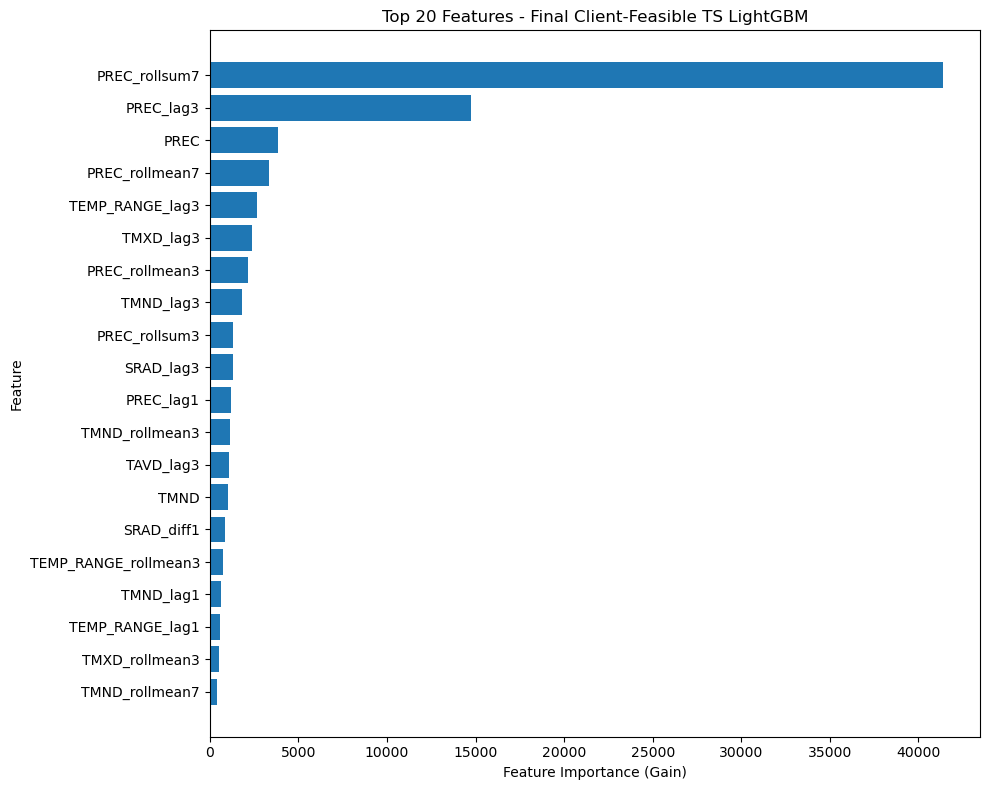


Top 20 final TS features:
['PREC_rollsum7', 'PREC_lag3', 'PREC', 'PREC_rollmean7', 'TEMP_RANGE_lag3', 'TMXD_lag3', 'PREC_rollmean3', 'TMND_lag3', 'PREC_rollsum3', 'SRAD_lag3', 'PREC_lag1', 'TMND_rollmean3', 'TAVD_lag3', 'TMND', 'SRAD_diff1', 'TEMP_RANGE_rollmean3', 'TMND_lag1', 'TEMP_RANGE_lag1', 'TMXD_rollmean3', 'TMND_rollmean7']


In [34]:
# ============================================================
# SECTION 34: FINAL CLIENT-FEASIBLE TS MODEL GLOBAL FEATURE IMPORTANCE
# ============================================================


from lightgbm import LGBMClassifier
import matplotlib.pyplot as plt

# Fit final Client-Feasible TS model on full Stage 1 dataset
X_final_client_ts = X_client_ts_clean.copy()
y_final_client_ts = y.copy()

# fill remaining structural NaNs using full-data medians for final interpretation model
final_client_ts_medians = X_final_client_ts.median(numeric_only=True)
X_final_client_ts = X_final_client_ts.fillna(final_client_ts_medians)

print("FINAL CLIENT-FEASIBLE TS MODEL DATA SHAPE:", X_final_client_ts.shape)
print("Remaining NaNs in final X:", int(X_final_client_ts.isna().sum().sum()))

final_client_ts_model = LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

final_client_ts_model.fit(X_final_client_ts, y_final_client_ts)

# Build feature importance table
client_ts_importance_df = pd.DataFrame({
    "feature": X_final_client_ts.columns,
    "importance_gain": final_client_ts_model.booster_.feature_importance(importance_type="gain"),
    "importance_split": final_client_ts_model.booster_.feature_importance(importance_type="split")
})

client_ts_importance_df = client_ts_importance_df.sort_values(
    by=["importance_gain", "importance_split"],
    ascending=[False, False]
).reset_index(drop=True)

client_ts_importance_df["importance_gain"] = client_ts_importance_df["importance_gain"].round(6)
client_ts_importance_df.index = range(1, len(client_ts_importance_df) + 1)

print("FINAL CLIENT-FEASIBLE TS FEATURE IMPORTANCE")
display(client_ts_importance_df.head(20))

# Plot top 20 features by gain
top_n = 20
plot_df = client_ts_importance_df.head(top_n).sort_values("importance_gain", ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(plot_df["feature"], plot_df["importance_gain"])
plt.xlabel("Feature Importance (Gain)")
plt.ylabel("Feature")
plt.title("Top 20 Features - Final Client-Feasible TS LightGBM")
plt.tight_layout()
plt.show()

# Helpful exports for later SHAP / reporting
final_client_ts_feature_list = client_ts_importance_df["feature"].tolist()
top20_client_ts_features = client_ts_importance_df.head(20)["feature"].tolist()

print("\nTop 20 final TS features:")
print(top20_client_ts_features)


## Feature Importance Summary

The final recommended model is driven mostly by recent precipitation patterns, especially 7-day accumulated precipitation and short-term precipitation history.

The next most important signals come from recent temperature behavior, including temperature range, maximum temperature, minimum temperature, and short rolling averages. Solar radiation also contributes, but less strongly.

Overall, this supports the conclusion that the model performs best when it can use recent weather history rather than only same-day measurements.

# Stage 2B: SHAP Explanation of the Final Recommended Model

Feature importance shows which variables the model relies on, but it does not show whether high or low values push predictions toward a higher alert risk. SHAP helps answer that question.

In this section, SHAP is used to explain the final Client-Feasible TS LightGBM model at both the global and local level. The global view shows the strongest overall drivers. The local examples show why the model gives a high-risk or low-risk prediction for specific observations.

This is especially helpful for client handoff because the final model is not just accurate; it also needs to be explainable enough to support decision-making.

X_shap shape: (6164, 46)
Remaining NaNs in X_shap: 0
X_shap_sample shape: (2000, 46)
SHAP array shape: (2000, 46)
GLOBAL SHAP IMPORTANCE (TOP 20)


,feature,mean_abs_shap
1,PREC_rollsum7,7.309780
2,PREC_lag3,2.369135
3,TEMP_RANGE_lag3,0.718661
4,PREC,0.685725
5,PREC_rollmean7,0.481625
6,PREC_lag1,0.473102
7,TMND_lag3,0.315685
8,PREC_rollmean3,0.315443
9,TMXD_lag3,0.283838
10,SRAD_lag3,0.263472


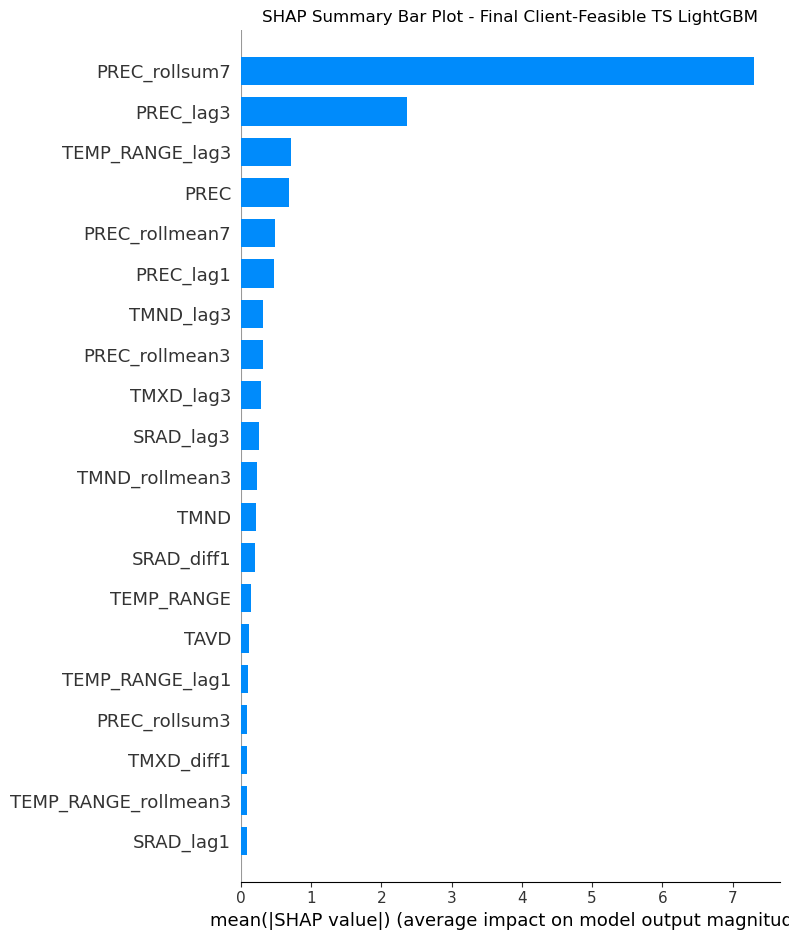

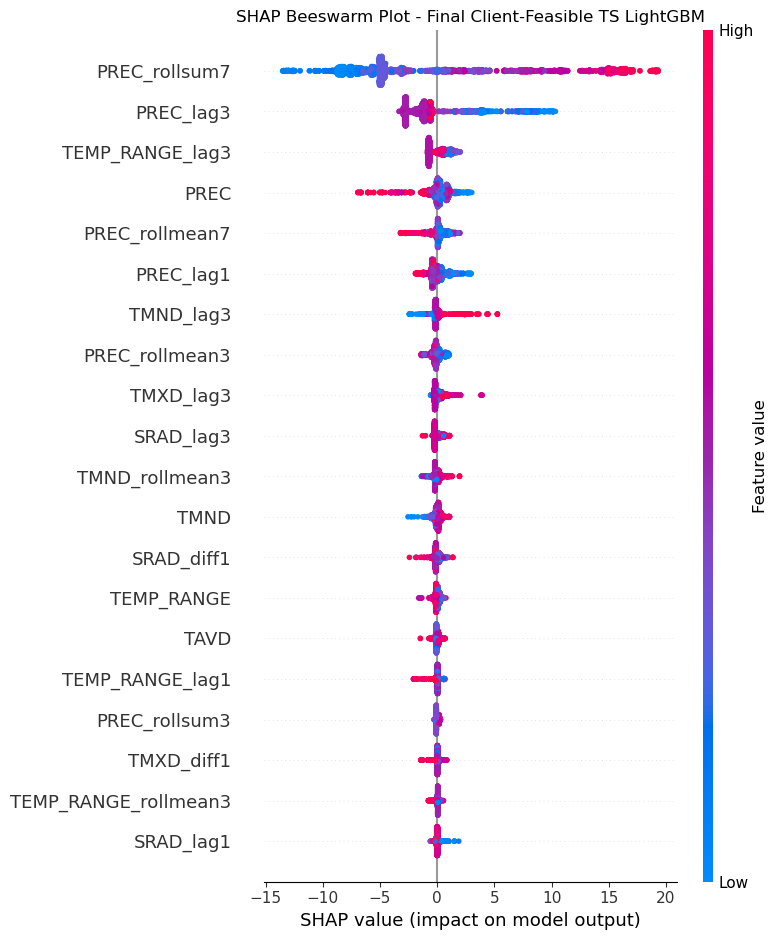


Top 20 SHAP features:
['PREC_rollsum7', 'PREC_lag3', 'TEMP_RANGE_lag3', 'PREC', 'PREC_rollmean7', 'PREC_lag1', 'TMND_lag3', 'PREC_rollmean3', 'TMXD_lag3', 'SRAD_lag3', 'TMND_rollmean3', 'TMND', 'SRAD_diff1', 'TEMP_RANGE', 'TAVD', 'TEMP_RANGE_lag1', 'PREC_rollsum3', 'TMXD_diff1', 'TEMP_RANGE_rollmean3', 'SRAD_lag1']


In [35]:
# ============================================================
# SECTION 35: SHAP GLOBAL EXPLANATION Final Client-Feasible TS LightGBM
# ============================================================


import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Prepare final modeling matrix used for explanation
X_shap = X_client_ts_clean.copy()
X_shap = X_shap.fillna(final_client_ts_medians)

print("X_shap shape:", X_shap.shape)
print("Remaining NaNs in X_shap:", int(X_shap.isna().sum().sum()))

# use a manageable sample for faster SHAP if desired
shap_sample_size = min(2000, len(X_shap))
X_shap_sample = X_shap.sample(n=shap_sample_size, random_state=42).copy()

print("X_shap_sample shape:", X_shap_sample.shape)

# Compute SHAP values
explainer = shap.TreeExplainer(final_client_ts_model)
shap_values = explainer.shap_values(X_shap_sample)

# handle binary-class output shape differences across SHAP versions
if isinstance(shap_values, list):
    shap_values_plot = shap_values[1]
else:
    shap_values_plot = shap_values

print("SHAP array shape:", np.array(shap_values_plot).shape)

# Global mean absolute SHAP table
mean_abs_shap = np.abs(shap_values_plot).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "feature": X_shap_sample.columns,
    "mean_abs_shap": mean_abs_shap
}).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

shap_importance_df["mean_abs_shap"] = shap_importance_df["mean_abs_shap"].round(6)
shap_importance_df.index = range(1, len(shap_importance_df) + 1)

print("GLOBAL SHAP IMPORTANCE (TOP 20)")
display(shap_importance_df.head(20))

# SHAP summary bar plot
plt.figure()
shap.summary_plot(
    shap_values_plot,
    X_shap_sample,
    plot_type="bar",
    max_display=20,
    show=False
)
plt.title("SHAP Summary Bar Plot - Final Client-Feasible TS LightGBM")
plt.tight_layout()
plt.show()

# SHAP beeswarm summary plot
plt.figure()
shap.summary_plot(
    shap_values_plot,
    X_shap_sample,
    max_display=20,
    show=False
)
plt.title("SHAP Beeswarm Plot - Final Client-Feasible TS LightGBM")
plt.tight_layout()
plt.show()

# Keep these lists for reporting and interpretation.
top20_shap_features = shap_importance_df.head(20)["feature"].tolist()

print("\nTop 20 SHAP features:")
print(top20_shap_features)


### Interpreting the Global SHAP Results

The global SHAP results show that the final recommended model is driven primarily by **recent precipitation history**, especially variables such as `PREC_rollsum7`, `PREC_lag3`, `PREC`, `PREC_rollmean7`, and `PREC_lag1`. This means the model relies more on recent accumulated and short-term precipitation patterns than on a single same-day value.

After precipitation-related features, the next influential signals come from **recent temperature behavior**, including lagged temperature range, maximum temperature, minimum temperature, and short rolling averages.

This helps explain why the Client-Feasible TS LightGBM performed better than the raw same-day client-feasible model on the forward time-holdout test. The improvement appears to come from adding past-looking temporal context rather than from adding less practical variables.

Highest-risk sampled row index: 219
Highest-risk predicted probability: 1.0

Lowest-risk sampled row index: 4412
Lowest-risk predicted probability: 0.0

SHAP WATERFALL: HIGHEST-RISK EXAMPLE


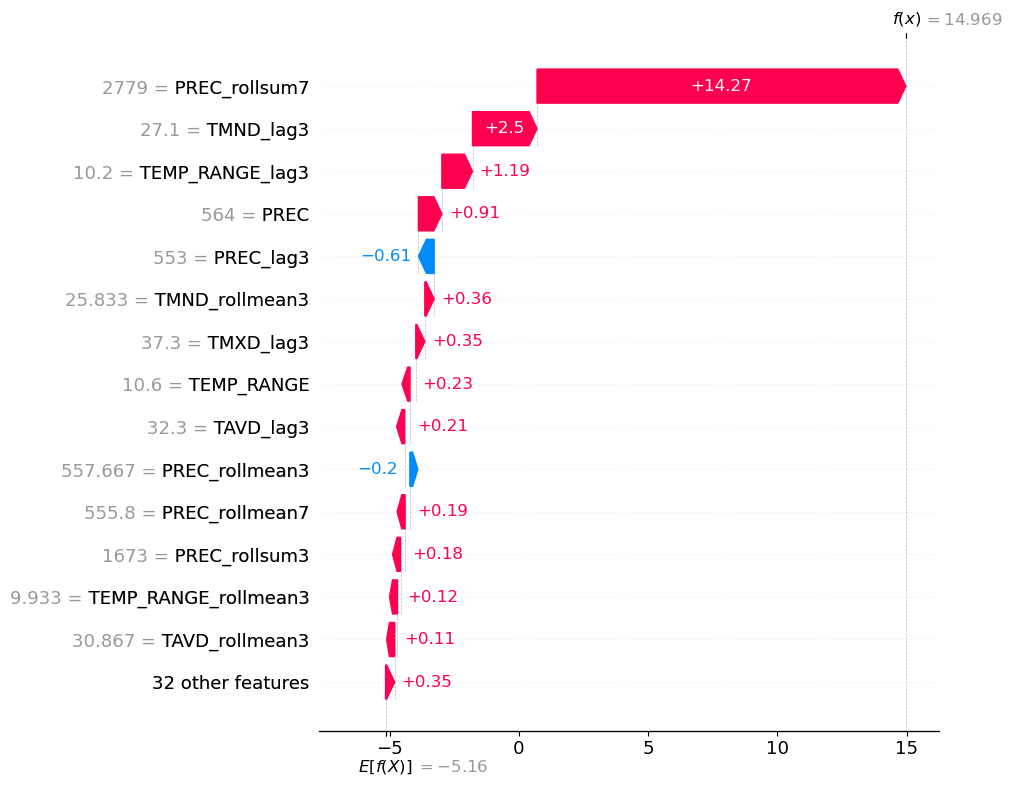


SHAP WATERFALL: LOWEST-RISK EXAMPLE


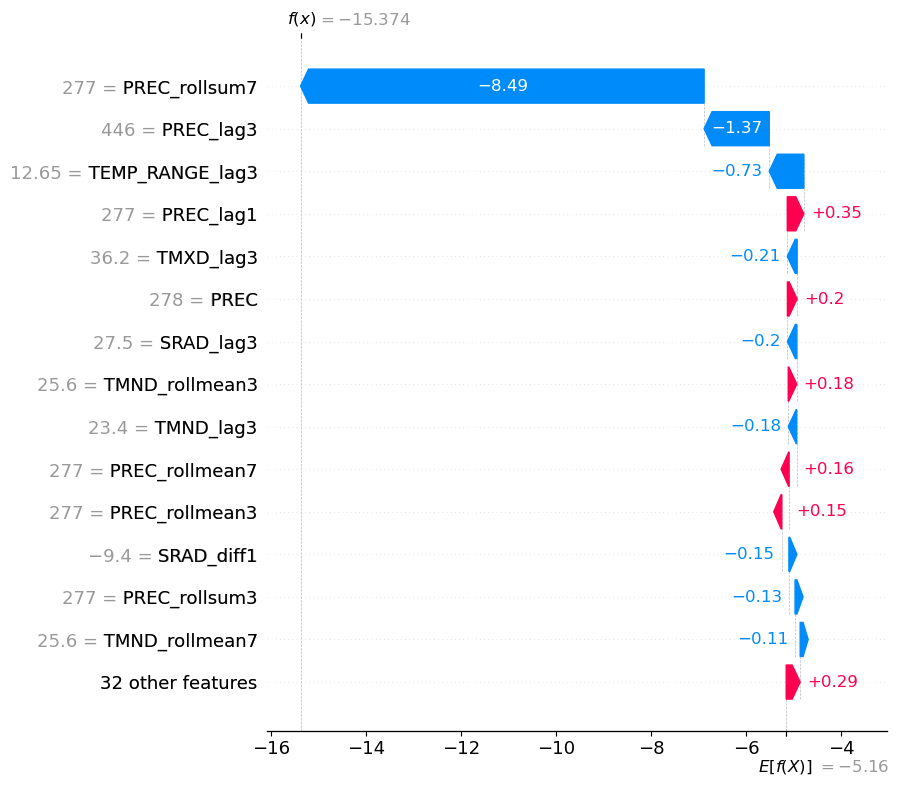

In [36]:
# ============================================================
# SECTION 36: SHAP LOCAL EXPLANATION EXAMPLES Show highest-risk and lowest-risk examples
# ============================================================


# predicted probabilities on the same SHAP sample
sample_pred_proba = final_client_ts_model.predict_proba(X_shap_sample)[:, 1]

shap_local_df = X_shap_sample.copy()
shap_local_df["pred_proba"] = sample_pred_proba

highest_idx = shap_local_df["pred_proba"].idxmax()
lowest_idx = shap_local_df["pred_proba"].idxmin()

print("Highest-risk sampled row index:", highest_idx)
print("Highest-risk predicted probability:", round(float(shap_local_df.loc[highest_idx, 'pred_proba']), 6))

print("\nLowest-risk sampled row index:", lowest_idx)
print("Lowest-risk predicted probability:", round(float(shap_local_df.loc[lowest_idx, 'pred_proba']), 6))

# map from dataframe index to row position inside the SHAP sample matrix
sample_index_list = list(X_shap_sample.index)
highest_pos = sample_index_list.index(highest_idx)
lowest_pos = sample_index_list.index(lowest_idx)

# waterfall plot for highest-risk example
print("\nSHAP WATERFALL: HIGHEST-RISK EXAMPLE")
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_plot[highest_pos],
        base_values=explainer.expected_value[1] if isinstance(explainer.expected_value, (list, np.ndarray)) and np.ndim(explainer.expected_value) > 0 else explainer.expected_value,
        data=X_shap_sample.iloc[highest_pos],
        feature_names=X_shap_sample.columns.tolist()
    ),
    max_display=15
)

# waterfall plot for lowest-risk example
print("\nSHAP WATERFALL: LOWEST-RISK EXAMPLE")
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_plot[lowest_pos],
        base_values=explainer.expected_value[1] if isinstance(explainer.expected_value, (list, np.ndarray)) and np.ndim(explainer.expected_value) > 0 else explainer.expected_value,
        data=X_shap_sample.iloc[lowest_pos],
        feature_names=X_shap_sample.columns.tolist()
    ),
    max_display=15
)


### Interpreting the Local SHAP Results

The local SHAP waterfall plots show why the model produced very high-risk and very low-risk predictions for specific sampled observations.

In the highest-risk example, the prediction was pushed upward most strongly by high recent accumulated precipitation, especially `PREC_rollsum7`. Recent temperature-related features also reinforced the high-risk prediction.

In the lowest-risk example, the opposite pattern appeared. Lower recent precipitation accumulation pushed the prediction downward and supported a low probability of entering GSTD 5 soon.

Together, these examples show that the model is using recent weather history in a consistent way: it raises risk when the recent pattern looks similar to transition cases in the training data and lowers risk when it does not.

In [37]:
# ============================================================
# SECTION 37: YEAR-BY-YEAR TIME-HOLDOUT PERFORMANCE Final Client-Feasible TS LightGBM
# ============================================================


from sklearn.metrics import roc_auc_score, average_precision_score

# build evaluation table from the already-created future holdout set
yearly_time_eval_df = test_client_ts_df[["RUNNO", "DATE", "YEAR_ONLY", "y_enter5_7"]].copy()
yearly_time_eval_df["pred_proba"] = y_pred_time_client_ts

yearly_results = []

for yr in sorted(yearly_time_eval_df["YEAR_ONLY"].unique()):
    yr_df = yearly_time_eval_df[yearly_time_eval_df["YEAR_ONLY"] == yr].copy()

    row = {
        "year": int(yr),
        "rows": len(yr_df),
        "runs": yr_df["RUNNO"].nunique(),
        "positive_rate": round(float(yr_df["y_enter5_7"].mean()), 4)
    }

    if yr_df["y_enter5_7"].nunique() < 2:
        row["roc_auc"] = np.nan
        row["pr_auc"] = np.nan
        row["status"] = "Skipped: only one class present"
    else:
        row["roc_auc"] = round(float(roc_auc_score(yr_df["y_enter5_7"], yr_df["pred_proba"])), 4)
        row["pr_auc"] = round(float(average_precision_score(yr_df["y_enter5_7"], yr_df["pred_proba"])), 4)
        row["status"] = "OK"

    yearly_results.append(row)

yearly_time_perf_df = pd.DataFrame(yearly_results)

print("YEAR-BY-YEAR TIME-HOLDOUT PERFORMANCE")
display(yearly_time_perf_df)

# Create a compact year-by-year summary.
valid_yearly_time_perf_df = yearly_time_perf_df[yearly_time_perf_df["status"] == "OK"].copy()

if len(valid_yearly_time_perf_df) > 0:
    yearly_time_summary_df = pd.DataFrame([{
        "years_evaluated": len(valid_yearly_time_perf_df),
        "mean_roc_auc": round(float(valid_yearly_time_perf_df["roc_auc"].mean()), 4),
        "median_roc_auc": round(float(valid_yearly_time_perf_df["roc_auc"].median()), 4),
        "min_roc_auc": round(float(valid_yearly_time_perf_df["roc_auc"].min()), 4),
        "max_roc_auc": round(float(valid_yearly_time_perf_df["roc_auc"].max()), 4),
        "mean_pr_auc": round(float(valid_yearly_time_perf_df["pr_auc"].mean()), 4),
        "median_pr_auc": round(float(valid_yearly_time_perf_df["pr_auc"].median()), 4),
        "min_pr_auc": round(float(valid_yearly_time_perf_df["pr_auc"].min()), 4),
        "max_pr_auc": round(float(valid_yearly_time_perf_df["pr_auc"].max()), 4)
    }])

    print("\nYEAR-BY-YEAR TIME-HOLDOUT SUMMARY")
    display(yearly_time_summary_df)


YEAR-BY-YEAR TIME-HOLDOUT PERFORMANCE


,year,rows,runs,positive_rate,roc_auc,pr_auc,status
0,2045,210,35,0.3333,0.9820,0.9700,OK
1,2046,228,35,0.2719,0.8961,0.8081,OK
2,2047,213,35,0.3286,0.9936,0.9883,OK
3,2048,229,35,0.2707,0.9660,0.8987,OK
4,2049,218,35,0.3211,0.9606,0.8887,OK
5,2050,213,35,0.3286,0.9199,0.7455,OK



YEAR-BY-YEAR TIME-HOLDOUT SUMMARY


,years_evaluated,mean_roc_auc,median_roc_auc,min_roc_auc,max_roc_auc,mean_pr_auc,median_pr_auc,min_pr_auc,max_pr_auc
0,6,0.953,0.9633,0.8961,0.9936,0.8832,0.8937,0.7455,0.9883


# Stage 3: LAID Sensitivity Testing

LAID was tested because the client specifically raised LAI/LAID as a biologically meaningful variable. This section checks whether adding LAID improves the Task B 7-day GSTD 5 alert model.

We test LAID in two ways:

1. **Client-6 + LAID**, which adds LAID to the six raw client-feasible inputs.  
2. **Client-6 + LAID + TS**, which adds lagged and rolling time-series features after LAID is included.

This lets us separate the value of LAID by itself from the value of time-series context.

In [38]:
# ============================================================
# SECTION 38: TASK B USING CLIENT-6 + LAID Honest evaluation: GroupKFold by RUNNO
# ============================================================


from lightgbm import LGBMClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score

# Resolve LAI / LAID
laid_col = None
if "LAID" in model_df.columns:
    laid_col = "LAID"
elif "LAI" in model_df.columns:
    laid_col = "LAI"
else:
    raise ValueError("Neither LAID nor LAI exists in model_df.")

# Build feature set: client-6 + LAID
client6_laid_features = available_client_core + [laid_col]
client6_laid_features = list(dict.fromkeys(client6_laid_features))  # avoid duplicates

missing_cols = [c for c in client6_laid_features if c not in model_df.columns]
if missing_cols:
    raise ValueError(f"Missing columns in model_df: {missing_cols}")

X_client6_laid = model_df[client6_laid_features].copy()

print("USING FEATURES:")
print(client6_laid_features)
print("\nX_client6_laid shape:", X_client6_laid.shape)

# GroupKFold by RUNNO
gkf = GroupKFold(n_splits=5)

client6_laid_lgbm = LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

oof_pred_client6_laid = np.zeros(len(X_client6_laid))
client6_laid_fold_results = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_client6_laid, y, groups=groups), start=1):
    X_train = X_client6_laid.iloc[train_idx].copy()
    X_val   = X_client6_laid.iloc[val_idx].copy()
    y_train = y.iloc[train_idx].copy()
    y_val   = y.iloc[val_idx].copy()

    train_runs = pd.Series(groups).iloc[train_idx].nunique()
    val_runs   = pd.Series(groups).iloc[val_idx].nunique()

    client6_laid_lgbm.fit(X_train, y_train)
    val_pred = client6_laid_lgbm.predict_proba(X_val)[:, 1]
    oof_pred_client6_laid[val_idx] = val_pred

    client6_laid_fold_results.append({
        "fold": fold,
        "train_rows": len(train_idx),
        "val_rows": len(val_idx),
        "train_runs": int(train_runs),
        "val_runs": int(val_runs),
        "val_positive_rate": round(float(y_val.mean()), 4),
        "roc_auc": round(float(roc_auc_score(y_val, val_pred)), 4),
        "pr_auc": round(float(average_precision_score(y_val, val_pred)), 4)
    })

client6_laid_fold_results_df = pd.DataFrame(client6_laid_fold_results)

print("\nCLIENT-6 + LAID GROUPKFOLD RESULTS")
display(client6_laid_fold_results_df)

client6_laid_oof_roc_auc = roc_auc_score(y, oof_pred_client6_laid)
client6_laid_oof_pr_auc  = average_precision_score(y, oof_pred_client6_laid)

print("\nCLIENT-6 + LAID OVERALL OOF PERFORMANCE")
print(f"OOF ROC-AUC: {client6_laid_oof_roc_auc:.4f}")
print(f"OOF PR-AUC : {client6_laid_oof_pr_auc:.4f}")

# Quick comparison vs earlier Task B models
client6_laid_compare_df = pd.DataFrame([
    {
        "model_version": "Client-Feasible LightGBM",
        "feature_count": len(available_client_core),
        "oof_roc_auc": round(float(client_core_oof_roc_auc), 4),
        "oof_pr_auc": round(float(client_core_oof_pr_auc), 4)
    },
    {
        "model_version": "Client-6 + LAID LightGBM",
        "feature_count": len(client6_laid_features),
        "oof_roc_auc": round(float(client6_laid_oof_roc_auc), 4),
        "oof_pr_auc": round(float(client6_laid_oof_pr_auc), 4)
    }
])

client6_laid_compare_df["pr_auc_gain_vs_client6"] = (
    client6_laid_compare_df["oof_pr_auc"] - float(client_core_oof_pr_auc)
).round(4)

print("\nCLIENT-6 VS CLIENT-6 + LAID COMPARISON")
display(client6_laid_compare_df)


USING FEATURES:
['TMND', 'PREC', 'SRAD', 'TMXD', 'TAVD', 'NURTD', 'LAID']

X_client6_laid shape: (6164, 7)

CLIENT-6 + LAID GROUPKFOLD RESULTS


,fold,train_rows,val_rows,train_runs,val_runs,val_positive_rate,roc_auc,pr_auc
0,1,4931,1233,784,196,0.3260,0.9993,0.9987
1,2,4931,1233,784,196,0.3268,0.9980,0.9939
2,3,4931,1233,784,196,0.3293,0.9989,0.9976
3,4,4931,1233,784,196,0.3228,0.9975,0.9954
4,5,4932,1232,784,196,0.3279,0.9975,0.9871



CLIENT-6 + LAID OVERALL OOF PERFORMANCE
OOF ROC-AUC: 0.9983
OOF PR-AUC : 0.9946

CLIENT-6 VS CLIENT-6 + LAID COMPARISON


,model_version,feature_count,oof_roc_auc,oof_pr_auc,pr_auc_gain_vs_client6
0,Client-Feasible LightGBM,6,0.9998,0.9996,-0.000
1,Client-6 + LAID LightGBM,7,0.9983,0.9946,-0.005


In [39]:
# ============================================================
# SECTION 39: TASK B USING CLIENT-6 + LAID TIME-BASED HOLDOUT ROBUSTNESS TEST Train on 2023-2044, test on 2045-2050
# ============================================================


from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# rebuild evaluation table with aligned target
time_client6_laid_df = model_df[["RUNNO", "TRTNO", "DATE"] + client6_laid_features].reset_index(drop=True).copy()
time_client6_laid_df["DATE"] = pd.to_datetime(time_client6_laid_df["DATE"], errors="coerce")
time_client6_laid_df["YEAR_ONLY"] = time_client6_laid_df["DATE"].dt.year
time_client6_laid_df["y_enter5_7"] = y.reset_index(drop=True).astype(int)

needed_cols_client6_laid = ["RUNNO", "TRTNO", "DATE", "YEAR_ONLY", "y_enter5_7"] + client6_laid_features
time_client6_laid_df = time_client6_laid_df[needed_cols_client6_laid].dropna(subset=["YEAR_ONLY", "y_enter5_7"]).copy()
time_client6_laid_df["YEAR_ONLY"] = time_client6_laid_df["YEAR_ONLY"].astype(int)
time_client6_laid_df["y_enter5_7"] = time_client6_laid_df["y_enter5_7"].astype(int)

# forward time split
train_mask_client6_laid = time_client6_laid_df["YEAR_ONLY"] <= 2044
test_mask_client6_laid  = time_client6_laid_df["YEAR_ONLY"] >= 2045

train_client6_laid_df = time_client6_laid_df.loc[train_mask_client6_laid].copy()
test_client6_laid_df  = time_client6_laid_df.loc[test_mask_client6_laid].copy()

X_train_time_client6_laid = train_client6_laid_df[client6_laid_features].copy()
y_train_time_client6_laid = train_client6_laid_df["y_enter5_7"].copy()

X_test_time_client6_laid = test_client6_laid_df[client6_laid_features].copy()
y_test_time_client6_laid = test_client6_laid_df["y_enter5_7"].copy()

print("Train years:", clean_year_list(train_client6_laid_df["YEAR_ONLY"]))
print("Test years:", clean_year_list(test_client6_laid_df["YEAR_ONLY"]))

print("\nTrain shape:", X_train_time_client6_laid.shape)
print("Test shape:", X_test_time_client6_laid.shape)

print("\nTrain runs:", train_client6_laid_df["RUNNO"].nunique())
print("Test runs:", test_client6_laid_df["RUNNO"].nunique())

print("\nTrain treatments:", train_client6_laid_df["TRTNO"].nunique())
print("Test treatments:", test_client6_laid_df["TRTNO"].nunique())

print("\nTrain positives:", int(y_train_time_client6_laid.sum()), "rate =", round(float(y_train_time_client6_laid.mean()), 4))
print("Test positives:", int(y_test_time_client6_laid.sum()), "rate =", round(float(y_test_time_client6_laid.mean()), 4))

client6_laid_time_model = LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

client6_laid_time_model.fit(X_train_time_client6_laid, y_train_time_client6_laid)
y_pred_time_client6_laid = client6_laid_time_model.predict_proba(X_test_time_client6_laid)[:, 1]

client6_laid_time_roc = roc_auc_score(y_test_time_client6_laid, y_pred_time_client6_laid)
client6_laid_time_pr  = average_precision_score(y_test_time_client6_laid, y_pred_time_client6_laid)

print("\nCLIENT-6 + LAID TIME HOLDOUT ROC-AUC:", round(float(client6_laid_time_roc), 4))
print("CLIENT-6 + LAID TIME HOLDOUT PR-AUC:", round(float(client6_laid_time_pr), 4))

client6_laid_time_summary_df = pd.DataFrame([{
    "model_version": "Client-6 + LAID LightGBM",
    "evaluation": "Time holdout (2023-2044 train, 2045-2050 test)",
    "feature_count": len(client6_laid_features),
    "train_rows": len(train_client6_laid_df),
    "test_rows": len(test_client6_laid_df),
    "train_runs": train_client6_laid_df["RUNNO"].nunique(),
    "test_runs": test_client6_laid_df["RUNNO"].nunique(),
    "train_treatments": train_client6_laid_df["TRTNO"].nunique(),
    "test_treatments": test_client6_laid_df["TRTNO"].nunique(),
    "train_positive_rate": round(float(y_train_time_client6_laid.mean()), 4),
    "test_positive_rate": round(float(y_test_time_client6_laid.mean()), 4),
    "roc_auc": round(float(client6_laid_time_roc), 4),
    "pr_auc": round(float(client6_laid_time_pr), 4)
}])

print("\nCLIENT-6 + LAID TIME-HOLDOUT ROBUSTNESS SUMMARY")
display(client6_laid_time_summary_df)


Train years: [2023, 2024, 2025, 2026, 2027, 2028, 2029, 2030, 2031, 2032, 2033, 2034, 2035, 2036, 2037, 2038, 2039, 2040, 2041, 2042, 2043, 2044]
Test years: [2045, 2046, 2047, 2048, 2049, 2050]

Train shape: (4853, 7)
Test shape: (1311, 7)

Train runs: 770
Test runs: 210

Train treatments: 35
Test treatments: 35

Train positives: 1609 rate = 0.3315
Test positives: 404 rate = 0.3082

CLIENT-6 + LAID TIME HOLDOUT ROC-AUC: 0.6902
CLIENT-6 + LAID TIME HOLDOUT PR-AUC: 0.5449

CLIENT-6 + LAID TIME-HOLDOUT ROBUSTNESS SUMMARY


,model_version,evaluation,feature_count,train_rows,test_rows,train_runs,test_runs,train_treatments,test_treatments,train_positive_rate,test_positive_rate,roc_auc,pr_auc
0,Client-6 + LAID LightGBM,"Time holdout (2023-2044 train, 2045-2050 test)",7,4853,1311,770,210,35,35,0.3315,0.3082,0.6902,0.5449


In [40]:
# ============================================================
# SECTION 40: TASK B USING CLIENT-6 + LAID LEAVE-ONE-TREATMENT-OUT (LOTO) ROBUSTNESS TEST
# ============================================================


from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# rebuild treatment evaluation table with aligned target
treatment_client6_laid_df = model_df[["RUNNO", "TRTNO", "DATE"] + client6_laid_features].reset_index(drop=True).copy()
treatment_client6_laid_df["DATE"] = pd.to_datetime(treatment_client6_laid_df["DATE"], errors="coerce")
treatment_client6_laid_df["y_enter5_7"] = y.reset_index(drop=True).astype(int)

needed_cols_client6_laid_loto = ["RUNNO", "TRTNO", "DATE", "y_enter5_7"] + client6_laid_features
treatment_client6_laid_df = treatment_client6_laid_df[needed_cols_client6_laid_loto].dropna(subset=["TRTNO", "y_enter5_7"]).copy()
treatment_client6_laid_df["TRTNO"] = treatment_client6_laid_df["TRTNO"].astype(int)
treatment_client6_laid_df["y_enter5_7"] = treatment_client6_laid_df["y_enter5_7"].astype(int)

print("CLIENT-6 + LAID TREATMENT ROBUSTNESS DATA SHAPE:", treatment_client6_laid_df.shape)
print("UNIQUE TRTNO VALUES:", sorted(treatment_client6_laid_df["TRTNO"].unique()))
print("UNIQUE RUNS:", treatment_client6_laid_df["RUNNO"].nunique())
print("OVERALL POSITIVE RATE:", round(float(treatment_client6_laid_df["y_enter5_7"].mean()), 4))

client6_laid_loto_results = []
client6_laid_loto_oof_pred = np.full(len(treatment_client6_laid_df), np.nan)

unique_treatments_client6_laid = sorted(treatment_client6_laid_df["TRTNO"].unique())

for held_out_trt in unique_treatments_client6_laid:
    train_fold_df = treatment_client6_laid_df[treatment_client6_laid_df["TRTNO"] != held_out_trt].copy()
    test_fold_df  = treatment_client6_laid_df[treatment_client6_laid_df["TRTNO"] == held_out_trt].copy()

    X_train_loto_client6_laid = train_fold_df[client6_laid_features].copy()
    y_train_loto_client6_laid = train_fold_df["y_enter5_7"].copy()

    X_test_loto_client6_laid = test_fold_df[client6_laid_features].copy()
    y_test_loto_client6_laid = test_fold_df["y_enter5_7"].copy()

    row = {
        "held_out_trtno": int(held_out_trt),
        "train_rows": len(train_fold_df),
        "test_rows": len(test_fold_df),
        "train_runs": train_fold_df["RUNNO"].nunique(),
        "test_runs": test_fold_df["RUNNO"].nunique(),
        "train_positive_rate": round(float(y_train_loto_client6_laid.mean()), 4),
        "test_positive_rate": round(float(y_test_loto_client6_laid.mean()), 4),
        "train_unique_classes": int(y_train_loto_client6_laid.nunique()),
        "test_unique_classes": int(y_test_loto_client6_laid.nunique())
    }

    if y_train_loto_client6_laid.nunique() < 2 or y_test_loto_client6_laid.nunique() < 2:
        row["roc_auc"] = np.nan
        row["pr_auc"] = np.nan
        row["status"] = "Skipped: class imbalance in train/test fold"
        client6_laid_loto_results.append(row)
        continue

    client6_laid_loto_model = LGBMClassifier(
        objective="binary",
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=20,
        subsample=0.8,
        colsample_bytree=0.8,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    client6_laid_loto_model.fit(X_train_loto_client6_laid, y_train_loto_client6_laid)
    y_pred_loto_client6_laid = client6_laid_loto_model.predict_proba(X_test_loto_client6_laid)[:, 1]

    client6_laid_loto_oof_pred[test_fold_df.index] = y_pred_loto_client6_laid

    row["roc_auc"] = round(float(roc_auc_score(y_test_loto_client6_laid, y_pred_loto_client6_laid)), 4)
    row["pr_auc"] = round(float(average_precision_score(y_test_loto_client6_laid, y_pred_loto_client6_laid)), 4)
    row["status"] = "OK"
    client6_laid_loto_results.append(row)

client6_laid_loto_results_df = pd.DataFrame(client6_laid_loto_results).sort_values("held_out_trtno").reset_index(drop=True)

print("\nCLIENT-6 + LAID LOTO RESULTS")
display(client6_laid_loto_results_df)

valid_client6_laid_loto_df = client6_laid_loto_results_df[client6_laid_loto_results_df["status"] == "OK"].copy()

if len(valid_client6_laid_loto_df) > 0:
    client6_laid_loto_summary_df = pd.DataFrame([{
        "model_version": "Client-6 + LAID LightGBM",
        "evaluation": "Leave-one-treatment-out by TRTNO",
        "feature_count": len(client6_laid_features),
        "num_treatments_total": len(unique_treatments_client6_laid),
        "num_valid_treatments": len(valid_client6_laid_loto_df),
        "mean_roc_auc": round(float(valid_client6_laid_loto_df["roc_auc"].mean()), 4),
        "median_roc_auc": round(float(valid_client6_laid_loto_df["roc_auc"].median()), 4),
        "mean_pr_auc": round(float(valid_client6_laid_loto_df["pr_auc"].mean()), 4),
        "median_pr_auc": round(float(valid_client6_laid_loto_df["pr_auc"].median()), 4),
        "min_roc_auc": round(float(valid_client6_laid_loto_df["roc_auc"].min()), 4),
        "max_roc_auc": round(float(valid_client6_laid_loto_df["roc_auc"].max()), 4),
        "min_pr_auc": round(float(valid_client6_laid_loto_df["pr_auc"].min()), 4),
        "max_pr_auc": round(float(valid_client6_laid_loto_df["pr_auc"].max()), 4)
    }])

    print("\nCLIENT-6 + LAID LOTO SUMMARY")
    display(client6_laid_loto_summary_df)
else:
    print("\nNo valid Client-6 + LAID treatment-held-out folds had both classes in train and test.")

valid_client6_laid_pred_mask = ~np.isnan(client6_laid_loto_oof_pred)

if valid_client6_laid_pred_mask.sum() > 0 and treatment_client6_laid_df.loc[valid_client6_laid_pred_mask, "y_enter5_7"].nunique() > 1:
    pooled_client6_laid_loto_roc = roc_auc_score(
        treatment_client6_laid_df.loc[valid_client6_laid_pred_mask, "y_enter5_7"],
        client6_laid_loto_oof_pred[valid_client6_laid_pred_mask]
    )
    pooled_client6_laid_loto_pr = average_precision_score(
        treatment_client6_laid_df.loc[valid_client6_laid_pred_mask, "y_enter5_7"],
        client6_laid_loto_oof_pred[valid_client6_laid_pred_mask]
    )

    pooled_client6_laid_loto_df = pd.DataFrame([{
        "model_version": "Client-6 + LAID LightGBM",
        "evaluation": "Pooled leave-one-treatment-out predictions",
        "feature_count": len(client6_laid_features),
        "rows_scored": int(valid_client6_laid_pred_mask.sum()),
        "pooled_roc_auc": round(float(pooled_client6_laid_loto_roc), 4),
        "pooled_pr_auc": round(float(pooled_client6_laid_loto_pr), 4)
    }])

    print("\nCLIENT-6 + LAID POOLED LOTO PERFORMANCE")
    display(pooled_client6_laid_loto_df)
else:
    print("\nPooled Client-6 + LAID LOTO performance could not be computed.")


CLIENT-6 + LAID TREATMENT ROBUSTNESS DATA SHAPE: (6164, 11)
UNIQUE TRTNO VALUES: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35)]
UNIQUE RUNS: 980
OVERALL POSITIVE RATE: 0.3266

CLIENT-6 + LAID LOTO RESULTS


,held_out_trtno,train_rows,test_rows,train_runs,test_runs,train_positive_rate,test_positive_rate,train_unique_classes,test_unique_classes,roc_auc,pr_auc,status
0,1,5994,170,952,28,0.3265,0.3294,2,2,1.0000,1.0000,OK
1,2,5994,170,952,28,0.3265,0.3294,2,2,1.0000,1.0000,OK
2,3,5994,170,952,28,0.3265,0.3294,2,2,1.0000,1.0000,OK
3,4,5994,170,952,28,0.3265,0.3294,2,2,1.0000,1.0000,OK
4,5,5994,170,952,28,0.3265,0.3294,2,2,1.0000,1.0000,OK
5,6,5994,170,952,28,0.3265,0.3294,2,2,1.0000,1.0000,OK
6,7,5994,170,952,28,0.3265,0.3294,2,2,0.9989,0.9980,OK
7,8,5994,170,952,28,0.3265,0.3294,2,2,0.9994,0.9988,OK
8,9,5985,179,952,28,0.3263,0.3352,2,2,1.0000,1.0000,OK
9,10,5985,179,952,28,0.3263,0.3352,2,2,1.0000,1.0000,OK



CLIENT-6 + LAID LOTO SUMMARY


,model_version,evaluation,feature_count,num_treatments_total,num_valid_treatments,mean_roc_auc,median_roc_auc,mean_pr_auc,median_pr_auc,min_roc_auc,max_roc_auc,min_pr_auc,max_pr_auc
0,Client-6 + LAID LightGBM,Leave-one-treatment-out by TRTNO,7,35,35,0.999,1.0,0.9977,1.0,0.9733,1.0,0.9365,1.0



CLIENT-6 + LAID POOLED LOTO PERFORMANCE


,model_version,evaluation,feature_count,rows_scored,pooled_roc_auc,pooled_pr_auc
0,Client-6 + LAID LightGBM,Pooled leave-one-treatment-out predictions,7,6164,0.9982,0.9937


In [41]:
# ============================================================
# SECTION 41: CLIENT-6 VS CLIENT-6 + LAID ROBUSTNESS COMPARISON TABLE
# ============================================================


client6_vs_laid_robustness_df = pd.DataFrame([
    {
        "model_version": "Client-Feasible LightGBM",
        "feature_type": "6 raw client-feasible features",
        "feature_count": int(len(available_client_core)),
        "groupkfold_roc_auc": round(float(client_core_oof_roc_auc), 4),
        "groupkfold_pr_auc": round(float(client_core_oof_pr_auc), 4),
        "time_holdout_roc_auc": round(float(time_client_roc), 4),
        "time_holdout_pr_auc": round(float(time_client_pr), 4),
        "treatment_loto_roc_auc": round(float(pooled_loto_roc), 4),
        "treatment_loto_pr_auc": round(float(pooled_loto_pr), 4),
        "notes": "Raw same-day client-approved inputs only."
    },
    {
        "model_version": "Client-6 + LAID LightGBM",
        "feature_type": "6 client features + LAID",
        "feature_count": int(len(client6_laid_features)),
        "groupkfold_roc_auc": round(float(client6_laid_oof_roc_auc), 4),
        "groupkfold_pr_auc": round(float(client6_laid_oof_pr_auc), 4),
        "time_holdout_roc_auc": round(float(client6_laid_time_roc), 4),
        "time_holdout_pr_auc": round(float(client6_laid_time_pr), 4),
        "treatment_loto_roc_auc": round(float(pooled_client6_laid_loto_roc), 4),
        "treatment_loto_pr_auc": round(float(pooled_client6_laid_loto_pr), 4),
        "notes": "Adds LAID as a biologically meaningful canopy-state feature."
    }
])

base_row = client6_vs_laid_robustness_df.loc[
    client6_vs_laid_robustness_df["model_version"] == "Client-Feasible LightGBM"
].iloc[0]

client6_vs_laid_robustness_df["groupkfold_pr_gain_vs_client6"] = (
    client6_vs_laid_robustness_df["groupkfold_pr_auc"] - base_row["groupkfold_pr_auc"]
).round(4)

client6_vs_laid_robustness_df["time_holdout_pr_gain_vs_client6"] = (
    client6_vs_laid_robustness_df["time_holdout_pr_auc"] - base_row["time_holdout_pr_auc"]
).round(4)

client6_vs_laid_robustness_df["treatment_loto_pr_gain_vs_client6"] = (
    client6_vs_laid_robustness_df["treatment_loto_pr_auc"] - base_row["treatment_loto_pr_auc"]
).round(4)

print("CLIENT-6 VS CLIENT-6 + LAID ROBUSTNESS COMPARISON")
display(client6_vs_laid_robustness_df)

client6_vs_laid_exec_df = client6_vs_laid_robustness_df[[
    "model_version",
    "feature_count",
    "groupkfold_roc_auc",
    "groupkfold_pr_auc",
    "time_holdout_roc_auc",
    "time_holdout_pr_auc",
    "treatment_loto_roc_auc",
    "treatment_loto_pr_auc"
]].copy()

print("\nEXECUTIVE SUMMARY COMPARISON")
display(client6_vs_laid_exec_df)


CLIENT-6 VS CLIENT-6 + LAID ROBUSTNESS COMPARISON


,model_version,feature_type,feature_count,groupkfold_roc_auc,groupkfold_pr_auc,time_holdout_roc_auc,time_holdout_pr_auc,treatment_loto_roc_auc,treatment_loto_pr_auc,notes,groupkfold_pr_gain_vs_client6,time_holdout_pr_gain_vs_client6,treatment_loto_pr_gain_vs_client6
0,Client-Feasible LightGBM,6 raw client-feasible features,6,0.9998,0.9996,0.5386,0.3468,0.9999,0.9997,Raw same-day client-approved inputs only.,0.000,0.0000,0.000
1,Client-6 + LAID LightGBM,6 client features + LAID,7,0.9983,0.9946,0.6902,0.5449,0.9982,0.9937,Adds LAID as a biologically meaningful canopy-state feature.,-0.005,0.1981,-0.006



EXECUTIVE SUMMARY COMPARISON


,model_version,feature_count,groupkfold_roc_auc,groupkfold_pr_auc,time_holdout_roc_auc,time_holdout_pr_auc,treatment_loto_roc_auc,treatment_loto_pr_auc
0,Client-Feasible LightGBM,6,0.9998,0.9996,0.5386,0.3468,0.9999,0.9997
1,Client-6 + LAID LightGBM,7,0.9983,0.9946,0.6902,0.5449,0.9982,0.9937


In [42]:
# ============================================================
# SECTION 42: TASK B USING CLIENT-6 + LAID + TS Honest evaluation: GroupKFold by RUNNO
# ============================================================


from lightgbm import LGBMClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score

# Resolve LAI / LAID
laid_col = None
if "LAID" in model_df.columns:
    laid_col = "LAID"
elif "LAI" in model_df.columns:
    laid_col = "LAI"
else:
    raise ValueError("Neither LAID nor LAI exists in model_df.")

# Build TS table from client-6 + LAID
client6_laid_ts_df = model_df[["RUNNO", "DATE"] + available_client_core + [laid_col]].reset_index(drop=True).copy()
client6_laid_ts_df["DATE"] = pd.to_datetime(client6_laid_ts_df["DATE"], errors="coerce")
client6_laid_ts_df = client6_laid_ts_df.sort_values(["RUNNO", "DATE"]).reset_index(drop=True)

# engineered feature
client6_laid_ts_df["TEMP_RANGE"] = client6_laid_ts_df["TMXD"] - client6_laid_ts_df["TMND"]

base_for_ts_laid = available_client_core + [laid_col, "TEMP_RANGE"]

for col in base_for_ts_laid:
    client6_laid_ts_df[f"{col}_lag1"] = client6_laid_ts_df.groupby("RUNNO")[col].shift(1)
    client6_laid_ts_df[f"{col}_lag3"] = client6_laid_ts_df.groupby("RUNNO")[col].shift(3)
    client6_laid_ts_df[f"{col}_diff1"] = client6_laid_ts_df.groupby("RUNNO")[col].diff(1)

    client6_laid_ts_df[f"{col}_rollmean3"] = (
        client6_laid_ts_df.groupby("RUNNO")[col]
        .transform(lambda s: s.shift(1).rolling(window=3, min_periods=1).mean())
    )
    client6_laid_ts_df[f"{col}_rollmean7"] = (
        client6_laid_ts_df.groupby("RUNNO")[col]
        .transform(lambda s: s.shift(1).rolling(window=7, min_periods=1).mean())
    )

# accumulation-style variables
client6_laid_ts_df["PREC_rollsum3"] = (
    client6_laid_ts_df.groupby("RUNNO")["PREC"]
    .transform(lambda s: s.shift(1).rolling(window=3, min_periods=1).sum())
)
client6_laid_ts_df["PREC_rollsum7"] = (
    client6_laid_ts_df.groupby("RUNNO")["PREC"]
    .transform(lambda s: s.shift(1).rolling(window=7, min_periods=1).sum())
)

client6_laid_ts_df["NURTD_rollsum3"] = (
    client6_laid_ts_df.groupby("RUNNO")["NURTD"]
    .transform(lambda s: s.shift(1).rolling(window=3, min_periods=1).sum())
)
client6_laid_ts_df["NURTD_rollsum7"] = (
    client6_laid_ts_df.groupby("RUNNO")["NURTD"]
    .transform(lambda s: s.shift(1).rolling(window=7, min_periods=1).sum())
)

# Build feature set and drop all-NaN columns
client6_laid_ts_feature_cols = [c for c in client6_laid_ts_df.columns if c not in ["RUNNO", "DATE"]]
X_client6_laid_ts = client6_laid_ts_df[client6_laid_ts_feature_cols].copy()

all_nan_client6_laid_ts = X_client6_laid_ts.columns[X_client6_laid_ts.isna().all()].tolist()
client6_laid_ts_feature_cols_clean = [c for c in client6_laid_ts_feature_cols if c not in all_nan_client6_laid_ts]
X_client6_laid_ts_clean = client6_laid_ts_df[client6_laid_ts_feature_cols_clean].copy()

print("LAID column used:", laid_col)
print("Original TS feature count:", len(client6_laid_ts_feature_cols))
print("All-NaN TS features dropped:", len(all_nan_client6_laid_ts))
print("Cleaned TS feature count:", len(client6_laid_ts_feature_cols_clean))
print("\nFirst 20 cleaned TS features:")
print(client6_laid_ts_feature_cols_clean[:20])

# GroupKFold by RUNNO
gkf = GroupKFold(n_splits=5)

client6_laid_ts_lgbm = LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

oof_pred_client6_laid_ts = np.zeros(len(X_client6_laid_ts_clean))
client6_laid_ts_fold_results = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_client6_laid_ts_clean, y, groups=groups), start=1):
    X_train = X_client6_laid_ts_clean.iloc[train_idx].copy()
    X_val   = X_client6_laid_ts_clean.iloc[val_idx].copy()
    y_train = y.iloc[train_idx].copy()
    y_val   = y.iloc[val_idx].copy()

    fold_train_medians = X_train.median(numeric_only=True)
    X_train = X_train.fillna(fold_train_medians)
    X_val   = X_val.fillna(fold_train_medians)

    client6_laid_ts_lgbm.fit(X_train, y_train)
    val_pred = client6_laid_ts_lgbm.predict_proba(X_val)[:, 1]
    oof_pred_client6_laid_ts[val_idx] = val_pred

    client6_laid_ts_fold_results.append({
        "fold": fold,
        "train_rows": len(train_idx),
        "val_rows": len(val_idx),
        "train_runs": int(pd.Series(groups).iloc[train_idx].nunique()),
        "val_runs": int(pd.Series(groups).iloc[val_idx].nunique()),
        "val_positive_rate": round(float(y_val.mean()), 4),
        "roc_auc": round(float(roc_auc_score(y_val, val_pred)), 4),
        "pr_auc": round(float(average_precision_score(y_val, val_pred)), 4)
    })

client6_laid_ts_fold_results_df = pd.DataFrame(client6_laid_ts_fold_results)

print("\nCLIENT-6 + LAID + TS GROUPKFOLD RESULTS")
display(client6_laid_ts_fold_results_df)

client6_laid_ts_oof_roc_auc = roc_auc_score(y, oof_pred_client6_laid_ts)
client6_laid_ts_oof_pr_auc  = average_precision_score(y, oof_pred_client6_laid_ts)

print("\nCLIENT-6 + LAID + TS OVERALL OOF PERFORMANCE")
print(f"OOF ROC-AUC: {client6_laid_ts_oof_roc_auc:.4f}")
print(f"OOF PR-AUC : {client6_laid_ts_oof_pr_auc:.4f}")

# Comparison vs earlier models
client6_laid_ts_compare_df = pd.DataFrame([
    {
        "model_version": "Client-Feasible LightGBM",
        "feature_count": len(available_client_core),
        "oof_roc_auc": round(float(client_core_oof_roc_auc), 4),
        "oof_pr_auc": round(float(client_core_oof_pr_auc), 4)
    },
    {
        "model_version": "Client-6 + LAID LightGBM",
        "feature_count": len(client6_laid_features),
        "oof_roc_auc": round(float(client6_laid_oof_roc_auc), 4),
        "oof_pr_auc": round(float(client6_laid_oof_pr_auc), 4)
    },
    {
        "model_version": "Client-Feasible TS LightGBM",
        "feature_count": len(client_ts_feature_cols_clean),
        "oof_roc_auc": round(float(client_ts_oof_roc_auc), 4),
        "oof_pr_auc": round(float(client_ts_oof_pr_auc), 4)
    },
    {
        "model_version": "Client-6 + LAID + TS LightGBM",
        "feature_count": len(client6_laid_ts_feature_cols_clean),
        "oof_roc_auc": round(float(client6_laid_ts_oof_roc_auc), 4),
        "oof_pr_auc": round(float(client6_laid_ts_oof_pr_auc), 4)
    }
])

print("\nCLIENT-6 VS CLIENT-6 + LAID VS CLIENT-TS VS CLIENT-6 + LAID + TS")
display(client6_laid_ts_compare_df)


LAID column used: LAID
Original TS feature count: 52
All-NaN TS features dropped: 0
Cleaned TS feature count: 52

First 20 cleaned TS features:
['TMND', 'PREC', 'SRAD', 'TMXD', 'TAVD', 'NURTD', 'LAID', 'TEMP_RANGE', 'TMND_lag1', 'TMND_lag3', 'TMND_diff1', 'TMND_rollmean3', 'TMND_rollmean7', 'PREC_lag1', 'PREC_lag3', 'PREC_diff1', 'PREC_rollmean3', 'PREC_rollmean7', 'SRAD_lag1', 'SRAD_lag3']

CLIENT-6 + LAID + TS GROUPKFOLD RESULTS


,fold,train_rows,val_rows,train_runs,val_runs,val_positive_rate,roc_auc,pr_auc
0,1,4931,1233,784,196,0.3260,1.0,1.0
1,2,4931,1233,784,196,0.3268,1.0,1.0
2,3,4931,1233,784,196,0.3293,1.0,1.0
3,4,4931,1233,784,196,0.3228,1.0,1.0
4,5,4932,1232,784,196,0.3279,1.0,1.0



CLIENT-6 + LAID + TS OVERALL OOF PERFORMANCE
OOF ROC-AUC: 1.0000
OOF PR-AUC : 1.0000

CLIENT-6 VS CLIENT-6 + LAID VS CLIENT-TS VS CLIENT-6 + LAID + TS


,model_version,feature_count,oof_roc_auc,oof_pr_auc
0,Client-Feasible LightGBM,6,0.9998,0.9996
1,Client-6 + LAID LightGBM,7,0.9983,0.9946
2,Client-Feasible TS LightGBM,46,1.0000,1.0000
3,Client-6 + LAID + TS LightGBM,52,1.0000,1.0000


In [43]:
# ============================================================
# SECTION 43: TASK B USING CLIENT-6 + LAID + TS TIME-BASED HOLDOUT ROBUSTNESS TEST Train on 2023-2044, test on 2045-2050
# ============================================================


from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# rebuild evaluation table with aligned target
time_client6_laid_ts_df = client6_laid_ts_df[["RUNNO", "DATE"] + client6_laid_ts_feature_cols_clean].reset_index(drop=True).copy()
time_client6_laid_ts_df["TRTNO"] = model_df.reset_index(drop=True)["TRTNO"].astype(int)
time_client6_laid_ts_df["DATE"] = pd.to_datetime(time_client6_laid_ts_df["DATE"], errors="coerce")
time_client6_laid_ts_df["YEAR_ONLY"] = time_client6_laid_ts_df["DATE"].dt.year
time_client6_laid_ts_df["y_enter5_7"] = y.reset_index(drop=True).astype(int)

needed_cols_client6_laid_ts = ["RUNNO", "TRTNO", "DATE", "YEAR_ONLY", "y_enter5_7"] + client6_laid_ts_feature_cols_clean
time_client6_laid_ts_df = time_client6_laid_ts_df[needed_cols_client6_laid_ts].dropna(subset=["YEAR_ONLY", "y_enter5_7"]).copy()
time_client6_laid_ts_df["YEAR_ONLY"] = time_client6_laid_ts_df["YEAR_ONLY"].astype(int)
time_client6_laid_ts_df["y_enter5_7"] = time_client6_laid_ts_df["y_enter5_7"].astype(int)

# forward time split
train_mask_client6_laid_ts = time_client6_laid_ts_df["YEAR_ONLY"] <= 2044
test_mask_client6_laid_ts  = time_client6_laid_ts_df["YEAR_ONLY"] >= 2045

train_client6_laid_ts_df = time_client6_laid_ts_df.loc[train_mask_client6_laid_ts].copy()
test_client6_laid_ts_df  = time_client6_laid_ts_df.loc[test_mask_client6_laid_ts].copy()

X_train_time_client6_laid_ts = train_client6_laid_ts_df[client6_laid_ts_feature_cols_clean].copy()
y_train_time_client6_laid_ts = train_client6_laid_ts_df["y_enter5_7"].copy()

X_test_time_client6_laid_ts = test_client6_laid_ts_df[client6_laid_ts_feature_cols_clean].copy()
y_test_time_client6_laid_ts = test_client6_laid_ts_df["y_enter5_7"].copy()

print("Train years:", clean_year_list(train_client6_laid_ts_df["YEAR_ONLY"]))
print("Test years:", clean_year_list(test_client6_laid_ts_df["YEAR_ONLY"]))

print("\nTrain shape:", X_train_time_client6_laid_ts.shape)
print("Test shape:", X_test_time_client6_laid_ts.shape)

print("\nTrain runs:", train_client6_laid_ts_df["RUNNO"].nunique())
print("Test runs:", test_client6_laid_ts_df["RUNNO"].nunique())

print("\nTrain treatments:", train_client6_laid_ts_df["TRTNO"].nunique())
print("Test treatments:", test_client6_laid_ts_df["TRTNO"].nunique())

print("\nTrain positives:", int(y_train_time_client6_laid_ts.sum()), "rate =", round(float(y_train_time_client6_laid_ts.mean()), 4))
print("Test positives:", int(y_test_time_client6_laid_ts.sum()), "rate =", round(float(y_test_time_client6_laid_ts.mean()), 4))

# train-only median fill for structural TS NaNs
fold_train_medians = X_train_time_client6_laid_ts.median(numeric_only=True)
X_train_time_client6_laid_ts = X_train_time_client6_laid_ts.fillna(fold_train_medians)
X_test_time_client6_laid_ts  = X_test_time_client6_laid_ts.fillna(fold_train_medians)

print("\nRemaining NaNs after train-median fill:")
print("Train:", int(X_train_time_client6_laid_ts.isna().sum().sum()))
print("Test :", int(X_test_time_client6_laid_ts.isna().sum().sum()))

client6_laid_ts_time_model = LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

client6_laid_ts_time_model.fit(X_train_time_client6_laid_ts, y_train_time_client6_laid_ts)
y_pred_time_client6_laid_ts = client6_laid_ts_time_model.predict_proba(X_test_time_client6_laid_ts)[:, 1]

client6_laid_ts_time_roc = roc_auc_score(y_test_time_client6_laid_ts, y_pred_time_client6_laid_ts)
client6_laid_ts_time_pr  = average_precision_score(y_test_time_client6_laid_ts, y_pred_time_client6_laid_ts)

print("\nCLIENT-6 + LAID + TS TIME HOLDOUT ROC-AUC:", round(float(client6_laid_ts_time_roc), 4))
print("CLIENT-6 + LAID + TS TIME HOLDOUT PR-AUC:", round(float(client6_laid_ts_time_pr), 4))

client6_laid_ts_time_summary_df = pd.DataFrame([{
    "model_version": "Client-6 + LAID + TS LightGBM",
    "evaluation": "Time holdout (2023-2044 train, 2045-2050 test)",
    "feature_count": len(client6_laid_ts_feature_cols_clean),
    "train_rows": len(train_client6_laid_ts_df),
    "test_rows": len(test_client6_laid_ts_df),
    "train_runs": train_client6_laid_ts_df["RUNNO"].nunique(),
    "test_runs": test_client6_laid_ts_df["RUNNO"].nunique(),
    "train_treatments": train_client6_laid_ts_df["TRTNO"].nunique(),
    "test_treatments": test_client6_laid_ts_df["TRTNO"].nunique(),
    "train_positive_rate": round(float(y_train_time_client6_laid_ts.mean()), 4),
    "test_positive_rate": round(float(y_test_time_client6_laid_ts.mean()), 4),
    "roc_auc": round(float(client6_laid_ts_time_roc), 4),
    "pr_auc": round(float(client6_laid_ts_time_pr), 4)
}])

print("\nCLIENT-6 + LAID + TS TIME-HOLDOUT ROBUSTNESS SUMMARY")
display(client6_laid_ts_time_summary_df)


Train years: [2023, 2024, 2025, 2026, 2027, 2028, 2029, 2030, 2031, 2032, 2033, 2034, 2035, 2036, 2037, 2038, 2039, 2040, 2041, 2042, 2043, 2044]
Test years: [2045, 2046, 2047, 2048, 2049, 2050]

Train shape: (4853, 52)
Test shape: (1311, 52)

Train runs: 770
Test runs: 210

Train treatments: 35
Test treatments: 35

Train positives: 1609 rate = 0.3315
Test positives: 404 rate = 0.3082

Remaining NaNs after train-median fill:
Train: 0
Test : 0

CLIENT-6 + LAID + TS TIME HOLDOUT ROC-AUC: 0.9451
CLIENT-6 + LAID + TS TIME HOLDOUT PR-AUC: 0.8761

CLIENT-6 + LAID + TS TIME-HOLDOUT ROBUSTNESS SUMMARY


,model_version,evaluation,feature_count,train_rows,test_rows,train_runs,test_runs,train_treatments,test_treatments,train_positive_rate,test_positive_rate,roc_auc,pr_auc
0,Client-6 + LAID + TS LightGBM,"Time holdout (2023-2044 train, 2045-2050 test)",52,4853,1311,770,210,35,35,0.3315,0.3082,0.9451,0.8761


In [44]:
# ============================================================
# SECTION 44: TASK B USING CLIENT-6 + LAID + TS LEAVE-ONE-TREATMENT-OUT (LOTO) ROBUSTNESS TEST
# ============================================================


from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# rebuild treatment evaluation table with aligned target
treatment_client6_laid_ts_df = client6_laid_ts_df[["RUNNO", "DATE"] + client6_laid_ts_feature_cols_clean].reset_index(drop=True).copy()
treatment_client6_laid_ts_df["TRTNO"] = model_df.reset_index(drop=True)["TRTNO"].astype(int)
treatment_client6_laid_ts_df["DATE"] = pd.to_datetime(treatment_client6_laid_ts_df["DATE"], errors="coerce")
treatment_client6_laid_ts_df["y_enter5_7"] = y.reset_index(drop=True).astype(int)

needed_cols_client6_laid_ts_loto = ["RUNNO", "TRTNO", "DATE", "y_enter5_7"] + client6_laid_ts_feature_cols_clean
treatment_client6_laid_ts_df = treatment_client6_laid_ts_df[needed_cols_client6_laid_ts_loto].dropna(subset=["TRTNO", "y_enter5_7"]).copy()
treatment_client6_laid_ts_df["TRTNO"] = treatment_client6_laid_ts_df["TRTNO"].astype(int)
treatment_client6_laid_ts_df["y_enter5_7"] = treatment_client6_laid_ts_df["y_enter5_7"].astype(int)

print("CLIENT-6 + LAID + TS TREATMENT ROBUSTNESS DATA SHAPE:", treatment_client6_laid_ts_df.shape)
print("UNIQUE TRTNO VALUES:", sorted(treatment_client6_laid_ts_df["TRTNO"].unique()))
print("UNIQUE RUNS:", treatment_client6_laid_ts_df["RUNNO"].nunique())
print("OVERALL POSITIVE RATE:", round(float(treatment_client6_laid_ts_df["y_enter5_7"].mean()), 4))

client6_laid_ts_loto_results = []
client6_laid_ts_loto_oof_pred = np.full(len(treatment_client6_laid_ts_df), np.nan)

unique_treatments_client6_laid_ts = sorted(treatment_client6_laid_ts_df["TRTNO"].unique())

for held_out_trt in unique_treatments_client6_laid_ts:
    train_fold_df = treatment_client6_laid_ts_df[treatment_client6_laid_ts_df["TRTNO"] != held_out_trt].copy()
    test_fold_df  = treatment_client6_laid_ts_df[treatment_client6_laid_ts_df["TRTNO"] == held_out_trt].copy()

    X_train_loto_client6_laid_ts = train_fold_df[client6_laid_ts_feature_cols_clean].copy()
    y_train_loto_client6_laid_ts = train_fold_df["y_enter5_7"].copy()

    X_test_loto_client6_laid_ts = test_fold_df[client6_laid_ts_feature_cols_clean].copy()
    y_test_loto_client6_laid_ts = test_fold_df["y_enter5_7"].copy()

    row = {
        "held_out_trtno": int(held_out_trt),
        "train_rows": len(train_fold_df),
        "test_rows": len(test_fold_df),
        "train_runs": train_fold_df["RUNNO"].nunique(),
        "test_runs": test_fold_df["RUNNO"].nunique(),
        "train_positive_rate": round(float(y_train_loto_client6_laid_ts.mean()), 4),
        "test_positive_rate": round(float(y_test_loto_client6_laid_ts.mean()), 4),
        "train_unique_classes": int(y_train_loto_client6_laid_ts.nunique()),
        "test_unique_classes": int(y_test_loto_client6_laid_ts.nunique())
    }

    if y_train_loto_client6_laid_ts.nunique() < 2 or y_test_loto_client6_laid_ts.nunique() < 2:
        row["roc_auc"] = np.nan
        row["pr_auc"] = np.nan
        row["status"] = "Skipped: class imbalance in train/test fold"
        client6_laid_ts_loto_results.append(row)
        continue

    # train-only median fill for structural TS NaNs
    fold_train_medians = X_train_loto_client6_laid_ts.median(numeric_only=True)
    X_train_loto_client6_laid_ts = X_train_loto_client6_laid_ts.fillna(fold_train_medians)
    X_test_loto_client6_laid_ts  = X_test_loto_client6_laid_ts.fillna(fold_train_medians)

    client6_laid_ts_loto_model = LGBMClassifier(
        objective="binary",
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=20,
        subsample=0.8,
        colsample_bytree=0.8,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    client6_laid_ts_loto_model.fit(X_train_loto_client6_laid_ts, y_train_loto_client6_laid_ts)
    y_pred_loto_client6_laid_ts = client6_laid_ts_loto_model.predict_proba(X_test_loto_client6_laid_ts)[:, 1]

    client6_laid_ts_loto_oof_pred[test_fold_df.index] = y_pred_loto_client6_laid_ts

    row["roc_auc"] = round(float(roc_auc_score(y_test_loto_client6_laid_ts, y_pred_loto_client6_laid_ts)), 4)
    row["pr_auc"] = round(float(average_precision_score(y_test_loto_client6_laid_ts, y_pred_loto_client6_laid_ts)), 4)
    row["status"] = "OK"
    client6_laid_ts_loto_results.append(row)

client6_laid_ts_loto_results_df = pd.DataFrame(client6_laid_ts_loto_results).sort_values("held_out_trtno").reset_index(drop=True)

print("\nCLIENT-6 + LAID + TS LOTO RESULTS")
display(client6_laid_ts_loto_results_df)

valid_client6_laid_ts_loto_df = client6_laid_ts_loto_results_df[client6_laid_ts_loto_results_df["status"] == "OK"].copy()

if len(valid_client6_laid_ts_loto_df) > 0:
    client6_laid_ts_loto_summary_df = pd.DataFrame([{
        "model_version": "Client-6 + LAID + TS LightGBM",
        "evaluation": "Leave-one-treatment-out by TRTNO",
        "feature_count": len(client6_laid_ts_feature_cols_clean),
        "num_treatments_total": len(unique_treatments_client6_laid_ts),
        "num_valid_treatments": len(valid_client6_laid_ts_loto_df),
        "mean_roc_auc": round(float(valid_client6_laid_ts_loto_df["roc_auc"].mean()), 4),
        "median_roc_auc": round(float(valid_client6_laid_ts_loto_df["roc_auc"].median()), 4),
        "mean_pr_auc": round(float(valid_client6_laid_ts_loto_df["pr_auc"].mean()), 4),
        "median_pr_auc": round(float(valid_client6_laid_ts_loto_df["pr_auc"].median()), 4),
        "min_roc_auc": round(float(valid_client6_laid_ts_loto_df["roc_auc"].min()), 4),
        "max_roc_auc": round(float(valid_client6_laid_ts_loto_df["roc_auc"].max()), 4),
        "min_pr_auc": round(float(valid_client6_laid_ts_loto_df["pr_auc"].min()), 4),
        "max_pr_auc": round(float(valid_client6_laid_ts_loto_df["pr_auc"].max()), 4)
    }])

    print("\nCLIENT-6 + LAID + TS LOTO SUMMARY")
    display(client6_laid_ts_loto_summary_df)
else:
    print("\nNo valid Client-6 + LAID + TS treatment-held-out folds had both classes in train and test.")

valid_client6_laid_ts_pred_mask = ~np.isnan(client6_laid_ts_loto_oof_pred)

if valid_client6_laid_ts_pred_mask.sum() > 0 and treatment_client6_laid_ts_df.loc[valid_client6_laid_ts_pred_mask, "y_enter5_7"].nunique() > 1:
    pooled_client6_laid_ts_loto_roc = roc_auc_score(
        treatment_client6_laid_ts_df.loc[valid_client6_laid_ts_pred_mask, "y_enter5_7"],
        client6_laid_ts_loto_oof_pred[valid_client6_laid_ts_pred_mask]
    )
    pooled_client6_laid_ts_loto_pr = average_precision_score(
        treatment_client6_laid_ts_df.loc[valid_client6_laid_ts_pred_mask, "y_enter5_7"],
        client6_laid_ts_loto_oof_pred[valid_client6_laid_ts_pred_mask]
    )

    pooled_client6_laid_ts_loto_df = pd.DataFrame([{
        "model_version": "Client-6 + LAID + TS LightGBM",
        "evaluation": "Pooled leave-one-treatment-out predictions",
        "feature_count": len(client6_laid_ts_feature_cols_clean),
        "rows_scored": int(valid_client6_laid_ts_pred_mask.sum()),
        "pooled_roc_auc": round(float(pooled_client6_laid_ts_loto_roc), 4),
        "pooled_pr_auc": round(float(pooled_client6_laid_ts_loto_pr), 4)
    }])

    print("\nCLIENT-6 + LAID + TS POOLED LOTO PERFORMANCE")
    display(pooled_client6_laid_ts_loto_df)
else:
    print("\nPooled Client-6 + LAID + TS LOTO performance could not be computed.")


CLIENT-6 + LAID + TS TREATMENT ROBUSTNESS DATA SHAPE: (6164, 56)
UNIQUE TRTNO VALUES: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35)]
UNIQUE RUNS: 980
OVERALL POSITIVE RATE: 0.3266

CLIENT-6 + LAID + TS LOTO RESULTS


,held_out_trtno,train_rows,test_rows,train_runs,test_runs,train_positive_rate,test_positive_rate,train_unique_classes,test_unique_classes,roc_auc,pr_auc,status
0,1,5994,170,952,28,0.3265,0.3294,2,2,1.0,1.0,OK
1,2,5994,170,952,28,0.3265,0.3294,2,2,1.0,1.0,OK
2,3,5994,170,952,28,0.3265,0.3294,2,2,1.0,1.0,OK
3,4,5994,170,952,28,0.3265,0.3294,2,2,1.0,1.0,OK
4,5,5994,170,952,28,0.3265,0.3294,2,2,1.0,1.0,OK
5,6,5994,170,952,28,0.3265,0.3294,2,2,1.0,1.0,OK
6,7,5994,170,952,28,0.3265,0.3294,2,2,1.0,1.0,OK
7,8,5994,170,952,28,0.3265,0.3294,2,2,1.0,1.0,OK
8,9,5985,179,952,28,0.3263,0.3352,2,2,1.0,1.0,OK
9,10,5985,179,952,28,0.3263,0.3352,2,2,1.0,1.0,OK



CLIENT-6 + LAID + TS LOTO SUMMARY


,model_version,evaluation,feature_count,num_treatments_total,num_valid_treatments,mean_roc_auc,median_roc_auc,mean_pr_auc,median_pr_auc,min_roc_auc,max_roc_auc,min_pr_auc,max_pr_auc
0,Client-6 + LAID + TS LightGBM,Leave-one-treatment-out by TRTNO,52,35,35,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0



CLIENT-6 + LAID + TS POOLED LOTO PERFORMANCE


,model_version,evaluation,feature_count,rows_scored,pooled_roc_auc,pooled_pr_auc
0,Client-6 + LAID + TS LightGBM,Pooled leave-one-treatment-out predictions,52,6164,1.0,1.0


In [45]:
# ============================================================
# SECTION 45: FINAL LAID COMPARISON TABLE Client-6 vs Client-6+LAID vs Client-TS vs Client-6+LAID+TS
# ============================================================


laid_comparison_df = pd.DataFrame([
    {
        "model_version": "Client-Feasible LightGBM",
        "feature_type": "6 raw client-feasible features",
        "feature_count": int(len(available_client_core)),
        "groupkfold_roc_auc": round(float(client_core_oof_roc_auc), 4),
        "groupkfold_pr_auc": round(float(client_core_oof_pr_auc), 4),
        "time_holdout_roc_auc": round(float(time_client_roc), 4),
        "time_holdout_pr_auc": round(float(time_client_pr), 4),
        "treatment_loto_roc_auc": round(float(pooled_loto_roc), 4),
        "treatment_loto_pr_auc": round(float(pooled_loto_pr), 4),
        "notes": "Raw same-day client-approved inputs only."
    },
    {
        "model_version": "Client-6 + LAID LightGBM",
        "feature_type": "6 client features + LAID",
        "feature_count": int(len(client6_laid_features)),
        "groupkfold_roc_auc": round(float(client6_laid_oof_roc_auc), 4),
        "groupkfold_pr_auc": round(float(client6_laid_oof_pr_auc), 4),
        "time_holdout_roc_auc": round(float(client6_laid_time_roc), 4),
        "time_holdout_pr_auc": round(float(client6_laid_time_pr), 4),
        "treatment_loto_roc_auc": round(float(pooled_client6_laid_loto_roc), 4),
        "treatment_loto_pr_auc": round(float(pooled_client6_laid_loto_pr), 4),
        "notes": "Adds LAID without temporal engineering."
    },
    {
        "model_version": "Client-Feasible TS LightGBM",
        "feature_type": "46 cleaned TS client-feasible features",
        "feature_count": int(len(client_ts_feature_cols_clean)),
        "groupkfold_roc_auc": round(float(client_ts_oof_roc_auc), 4),
        "groupkfold_pr_auc": round(float(client_ts_oof_pr_auc), 4),
        "time_holdout_roc_auc": round(float(time_client_ts_roc), 4),
        "time_holdout_pr_auc": round(float(time_client_ts_pr), 4),
        "treatment_loto_roc_auc": round(float(pooled_ts_loto_roc), 4),
        "treatment_loto_pr_auc": round(float(pooled_ts_loto_pr), 4),
        "notes": "Past-looking TS features from client-feasible variables only."
    },
    {
        "model_version": "Client-6 + LAID + TS LightGBM",
        "feature_type": "52 TS features including LAID",
        "feature_count": int(len(client6_laid_ts_feature_cols_clean)),
        "groupkfold_roc_auc": round(float(client6_laid_ts_oof_roc_auc), 4),
        "groupkfold_pr_auc": round(float(client6_laid_ts_oof_pr_auc), 4),
        "time_holdout_roc_auc": round(float(client6_laid_ts_time_roc), 4),
        "time_holdout_pr_auc": round(float(client6_laid_ts_time_pr), 4),
        "treatment_loto_roc_auc": round(float(pooled_client6_laid_ts_loto_roc), 4),
        "treatment_loto_pr_auc": round(float(pooled_client6_laid_ts_loto_pr), 4),
        "notes": "Adds LAID on top of the TS-enhanced client-feasible model."
    }
])

# gains relative to TS model without LAID
ts_base_row = laid_comparison_df.loc[
    laid_comparison_df["model_version"] == "Client-Feasible TS LightGBM"
].iloc[0]

laid_comparison_df["time_holdout_pr_gain_vs_client_ts"] = (
    laid_comparison_df["time_holdout_pr_auc"] - ts_base_row["time_holdout_pr_auc"]
).round(4)

laid_comparison_df["treatment_loto_pr_gain_vs_client_ts"] = (
    laid_comparison_df["treatment_loto_pr_auc"] - ts_base_row["treatment_loto_pr_auc"]
).round(4)

print("FINAL LAID COMPARISON TABLE")
display(laid_comparison_df)

laid_exec_df = laid_comparison_df[[
    "model_version",
    "feature_count",
    "groupkfold_roc_auc",
    "groupkfold_pr_auc",
    "time_holdout_roc_auc",
    "time_holdout_pr_auc",
    "treatment_loto_roc_auc",
    "treatment_loto_pr_auc"
]].copy()

print("\nEXECUTIVE SUMMARY COMPARISON")
display(laid_exec_df)


FINAL LAID COMPARISON TABLE


,model_version,feature_type,feature_count,groupkfold_roc_auc,groupkfold_pr_auc,time_holdout_roc_auc,time_holdout_pr_auc,treatment_loto_roc_auc,treatment_loto_pr_auc,notes,time_holdout_pr_gain_vs_client_ts,treatment_loto_pr_gain_vs_client_ts
0,Client-Feasible LightGBM,6 raw client-feasible features,6,0.9998,0.9996,0.5386,0.3468,0.9999,0.9997,Raw same-day client-approved inputs only.,-0.5254,-0.0003
1,Client-6 + LAID LightGBM,6 client features + LAID,7,0.9983,0.9946,0.6902,0.5449,0.9982,0.9937,Adds LAID without temporal engineering.,-0.3273,-0.0063
2,Client-Feasible TS LightGBM,46 cleaned TS client-feasible features,46,1.0000,1.0000,0.9438,0.8722,1.0000,1.0000,Past-looking TS features from client-feasible variables only.,0.0000,0.0000
3,Client-6 + LAID + TS LightGBM,52 TS features including LAID,52,1.0000,1.0000,0.9451,0.8761,1.0000,1.0000,Adds LAID on top of the TS-enhanced client-feasible model.,0.0039,0.0000



EXECUTIVE SUMMARY COMPARISON


,model_version,feature_count,groupkfold_roc_auc,groupkfold_pr_auc,time_holdout_roc_auc,time_holdout_pr_auc,treatment_loto_roc_auc,treatment_loto_pr_auc
0,Client-Feasible LightGBM,6,0.9998,0.9996,0.5386,0.3468,0.9999,0.9997
1,Client-6 + LAID LightGBM,7,0.9983,0.9946,0.6902,0.5449,0.9982,0.9937
2,Client-Feasible TS LightGBM,46,1.0000,1.0000,0.9438,0.8722,1.0000,1.0000
3,Client-6 + LAID + TS LightGBM,52,1.0000,1.0000,0.9451,0.8761,1.0000,1.0000


## Summary of LAID Sensitivity Testing

The LAID sensitivity tests compared four versions of the practical Task B model:

1. Client-Feasible LightGBM using the six raw client-approved variables  
2. Client-6 + LAID LightGBM  
3. Client-Feasible TS LightGBM  
4. Client-6 + LAID + TS LightGBM  

The results show that **adding LAID alone does not clearly improve the standard within-dataset model fit**. Under GroupKFold by `RUNNO`, the Client-6 + LAID model was slightly weaker than the original Client-6 model. It also had slightly lower pooled treatment-holdout performance.

LAID did help the forward time-holdout result compared with the raw Client-6 model. The forward time-holdout PR-AUC improved from **0.3468** for Client-6 to **0.5449** for Client-6 + LAID. This suggests that LAID contains useful crop-state information for future-year generalization.

However, the largest practical improvement came from **time-series engineering**. The Client-Feasible TS model reached a forward time-holdout PR-AUC of **0.8722**, and the Client-6 + LAID + TS model reached **0.8761**. That LAID + TS gain is positive but very small: **+0.0039 PR-AUC** over the Client-Feasible TS model.

For final reporting, LAID should be described as a biologically meaningful variable that was tested and may be useful if available. The core recommendation remains the **Client-Feasible TS LightGBM** because it gets almost the same performance while relying only on the six client-feasible inputs and their recent time-series patterns. If LAID is reliably available in the client's future data pipeline, the **Client-6 + LAID + TS** version can be treated as an optional extension.


# Final Task B Recommendation

Based on the full set of experiments, the recommended core model for Task B is the **Client-Feasible TS LightGBM**.

This model gives the best practical balance of four priorities:

1. **Operational relevance**: it focuses on GSTD 1 observations, where the 7-day GSTD 5 transition is still uncertain.  
2. **Practical inputs**: it uses the six client-feasible variables rather than a large set of less practical DSSAT internal variables.  
3. **Temporal context**: it adds lagged and rolling features so the model can learn recent weather patterns instead of relying only on same-day values.  
4. **Robustness**: it performs much better than the raw client-feasible model on the forward time-holdout test while also remaining strong under GroupKFold and treatment holdout.

The raw client-feasible model was useful but weak on future-year generalization. Adding time-series features from the same practical variables improved the forward time-holdout PR-AUC from **0.3468** to **0.8722**. LAID was also tested because of its connection to LAI and plant state. Adding LAID to the TS model gave a very small additional forward time-holdout gain, from **0.8722** to **0.8761** PR-AUC.

For that reason, the main client-facing recommendation should be:

> Use the **Client-Feasible TS LightGBM** as the final core Task B model. If LAID is consistently available and trusted in future client data, the **Client-6 + LAID + TS** model is a reasonable optional extension, but it does not change the main finding that recent time-series context is the key driver of the improvement.

For client handoff, the final Task B model should be presented as a **decision-support alert model**. A positive alert means that the model estimates a higher likelihood of entering GSTD 5 within the next 7 days. The alert should support review and planning; it should not be treated as a fully automated agronomic decision without validation on future client data.


# LightGBM Operating Threshold Selection

The final Task B model produces a probability score for whether a Stage 1 observation is likely to enter GSTD 5 within the next 7 days. To turn those probability scores into usable alerts, we also need to choose an operating threshold.

This section evaluates threshold options for the final LightGBM models using the forward-time holdout split. The purpose is to show how different threshold choices affect recall, precision, missed transitions, false alerts, and total alert volume.

We compare two final LightGBM versions:

1. **Client-Feasible TS LightGBM**  
   This is the core recommended model because it uses the client-feasible variables with past-looking time-series features.

2. **Client-6 + LAID + TS LightGBM**  
   This is an optional extension if LAID is reliably available. It performs slightly better, but the gain over the Client-Feasible TS model is small.

The threshold selected here should be interpreted as an operating decision, not just a modeling decision. A lower threshold catches more true GSTD 5 transitions but creates more false alerts. A higher threshold reduces false alerts but may miss more true transitions.

In [46]:
# ============================================================
# SECTION 46: LIGHTGBM OPERATING THRESHOLD SELECTION
# ============================================================

from sklearn.metrics import precision_recall_curve, confusion_matrix

def build_lightgbm_threshold_summary(y_true, y_score, model_name):
    """
    Build an operating-threshold summary for one LightGBM model.

    We use the model's predicted probabilities from the forward-time holdout split.
    The goal is to compare practical alerting styles, not to retrain the model here.
    """

    y_true = pd.Series(y_true).reset_index(drop=True).astype(int)
    y_score = pd.Series(y_score).reset_index(drop=True).astype(float)

    precision, recall, thresholds = precision_recall_curve(y_true, y_score)

    # precision_recall_curve gives one extra precision/recall value, so we align
    # the table to the thresholds only.
    threshold_df = pd.DataFrame({
        "threshold": thresholds,
        "precision": precision[:-1],
        "recall": recall[:-1]
    })

    threshold_df["f1"] = (
        2 * threshold_df["precision"] * threshold_df["recall"]
        / (threshold_df["precision"] + threshold_df["recall"]).replace(0, np.nan)
    )

    threshold_df = threshold_df.replace([np.inf, -np.inf], np.nan).dropna().copy()

    operating_rows = []

    # These recall targets show how the alert behaves if the client wants to miss
    # fewer true GSTD 5 transitions.
    for recall_target in [0.95, 0.90, 0.85, 0.80, 0.70, 0.60]:
        candidates = threshold_df[threshold_df["recall"] >= recall_target].copy()

        if len(candidates) == 0:
            continue

        # Among thresholds that satisfy the recall target, choose the one with
        # the best precision. This avoids creating more alerts than necessary.
        selected = candidates.sort_values(
            ["precision", "f1", "threshold"],
            ascending=[False, False, False]
        ).iloc[0].copy()

        operating_rows.append({
            "model": model_name,
            "operating_point": f"Recall ≥ {recall_target:.2f}",
            "threshold": selected["threshold"],
            "precision": selected["precision"],
            "recall": selected["recall"],
            "f1": selected["f1"]
        })

    # Best F1 is a balanced option that weighs precision and recall together.
    best_f1 = threshold_df.sort_values(
        ["f1", "precision", "threshold"],
        ascending=[False, False, False]
    ).iloc[0].copy()

    operating_rows.append({
        "model": model_name,
        "operating_point": "Best F1",
        "threshold": best_f1["threshold"],
        "precision": best_f1["precision"],
        "recall": best_f1["recall"],
        "f1": best_f1["f1"]
    })

    summary_df = pd.DataFrame(operating_rows)

    # Add confusion-matrix counts so the threshold table is easier to interpret
    # as an operational alerting decision.
    confusion_rows = []

    for _, row in summary_df.iterrows():
        threshold = float(row["threshold"])
        y_pred = (y_score >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

        confusion_rows.append({
            "model": row["model"],
            "operating_point": row["operating_point"],
            "threshold": threshold,
            "precision": float(row["precision"]),
            "recall": float(row["recall"]),
            "f1": float(row["f1"]),
            "true_negatives": int(tn),
            "false_alerts": int(fp),
            "missed_transitions": int(fn),
            "caught_transitions": int(tp),
            "total_alerts": int(tp + fp),
            "alert_rate_%": 100 * float((tp + fp) / len(y_true))
        })

    return pd.DataFrame(confusion_rows)


client_ts_threshold_summary = build_lightgbm_threshold_summary(
    y_true=y_test_time_client_ts,
    y_score=y_pred_time_client_ts,
    model_name="Client-Feasible TS LightGBM"
)

client6_laid_ts_threshold_summary = build_lightgbm_threshold_summary(
    y_true=y_test_time_client6_laid_ts,
    y_score=y_pred_time_client6_laid_ts,
    model_name="Client-6 + LAID + TS LightGBM"
)

lightgbm_threshold_summary_df = pd.concat(
    [client_ts_threshold_summary, client6_laid_ts_threshold_summary],
    ignore_index=True
)

display_cols = [
    "model",
    "operating_point",
    "threshold",
    "precision",
    "recall",
    "f1",
    "caught_transitions",
    "missed_transitions",
    "false_alerts",
    "total_alerts",
    "alert_rate_%"
]

lightgbm_threshold_summary_display = lightgbm_threshold_summary_df[display_cols].copy()

numeric_cols = [
    "threshold",
    "precision",
    "recall",
    "f1",
    "alert_rate_%"
]

for col in numeric_cols:
    lightgbm_threshold_summary_display[col] = lightgbm_threshold_summary_display[col].round(4)

print("LightGBM operating threshold summary using the forward-time holdout split:")
display(lightgbm_threshold_summary_display)

LightGBM operating threshold summary using the forward-time holdout split:


,model,operating_point,threshold,precision,recall,f1,caught_transitions,missed_transitions,false_alerts,total_alerts,alert_rate_%
0,Client-Feasible TS LightGBM,Recall ≥ 0.95,0.0000,0.6129,0.9678,0.7505,391,13,247,638,48.6651
1,Client-Feasible TS LightGBM,Recall ≥ 0.90,0.0001,0.6843,0.9282,0.7878,375,29,173,548,41.8002
2,Client-Feasible TS LightGBM,Recall ≥ 0.85,0.7869,0.7603,0.8639,0.8088,349,55,110,459,35.0114
3,Client-Feasible TS LightGBM,Recall ≥ 0.80,0.9998,0.8651,0.8094,0.8363,327,77,51,378,28.8330
4,Client-Feasible TS LightGBM,Recall ≥ 0.70,0.9999,0.8789,0.7723,0.8221,312,92,43,355,27.0786
5,Client-Feasible TS LightGBM,Recall ≥ 0.60,1.0000,0.8865,0.6188,0.7289,250,154,32,282,21.5103
6,Client-Feasible TS LightGBM,Best F1,0.9984,0.8438,0.8292,0.8365,335,69,62,397,30.2822
7,Client-6 + LAID + TS LightGBM,Recall ≥ 0.95,0.0000,0.6194,0.9505,0.7500,384,20,236,620,47.2921
8,Client-6 + LAID + TS LightGBM,Recall ≥ 0.90,0.0003,0.6916,0.9158,0.7881,370,34,165,535,40.8085
9,Client-6 + LAID + TS LightGBM,Recall ≥ 0.85,0.9211,0.8005,0.8540,0.8263,345,59,86,431,32.8757


## Threshold Selection Interpretation

For the recommended **Client-Feasible TS LightGBM** model, the Best F1 operating threshold on the forward-time holdout split is **0.9984**. At this threshold, the model catches 335 upcoming GSTD 5 transitions, misses 69 transitions, and generates 62 false alerts. This corresponds to an alert rate of about 30.3% across the future-year holdout observations.

The optional **Client-6 + LAID + TS LightGBM** model has a slightly different Best F1 threshold of **0.9979**, but its Best F1 operating point produces the same alert counts in this run. This means the optional LAID model performs similarly from an operational alerting perspective, even though it has a slightly higher PR-AUC.

Overall, the threshold table reinforces the final recommendation: the **Client-Feasible TS LightGBM** model is the preferred core model, while **Client-6 + LAID + TS** can be treated as an optional extension if LAID is reliably available.